<p style="font-size: 22px; font-weight: bold; line-height: 1.5;">
  Demonstrative coding for the research article "Megacity-wide residential environment exposure patterns and mental health among children and adolescents in China"
</p>

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.manifold import TSNE
from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer
from scipy.cluster.hierarchy import linkage as scipy_linkage, dendrogram, fcluster
from scipy import stats as sc_stats
from scipy.optimize import linear_sum_assignment
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib.gridspec as mgridspec
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.font_manager as fm
import json, warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# ── Font: Carlito (Arial-equivalent) ─────────────────────────────
for _f in ['Carlito-Regular.ttf', 'Carlito-Bold.ttf',
           'Carlito-Italic.ttf', 'Carlito-BoldItalic.ttf']:
    try:
        fm.fontManager.addfont(f'/usr/share/fonts/truetype/crosextra/{_f}')
    except Exception:
        pass
plt.rcParams['font.family'] = 'Carlito'

In [2]:
# ════════════════════════════════════════════════════════════════
# 0. Configuration
# ════════════════════════════════════════════════════════════════

DATA_PATH       = 'COHERENCE_final.csv'   
N_CLUSTERS      = 4
SCENE_WEIGHT    = 0.5
RANDOM_SEED     = 42
HAC_SAMPLE_N    = 5000
TSNE_SAMPLE_N   = 10000
N_INIT_KM       = 10
SCHOOL_ID_COL   = 'school.wj_2020'

In [3]:
# ════════════════════════════════════════════════════════════════
# 1. Variable definitions
# ════════════════════════════════════════════════════════════════

NE_VARS_BASE = [
    # Access to Social Infrastructure (10)
    'acc', 'accA', 'HEALTHCARE', 'culture', 'sports',
    'bus', 'SUBWAY', 'FOOD', 'police', 'SCHOOL',
    # Built environment (4)
    'LAND_USE_MIX', 'pop', 'BD', 'intersection',
    # Natural environment (8)
    'NDVI', 'DEM30', 'sunshine', 'O3_MEAN', 'PM25_MEAN',
    'humid', 'rain', 'temperature',
    # Socioeconomic context (6)
    'light', 'D_hukou', 'D_sex', 'GD_age', 'GD_edu', 'D_house',
    # Street perception / subjective (7)
    'beautiful', 'boring', 'livelier', 'depressing',
    'safer', 'wealthier', 'senti_mean',
]
SCENE_VARS = ['human', 'object', 'tree', 'sky', 'vehicle', 'flat', 'constructi']
OUTCOMES   = ['emo_score', 'cond_score', 'hyp_score', 'peer_score',
               'pros_score', 'total_score', 'int_score', 'ext_score']
OUT_LABELS = ['Emotional problems', 'Conduct problems', 'Hyperactivity/inattention',
               'Peer relationship problems', 'Prosocial behaviour',
               'Total difficulties', 'Internalizing behaviour', 'Externalizing behaviour']
CTRL_VARS  = ['sex', 'age', 'Household_income', 'parent_culture',
               'parent_smoking_history', 'Prenatal_BMI', 'PA_group',
               'street_id', 'code_county']
CLUSTER_NAMES = {
    1: 'Pattern 1: Healthcare-deprived, climatically exposed',
    2: 'Pattern 2: SI-deficient, green open-streetscape',
    3: 'Pattern 3: Socio-environmentally average',
    4: 'Pattern 4: SI-rich, high-density built',
}
PAT_COLORS = { '1': '#4472C4', '2': '#70AD47', '3': '#E07B54', '4': '#7030A0'}

# Disadvantaged direction: 1=high is bad, -1=low is bad
DISADVANTAGED = {
    'acc': -1, 'accA': -1, 'HEALTHCARE': -1, 'culture': -1, 'sports': -1,
    'bus': -1, 'SUBWAY': -1, 'FOOD': -1, 'police': -1, 'SCHOOL': -1,
    'LAND_USE_MIX': -1, 'pop': 1, 'BD': 1, 'intersection': -1,
    'NDVI': -1, 'DEM30': 1, 'sunshine': -1, 'O3_MEAN': 1, 'PM25_MEAN': 1,
    'humid': 1, 'rain': 1, 'temperature': 1,
    'light': -1, 'D_hukou': 1, 'D_sex': 1, 'GD_age': 1, 'GD_edu': 1, 'D_house': 1,
    'beautiful': -1, 'boring': 1, 'livelier': -1, 'depressing': 1,
    'safer': -1, 'wealthier': -1, 'senti_mean': -1,
    'scene_PC1': 1,    
    'scene_PC2': -1,   
}

In [4]:
# ════════════════════════════════════════════════════════════════
# 2. Load and prepare data
# ════════════════════════════════════════════════════════════════

print("Loading data...")
df = pd.read_csv(DATA_PATH, low_memory=False)
df.rename(columns={'LAND USE MIX': 'LAND_USE_MIX'}, inplace=True)
for col in df.columns:
    if col not in ['PCODE1', 'school.wj_2020']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

school_cols = [c for c in df.columns if 'school' in c.lower() or 'wj' in c.lower()]


ALL_VARS = NE_VARS_BASE + SCENE_VARS + OUTCOMES + CTRL_VARS + ['school.wj_2020']
# Also keep log/lat for unique-location sensitivity
geo_cols = [c for c in ['log', 'lat'] if c in df.columns]
ALL_VARS_EXT = list(set(ALL_VARS + geo_cols))

df_clean = df[ALL_VARS_EXT].dropna(
    subset=NE_VARS_BASE + SCENE_VARS + OUTCOMES + CTRL_VARS).copy()

print("Done")

Loading data...
Done


In [5]:
# ════════════════════════════════════════════════════════════════
# 3. Feature engineering
# ════════════════════════════════════════════════════════════════

scaler_base  = StandardScaler()
X_base       = scaler_base.fit_transform(df_clean[NE_VARS_BASE])

scaler_scene = StandardScaler()
X_scene_std  = scaler_scene.fit_transform(df_clean[SCENE_VARS])
pca_scene    = PCA(n_components=2, random_state=RANDOM_SEED)
X_scene_pc   = pca_scene.fit_transform(X_scene_std)
print(f"\nScene PCA variance explained: "
      f"PC1={pca_scene.explained_variance_ratio_[0]:.1%}, "
      f"PC2={pca_scene.explained_variance_ratio_[1]:.1%}")

X_final = np.hstack([X_base, X_scene_pc * SCENE_WEIGHT])
df_clean = df_clean.copy()
df_clean['scene_PC1'] = X_scene_pc[:, 0]
df_clean['scene_PC2'] = X_scene_pc[:, 1]


Scene PCA variance explained: PC1=41.5%, PC2=17.8%


In [6]:
# ════════════════════════════════════════════════════════════════
# 4. HAC cluster number selection
# ════════════════════════════════════════════════════════════════

np.random.seed(RANDOM_SEED)
hac_idx = np.random.choice(len(df_clean), HAC_SAMPLE_N, replace=False)
X_hac   = X_final[hac_idx]

print(f"\nHAC (Ward) on n={HAC_SAMPLE_N}, k=2..6:")
hac_scores = {}
for k in range(2, 7):
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    lbl = agg.fit_predict(X_hac)
    sil = silhouette_score(X_hac, lbl)
    cal = calinski_harabasz_score(X_hac, lbl)
    hac_scores[k] = {'silhouette': round(sil, 4), 'calinski': round(cal, 1)}
    print(f"  k={k}: Sil={sil:.4f}, CH={cal:.1f}")

# HAC linkage matrix for dendrogram
Z = scipy_linkage(X_hac, method='ward')
print(f"\nUsing k={N_CLUSTERS}")


HAC (Ward) on n=5000, k=2..6:
  k=2: Sil=0.1245, CH=725.9
  k=3: Sil=0.1195, CH=610.4
  k=4: Sil=0.0778, CH=517.9
  k=5: Sil=0.0764, CH=451.0
  k=6: Sil=0.0662, CH=401.4

Using k=4


In [7]:
# ════════════════════════════════════════════════════════════════
# 5. Full-data KMeans assignment
# ════════════════════════════════════════════════════════════════

print(f"\nKMeans k={N_CLUSTERS}...")
km     = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED,
                n_init=N_INIT_KM, max_iter=300)
labels = km.fit_predict(X_final)
df_clean['cluster']       = labels + 1
# Relabel: swap Pattern 2 and Pattern 3 for clearer visualization
df_clean['cluster'] = df_clean['cluster'].replace({2: 3, 3: 2})

df_clean['pattern_label'] = df_clean['cluster'].map(CLUSTER_NAMES)

print("Cluster sizes:")
for k in range(1, N_CLUSTERS+1):
    n   = (df_clean['cluster'] == k).sum()
    pct = n / len(df_clean) * 100
    print(f"  {CLUSTER_NAMES[k]}: {n:,} ({pct:.1f}%)")

# Export ID → pattern mapping
df_id = df.loc[df_clean.index, ['PCODE1']].copy()
df_id['pattern']       = df_clean['cluster'].values
df_id['pattern_label'] = df_clean['pattern_label'].values
df_id.to_csv('id_pattern.csv', index=False)
print(f"ID mapping saved: id_pattern.csv")
df_id


KMeans k=4...
Cluster sizes:
  Pattern 1: Healthcare-deprived, climatically exposed: 15,767 (5.0%)
  Pattern 2: SI-deficient, green open-streetscape: 78,650 (24.9%)
  Pattern 3: Socio-environmentally average: 131,532 (41.6%)
  Pattern 4: SI-rich, high-density built: 90,534 (28.6%)
ID mapping saved: id_pattern.csv


,PCODE1,pattern,pattern_label
0,H034971,4,"Pattern 4: SI-rich, high-density built"
1,C3010663,4,"Pattern 4: SI-rich, high-density built"
2,C1081992,4,"Pattern 4: SI-rich, high-density built"
3,X50017037,4,"Pattern 4: SI-rich, high-density built"
4,X50038390,4,"Pattern 4: SI-rich, high-density built"
...,...,...,...
416270,X62041032,4,"Pattern 4: SI-rich, high-density built"
416271,C2118022,3,Pattern 3: Socio-environmentally average
416277,X62041022,4,"Pattern 4: SI-rich, high-density built"
416279,X52030677,2,"Pattern 2: SI-deficient, green open-streetscape"


findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.


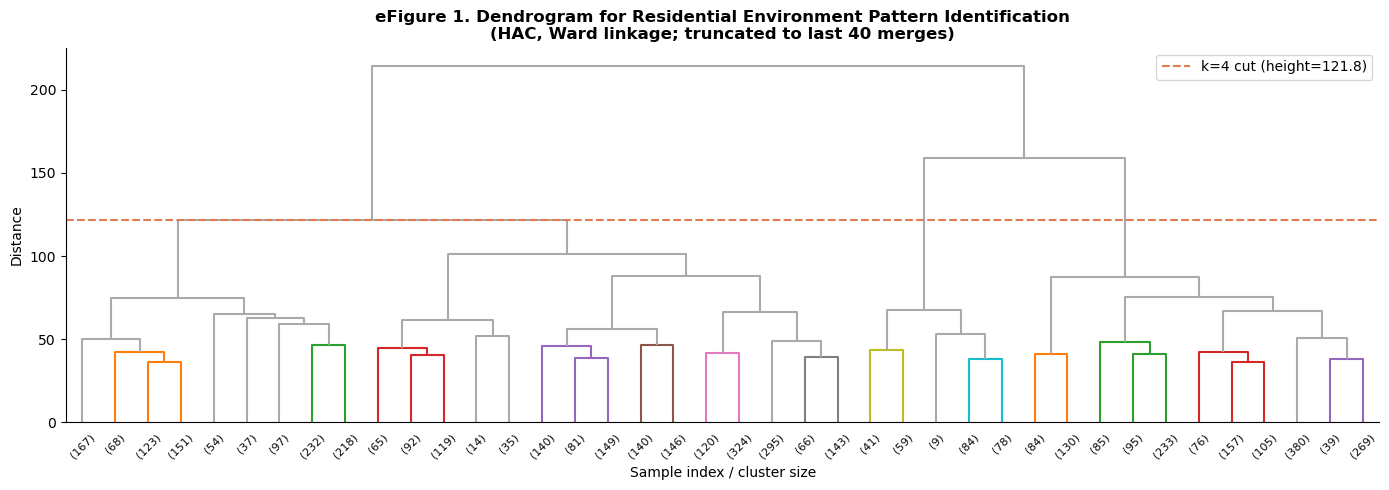


eFig 1 (dendrogram) saved.


In [8]:
# ════════════════════════════════════════════════════════════════
# 6. Supplementary Figure 1: Dendrogram
# ════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor('white'); ax.set_facecolor('white')
dendrogram(Z, ax=ax, truncate_mode='lastp', p=40,
           color_threshold=0.4 * Z[-3, 2],
           above_threshold_color='#AAAAAA', leaf_font_size=8)
ax.axhline(Z[-3, 2], color='#E07B54', linewidth=1.5, linestyle='--',
           label=f'k=4 cut (height={Z[-3,2]:.1f})')
ax.set_title('eFigure 1. Dendrogram for Residential Environment Pattern Identification\n'
             '(HAC, Ward linkage; truncated to last 40 merges)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Sample index / cluster size', fontsize=10)
ax.set_ylabel('Distance', fontsize=10)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('efig1_dendrogram.png', dpi=500, bbox_inches='tight', facecolor='white')

plt.show()

plt.close()
print("\neFig 1 (dendrogram) saved.")

findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.


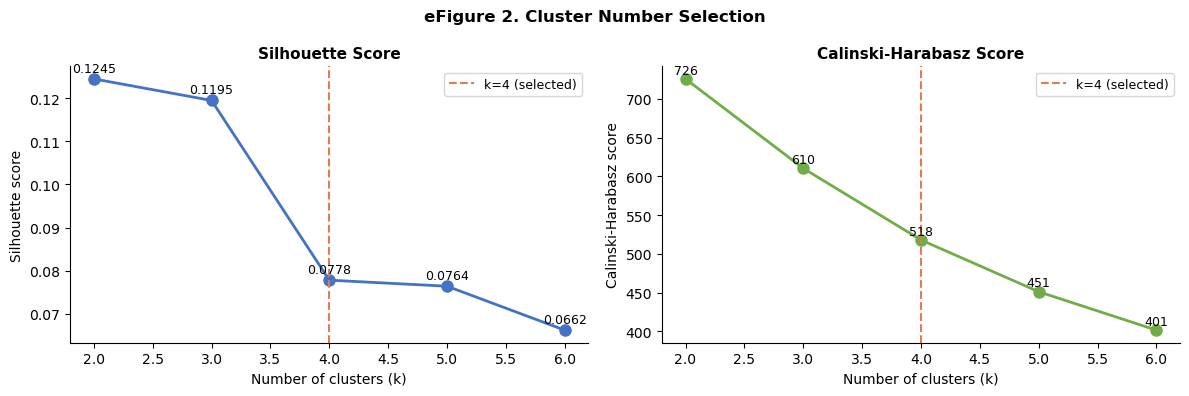

eFig 2 (scores) saved.


In [9]:
# ════════════════════════════════════════════════════════════════
# 7. Supplementary Figure 2: Cluster Evaluation
# ════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.patch.set_facecolor('white')
ks   = list(range(2, 7))
sils = [hac_scores[k]['silhouette'] for k in ks]
cals = [hac_scores[k]['calinski']   for k in ks]

for ax, vals, title, ylabel, col in zip(
        axes, [sils, cals],
        ['Silhouette Score', 'Calinski-Harabasz Score'],
        ['Silhouette score', 'Calinski-Harabasz score'],
        ['#4472C4', '#70AD47']):
    ax.plot(ks, vals, 'o-', color=col, linewidth=2, markersize=8)
    ax.axvline(N_CLUSTERS, color='#E07B54', linestyle='--', linewidth=1.5,
               label=f'k={N_CLUSTERS} (selected)')
    for k, v in zip(ks, vals):
        ax.text(k, v + (0.001 if 'Sil' in title else 3),
                f'{v:.4f}' if 'Sil' in title else f'{v:.0f}',
                ha='center', va='bottom', fontsize=9)
    ax.set_xlabel('Number of clusters (k)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.set_facecolor('white')

fig.suptitle('eFigure 2. Cluster Number Selection', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('efig2_scores.png', dpi=500, bbox_inches='tight', facecolor='white')

plt.show()
plt.close()
print("eFig 2 (scores) saved.")


t-SNE on n=10000...


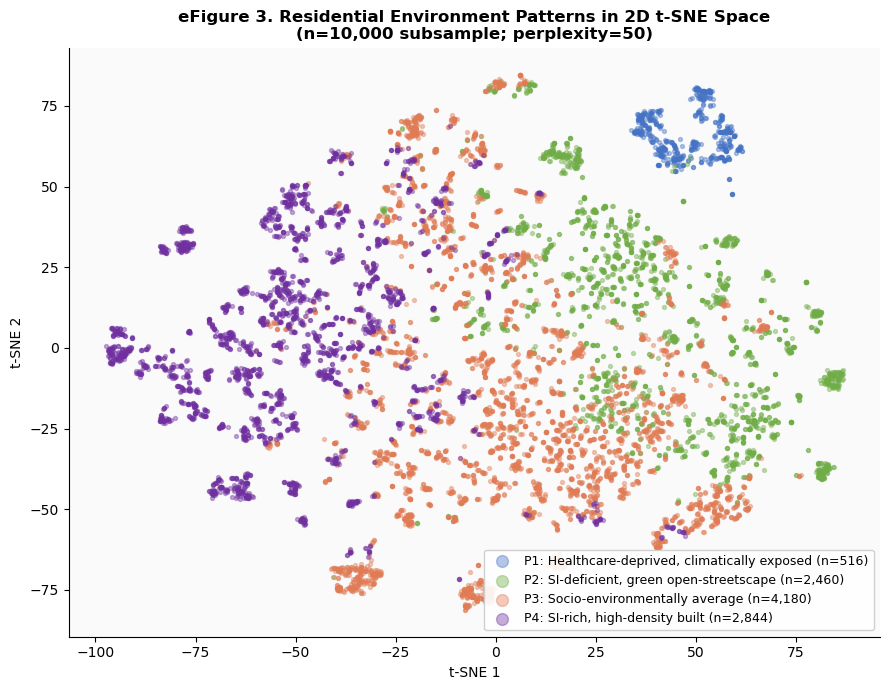

eFig 3 (t-SNE) saved.


In [10]:
# ════════════════════════════════════════════════════════════════
# 8. Supplementary Figure 3: t-SNE
# ════════════════════════════════════════════════════════════════

np.random.seed(RANDOM_SEED)
tsne_idx    = np.random.choice(len(df_clean), TSNE_SAMPLE_N, replace=False)
X_tsne_in   = X_final[tsne_idx]
labels_tsne = df_clean['cluster'].values[tsne_idx]

print(f"\nt-SNE on n={TSNE_SAMPLE_N}...")
import sklearn
_tsne_iter_kwarg = ('max_iter' if tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 5)
                    else 'n_iter')
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=50,
            learning_rate='auto', **{_tsne_iter_kwarg: 1000})
X_2d = tsne.fit_transform(X_tsne_in)

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('white'); ax.set_facecolor('#FAFAFA')
for k in range(1, N_CLUSTERS+1):
    mask = labels_tsne == k
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], c=PAT_COLORS[str(k)], alpha=0.4,
               s=8, label=f'P{k}: {CLUSTER_NAMES[k].split(":")[1].strip()} (n={mask.sum():,})',
               rasterized=True)
ax.set_title('eFigure 3. Residential Environment Patterns in 2D t-SNE Space\n'
             f'(n={TSNE_SAMPLE_N:,} subsample; perplexity=50)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('t-SNE 1', fontsize=10); ax.set_ylabel('t-SNE 2', fontsize=10)
ax.legend(fontsize=9, markerscale=3, framealpha=0.9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('efig3_tsne.png', dpi=500, bbox_inches='tight', facecolor='white')

plt.show()
plt.close()
print("eFig 3 (t-SNE) saved.")


5-fold CV clustering stability check...
  Fold 1: P1=100.0%  P2=86.9%  P3=73.0%  P4=99.7%
  Fold 2: P1=100.0%  P2=87.1%  P3=72.9%  P4=99.7%
  Fold 3: P1=100.0%  P2=87.6%  P3=73.2%  P4=99.7%
  Fold 4: P1=100.0%  P2=87.7%  P3=73.6%  P4=99.7%
  Fold 5: P1=100.0%  P2=87.2%  P3=72.9%  P4=99.7%
Summary diagonal (mean [95%CI]):
  P1: 1.00 [1.00, 1.00]
  P2: 0.87 [0.87, 0.88]
  P3: 0.73 [0.73, 0.73]
  P4: 1.00 [1.00, 1.00]


findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.


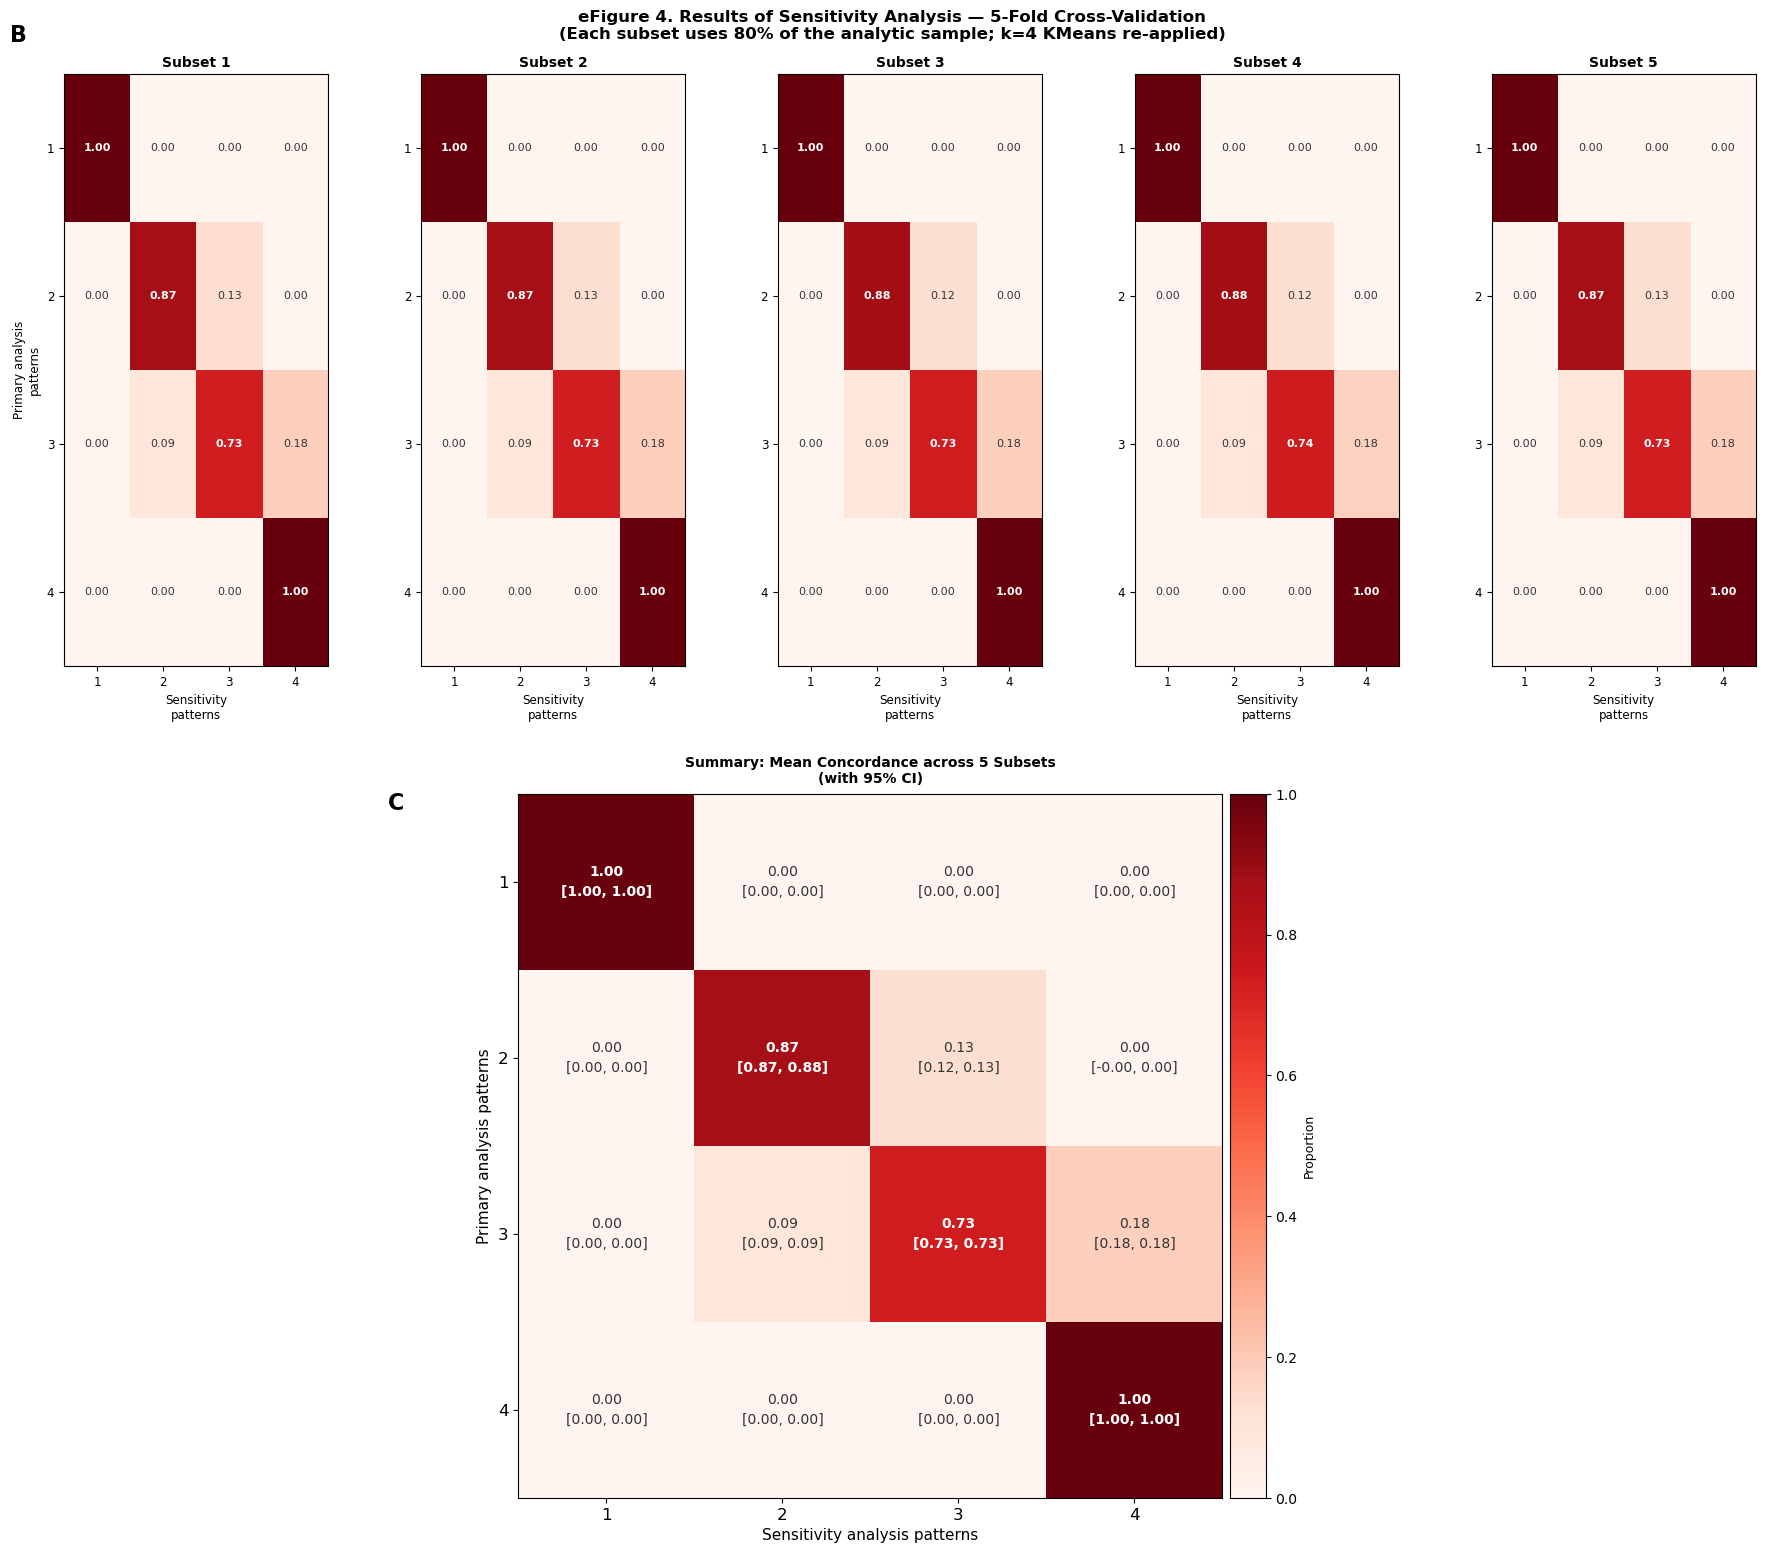

5-fold CV figure saved: sensitivity_5fold_cv.png


In [11]:
# ════════════════════════════════════════════════════════════════
# 9. Sensitivity 1: 5-fold CV clustering stability
# ════════════════════════════════════════════════════════════════

print("\n5-fold CV clustering stability check...")

N_FULL       = len(df_clean)
labels_full  = df_clean['cluster'].values - 1   # 0-indexed for ARI

np.random.seed(RANDOM_SEED)
fold_indices = np.array_split(np.random.permutation(N_FULL), 5)

fold_cms   = []   # list of 4×4 proportion matrices
fold_diags = []   # list of 4-element diagonal vectors

def _named_labels_cv(raw_labels, df_sub):
    """Map 0-indexed KMeans labels to canonical 0-3 ordering."""
    tmp = df_sub.copy(); tmp['cl'] = raw_labels
    rural   = tmp.groupby('cl')['acc'].mean().idxmin()
    urban   = tmp.groupby('cl')['pop'].mean().idxmax()
    rem     = [k for k in range(4) if k not in [rural, urban]]
    open_ss = tmp.groupby('cl')['NDVI'].mean()[rem].idxmax()
    sub_k   = [k for k in rem if k != open_ss][0]
    # P2 = SI-deficient, green open-streetscape 
    # P3 = Socio-environmentally average 
    remap   = {rural: 0, open_ss: 1, sub_k: 2, urban: 3}
    return np.array([remap[l] for l in raw_labels])

# Re-derive named labels for full sample
labels_full_named = _named_labels_cv(labels_full, df_clean)

for fold_i in range(5):
    use_idx = np.concatenate([fold_indices[j] for j in range(5) if j != fold_i])
    X_sub   = X_final[use_idx]
    df_sub  = df_clean.iloc[use_idx].reset_index(drop=True)

    km_cv   = KMeans(n_clusters=N_CLUSTERS, random_state=fold_i,
                     n_init=N_INIT_KM, max_iter=300)
    raw_sub = km_cv.fit_predict(X_sub)
    lbl_sub = _named_labels_cv(raw_sub, df_sub)

    ref_sub = labels_full_named[use_idx]

    # Confusion matrix (row=primary, col=CV)
    cm = np.zeros((4, 4))
    for pi in range(4):
        mask  = ref_sub == pi
        total = mask.sum()
        if total == 0:
            continue
        for si in range(4):
            cm[pi, si] = (lbl_sub[mask] == si).sum() / total
    fold_cms.append(cm)
    fold_diags.append([cm[i, i] for i in range(4)])
    diag_str = '  '.join(f'P{i+1}={cm[i,i]*100:.1f}%' for i in range(4))
    print(f"  Fold {fold_i+1}: {diag_str}")

# Summary confusion matrix (mean ± 95% CI across 5 folds)
cms_arr  = np.array(fold_cms)   # (5, 4, 4)
mean_cm  = cms_arr.mean(axis=0)
std_cm   = cms_arr.std(axis=0)
from scipy.stats import t as _t
t_crit   = _t.ppf(0.975, df=4)
ci_lo_cm = mean_cm - t_crit * std_cm / np.sqrt(5)
ci_hi_cm = mean_cm + t_crit * std_cm / np.sqrt(5)

print("Summary diagonal (mean [95%CI]):")
for i in range(4):
    print(f"  P{i+1}: {mean_cm[i,i]:.2f} [{ci_lo_cm[i,i]:.2f}, {ci_hi_cm[i,i]:.2f}]")

# eFigure4: 5-fold CV (panel B = 5 fold CMs, panel C = summary)
fig = plt.figure(figsize=(18, 16), facecolor='white')
gs_top = mgridspec.GridSpec(1, 5, figure=fig,
                             left=0.04, right=0.98,
                             top=0.93, bottom=0.56,
                             wspace=0.35)
gs_bot = mgridspec.GridSpec(1, 1, figure=fig,
                             left=0.20, right=0.80,
                             top=0.48, bottom=0.04)
top_axes = [fig.add_subplot(gs_top[0, i]) for i in range(5)]
ax_sum   = fig.add_subplot(gs_bot[0, 0])

cmap_r = plt.cm.Reds
vmin, vmax = 0, 1

for fi, (ax, cm) in enumerate(zip(top_axes, fold_cms)):
    im = ax.imshow(cm, cmap=cmap_r, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_title(f'Subset {fi+1}', fontsize=10, fontweight='bold', pad=5)
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(['1','2','3','4'])
    ax.set_yticklabels(['1','2','3','4'])
    ax.tick_params(axis='both', labelsize=8.5)
    if fi == 0:
        ax.set_ylabel('Primary analysis\npatterns', fontsize=8.5)
    ax.set_xlabel('Sensitivity\npatterns', fontsize=8.5)
    for ii in range(4):
        for jj in range(4):
            v   = cm[ii, jj]
            col = 'white' if v > 0.55 else '#333333'
            ax.text(jj, ii, f'{v:.2f}', ha='center', va='center',
                    fontsize=8, color=col,
                    fontweight='bold' if ii == jj else 'normal')

# Summary panel
im2 = ax_sum.imshow(mean_cm, cmap=cmap_r, vmin=vmin, vmax=vmax, aspect='equal')
ax_sum.set_title('Summary: Mean Concordance across 5 Subsets\n(with 95% CI)',
                 fontsize=10, fontweight='bold', pad=8)
ax_sum.set_xticks(range(4)); ax_sum.set_yticks(range(4))
ax_sum.set_xticklabels(['1','2','3','4'])
ax_sum.set_yticklabels(['1','2','3','4'])
ax_sum.tick_params(axis='both', labelsize=12)
ax_sum.set_xlabel('Sensitivity analysis patterns', fontsize=11)
ax_sum.set_ylabel('Primary analysis patterns', fontsize=11)
for ii in range(4):
    for jj in range(4):
        v   = mean_cm[ii, jj]
        lo  = ci_lo_cm[ii, jj]
        hi  = ci_hi_cm[ii, jj]
        col = 'white' if v > 0.55 else '#333333'
        fw  = 'bold' if ii == jj else 'normal'
        ax_sum.text(jj, ii, f'{v:.2f}\n[{lo:.2f}, {hi:.2f}]',
                    ha='center', va='center', fontsize=10,
                    color=col, fontweight=fw, linespacing=1.5)

divider = make_axes_locatable(ax_sum)
cax     = divider.append_axes('right', size='5%', pad=0.08)
cbar    = fig.colorbar(im2, cax=cax)
cbar.set_label('Proportion', fontsize=9)
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

fig.text(0.5, 0.97,
         'eFigure 4. Results of Sensitivity Analysis — 5-Fold Cross-Validation\n'
         '(Each subset uses 80% of the analytic sample; k=4 KMeans re-applied)',
         ha='center', va='top', fontsize=12, fontweight='bold')
fig.text(0.01, 0.95, 'B', fontsize=16, fontweight='bold')
fig.text(0.22, 0.47, 'C', fontsize=16, fontweight='bold')

plt.savefig('sensitivity1_5fold_cv.png', dpi=500,
            bbox_inches='tight', facecolor='white')

plt.show()
plt.close()
print("5-fold CV figure saved: sensitivity_5fold_cv.png")


Unique residential location sensitivity check...
  Unique residential locations: 72,281
  Location-level silhouette: 0.1054
  Location pattern %: {'P1': 5.9, 'P2': 26.5, 'P3': 30.9, 'P4': 36.7}
  Confusion matrix diagonal: ['P1=99.9%', 'P2=91.3%', 'P3=62.2%', 'P4=95.5%']
  Running t-SNE on unique locations (n=8,000)...


findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Carlito'] not found. Falling back to DejaVu Sans.


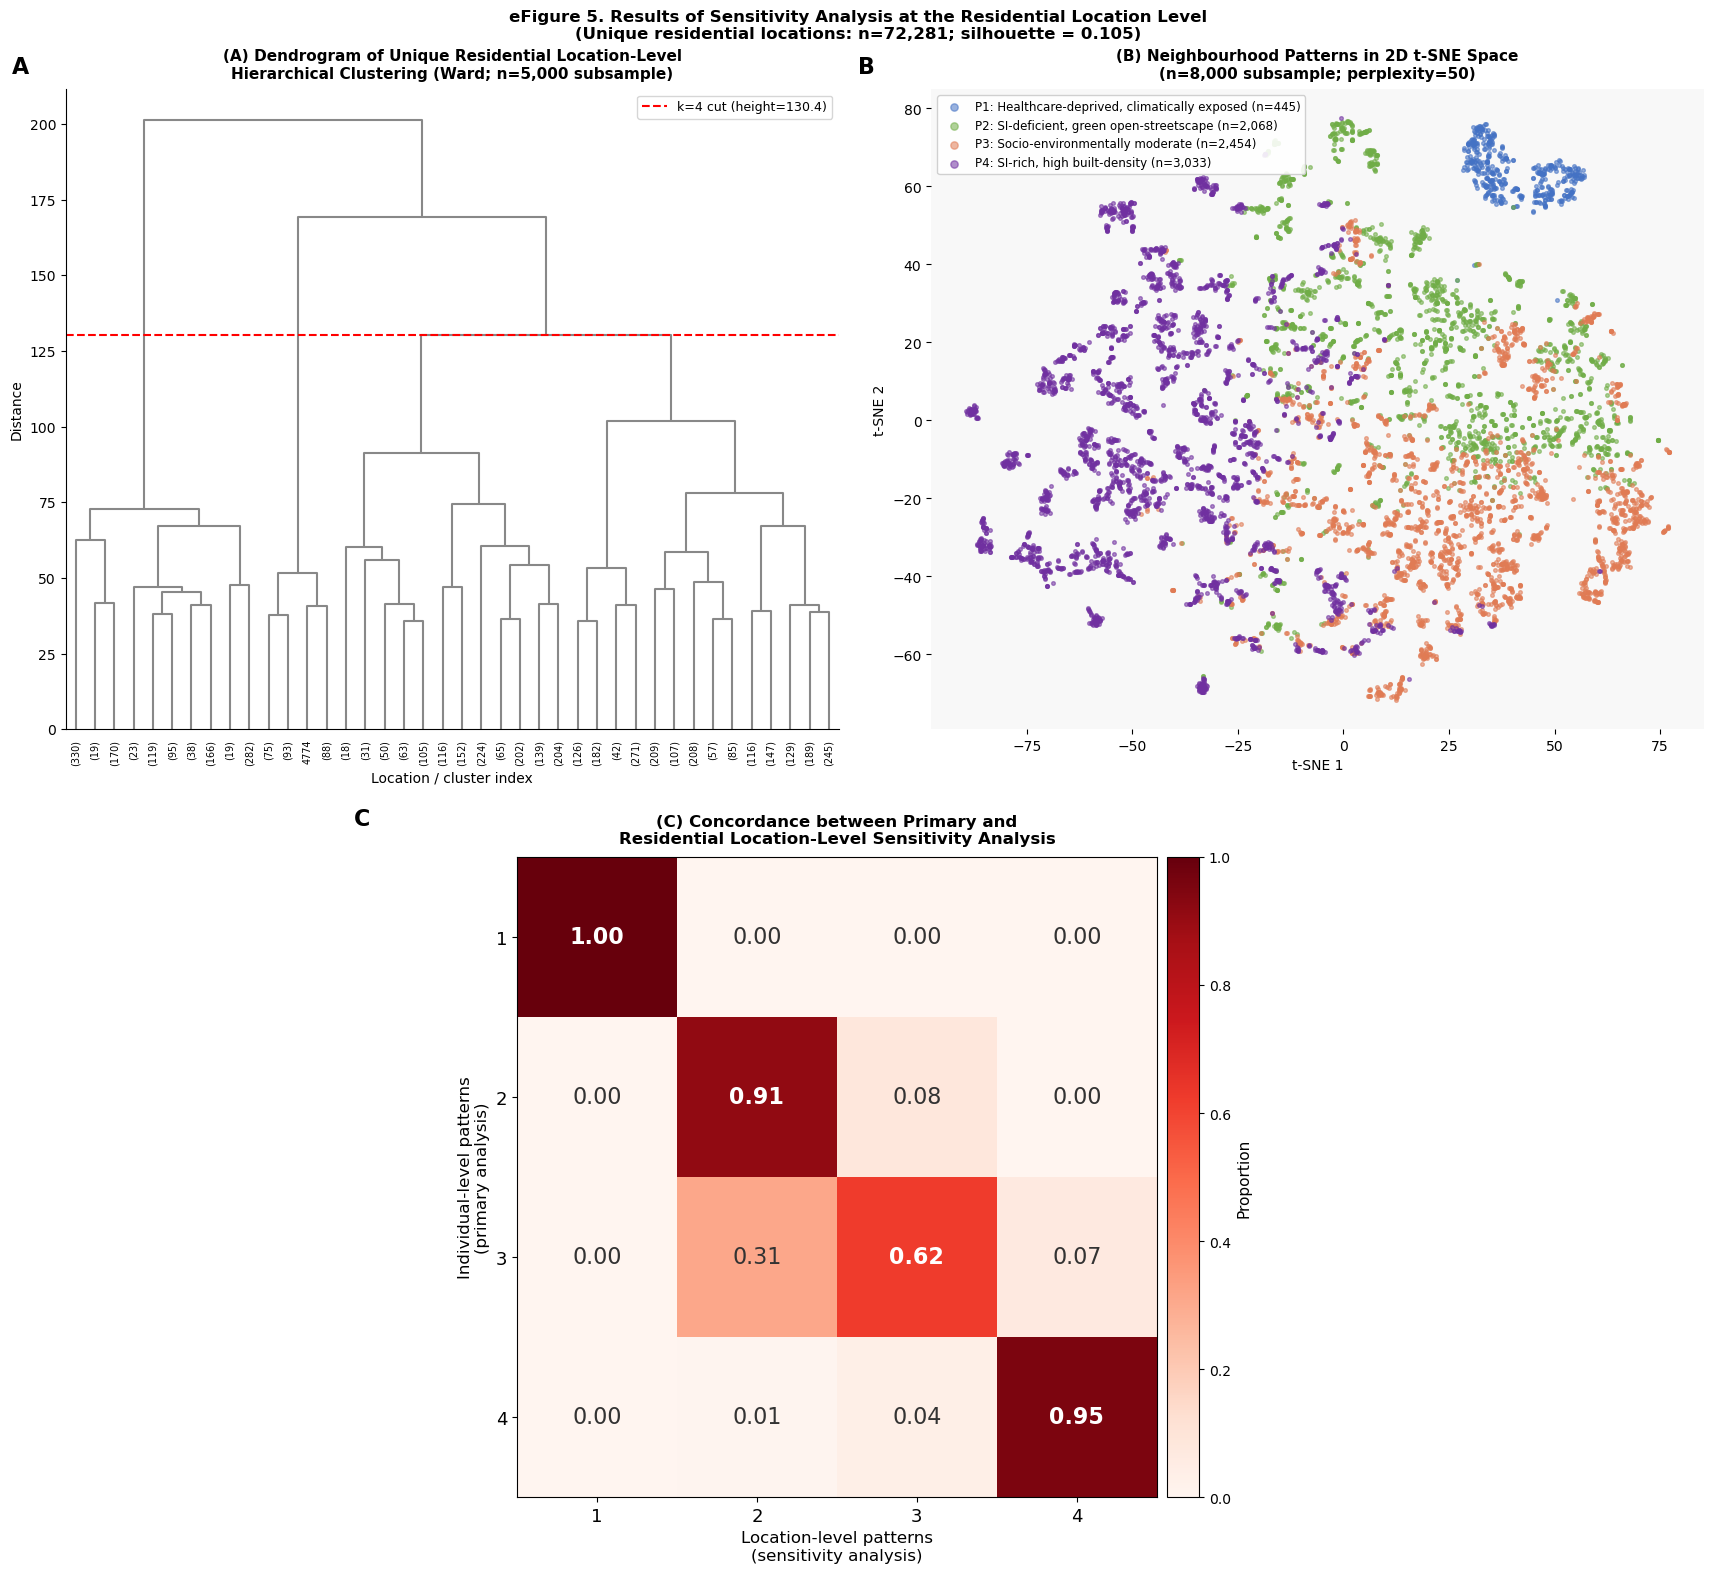

  Location sensitivity figure saved: sensitivity_location_level.png


In [12]:
# ════════════════════════════════════════════════════════════════
# 10. Sensitivity 2: unique residential location (72,281 coords)
# ════════════════════════════════════════════════════════════════

print("\nUnique residential location sensitivity check...")

if 'log' not in df_clean.columns or 'lat' not in df_clean.columns:
    print("  WARNING: 'log'/'lat' not found — skipping location sensitivity.")
else:
    N_LOC_HAC = 5000   # subsample for HAC dendrogram

    # Exact-coordinate deduplication
    df_clean['_loc_key'] = (df_clean['log'].astype(str) + '_' +
                             df_clean['lat'].astype(str))

    ALL_CLUST_VARS = NE_VARS_BASE + ['scene_PC1', 'scene_PC2']
    loc_means = df_clean.groupby('_loc_key')[ALL_CLUST_VARS + ['cluster']].agg(
        {**{v: 'mean' for v in ALL_CLUST_VARS},
         'cluster': lambda x: x.mode()[0]}
    ).reset_index()

    n_locs = len(loc_means)
    print(f"  Unique residential locations: {n_locs:,}")

    scaler_loc = StandardScaler()
    X_loc      = scaler_loc.fit_transform(loc_means[ALL_CLUST_VARS])

    # HAC on 5,000-location subsample for dendrogram
    np.random.seed(RANDOM_SEED)
    hac_loc_idx = np.random.choice(n_locs, min(N_LOC_HAC, n_locs), replace=False)
    Z_loc       = scipy_linkage(X_loc[hac_loc_idx], method='ward')
    cut_h_loc   = Z_loc[-3, 2]

    # KMeans on all unique locations
    km_loc     = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_SEED,
                        n_init=N_INIT_KM, max_iter=300)
    raw_loc    = km_loc.fit_predict(X_loc)
    lbl_loc    = _named_labels_cv(raw_loc, loc_means)

    sil_loc = silhouette_score(X_loc, raw_loc,
                                sample_size=5000, random_state=RANDOM_SEED)
    print(f"  Location-level silhouette: {sil_loc:.4f}")
    print("  Location pattern %:",
          {f'P{i+1}': round((lbl_loc==i).sum()/n_locs*100, 1) for i in range(4)})

    # Map back to individuals → confusion matrix
    loc_pattern_map   = dict(zip(loc_means['_loc_key'], lbl_loc))
    lbl_loc_indiv     = df_clean['_loc_key'].map(loc_pattern_map).values.astype(int)
    ref_named         = labels_full_named   # primary analysis labels

    cm_loc = np.zeros((4, 4))
    for pi in range(4):
        mask  = ref_named == pi
        total = mask.sum()
        if total == 0:
            continue
        for si in range(4):
            cm_loc[pi, si] = (lbl_loc_indiv[mask] == si).sum() / total

    print("  Confusion matrix diagonal:",
          [f'P{i+1}={cm_loc[i,i]*100:.1f}%' for i in range(4)])

    # t-SNE on unique locations (subsample up to 8,000 from the ~72k locations)
    np.random.seed(RANDOM_SEED)
    tsne_loc_idx = np.random.choice(n_locs, min(8000, n_locs), replace=False)
    print(f"  Running t-SNE on unique locations (n={len(tsne_loc_idx):,})...")
    tsne_loc = TSNE(n_components=2, perplexity=50,
                    random_state=RANDOM_SEED, **{_tsne_iter_kwarg: 1000})
    X_2d_loc = tsne_loc.fit_transform(X_loc[tsne_loc_idx])
    lbl_tsne_loc = lbl_loc[tsne_loc_idx]

    # eFigure 5: 3-panel (A=dendrogram, B=t-SNE, C=confusion matrix) ──
    PAT_COLORS_TSNE = ['#4472C4', '#70AD47','#E07B54', '#7030A0']
    PAT_NAMES_TSNE  = ['P1: Healthcare-deprived, climatically exposed', 'P2: SI-deficient, green open-streetscape',
                        'P3: Socio-environmentally moderate', 'P4: SI-rich, high built-density']

    fig = plt.figure(figsize=(18, 16), facecolor='white')
    gs_top_l = mgridspec.GridSpec(1, 2, figure=fig,
                                   left=0.06, right=0.97,
                                   top=0.92, bottom=0.52, wspace=0.12)
    gs_bot_l = mgridspec.GridSpec(1, 1, figure=fig,
                                   left=0.25, right=0.75,
                                   top=0.44, bottom=0.04)
    ax_LA = fig.add_subplot(gs_top_l[0, 0])
    ax_LB = fig.add_subplot(gs_top_l[0, 1])
    ax_LC = fig.add_subplot(gs_bot_l[0, 0])

    # Panel A: Dendrogram
    dendrogram(Z_loc, ax=ax_LA, truncate_mode='lastp', p=40,
               leaf_rotation=90, leaf_font_size=7,
               above_threshold_color='#888888', color_threshold=0)
    ax_LA.axhline(cut_h_loc, color='red', linestyle='--', linewidth=1.5,
                  label=f'k=4 cut (height={cut_h_loc:.1f})')
    ax_LA.legend(fontsize=9, loc='upper right')
    ax_LA.set_xlabel('Location / cluster index', fontsize=10)
    ax_LA.set_ylabel('Distance', fontsize=10)
    ax_LA.set_title('(A) Dendrogram of Unique Residential Location-Level\n'
                    f'Hierarchical Clustering (Ward; n={N_LOC_HAC:,} subsample)',
                    fontsize=11, fontweight='bold', pad=8)
    ax_LA.spines['top'].set_visible(False); ax_LA.spines['right'].set_visible(False)

    # Panel B: t-SNE
    n_per_pat_loc = {p: (lbl_tsne_loc==p).sum() for p in range(4)}
    for pi in range(4):
        mask = lbl_tsne_loc == pi
        ax_LB.scatter(X_2d_loc[mask, 0], X_2d_loc[mask, 1],
                      c=PAT_COLORS_TSNE[pi], s=7, alpha=0.55,
                      label=f'{PAT_NAMES_TSNE[pi]} (n={n_per_pat_loc[pi]:,})',
                      rasterized=True)
    ax_LB.set_xlabel('t-SNE 1', fontsize=10)
    ax_LB.set_ylabel('t-SNE 2', fontsize=10)
    ax_LB.set_title(f'(B) Neighbourhood Patterns in 2D t-SNE Space\n'
                    f'(n={len(tsne_loc_idx):,} subsample; perplexity=50)',
                    fontsize=11, fontweight='bold', pad=8)
    ax_LB.legend(fontsize=8.5, framealpha=0.9, loc='upper left', markerscale=2)
    ax_LB.set_facecolor('#F8F8F8')
    for sp in ax_LB.spines.values():
        sp.set_visible(False)

    # Panel C: Confusion matrix 
    im_lc = ax_LC.imshow(cm_loc, cmap=plt.cm.Reds, vmin=0, vmax=1, aspect='equal')
    ax_LC.set_xticks(range(4)); ax_LC.set_yticks(range(4))
    ax_LC.set_xticklabels(['1','2','3','4'])
    ax_LC.set_yticklabels(['1','2','3','4'])
    ax_LC.tick_params(axis='both', labelsize=13)
    ax_LC.set_xlabel('Location-level patterns\n(sensitivity analysis)', fontsize=12)
    ax_LC.set_ylabel('Individual-level patterns\n(primary analysis)', fontsize=12)
    ax_LC.set_title('(C) Concordance between Primary and\n'
                    'Residential Location-Level Sensitivity Analysis',
                    fontsize=12, fontweight='bold', pad=10)
    for ii in range(4):
        for jj in range(4):
            v   = cm_loc[ii, jj]
            col = 'white' if v > 0.55 else '#333333'
            fw  = 'bold' if ii == jj else 'normal'
            ax_LC.text(jj, ii, f'{v:.2f}', ha='center', va='center',
                       fontsize=16, color=col, fontweight=fw)

    divider_lc = make_axes_locatable(ax_LC)
    cax_lc     = divider_lc.append_axes('right', size='5%', pad=0.10)
    cbar_lc    = fig.colorbar(im_lc, cax=cax_lc)
    cbar_lc.set_label('Proportion', fontsize=11)
    cbar_lc.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    cbar_lc.ax.tick_params(labelsize=10)

    fig.text(0.5, 0.97,
             'eFigure 5. Results of Sensitivity Analysis at the Residential Location Level\n'
             f'(Unique residential locations: n={n_locs:,}; silhouette = {sil_loc:.3f})',
             ha='center', va='top', fontsize=12, fontweight='bold')
    fig.text(0.03, 0.93, 'A', fontsize=16, fontweight='bold')
    fig.text(0.50, 0.93, 'B', fontsize=16, fontweight='bold')
    fig.text(0.22, 0.46, 'C', fontsize=16, fontweight='bold')

    plt.savefig('sensitivity2_location_level.png', dpi=500,
                bbox_inches='tight', facecolor='white')
    
    plt.show()
    plt.close()
    print("  Location sensitivity figure saved: sensitivity_location_level.png")

    # Cleanup temporary column
    df_clean.drop(columns=['_loc_key'], inplace=True)

In [13]:
# ════════════════════════════════════════════════════════════════
# 11. Disadvantaged % CSV
# ════════════════════════════════════════════════════════════════

ALL_CLUSTER_VARS = NE_VARS_BASE + ['scene_PC1', 'scene_PC2']
thresholds = {
    v: (df_clean[v].quantile(0.75) if DISADVANTAGED[v] == 1
        else df_clean[v].quantile(0.25))
    for v in ALL_CLUSTER_VARS
}

rows = []
for k in range(1, N_CLUSTERS+1):
    mask = df_clean['cluster'] == k
    sub  = df_clean[mask]
    row  = {'cluster': k, 'label': CLUSTER_NAMES[k], 'n': int(mask.sum())}
    for v in ALL_CLUSTER_VARS:
        d   = DISADVANTAGED[v]
        pct = ((sub[v] > thresholds[v]) if d == 1
                else (sub[v] < thresholds[v])).mean() * 100
        row[v] = round(pct, 1)
    rows.append(row)

df_dis = pd.DataFrame(rows)
df_dis.to_csv('disadvantaged_pct.csv', index=False)
print("\nDisadvantaged % CSV saved.")
df_dis


Disadvantaged % CSV saved.


,cluster,label,n,acc,accA,HEALTHCARE,culture,sports,bus,SUBWAY,...,D_house,beautiful,boring,livelier,depressing,safer,wealthier,senti_mean,scene_PC1,scene_PC2
0,1,"Pattern 1: Healthcare-deprived, climatically e...",15767,100.0,100.0,23.4,22.0,19.6,17.5,0.0,...,8.2,23.5,49.5,51.7,13.6,50.6,14.1,9.4,30.8,23.3
1,2,"Pattern 2: SI-deficient, green open-streetscape",78650,52.6,56.7,70.3,53.3,56.6,35.7,0.0,...,22.7,30.3,1.7,7.3,23.4,25.3,38.6,20.3,6.7,26.0
2,3,Pattern 3: Socio-environmentally average,131532,13.3,13.5,14.0,8.6,10.9,16.3,0.0,...,21.8,29.6,15.7,21.9,23.3,27.1,23.6,26.4,24.3,32.0
3,4,"Pattern 4: SI-rich, high-density built",90534,0.8,1.0,0.8,1.1,0.7,3.5,0.0,...,33.4,14.0,54.4,40.2,30.9,17.1,17.2,29.5,40.9,12.9


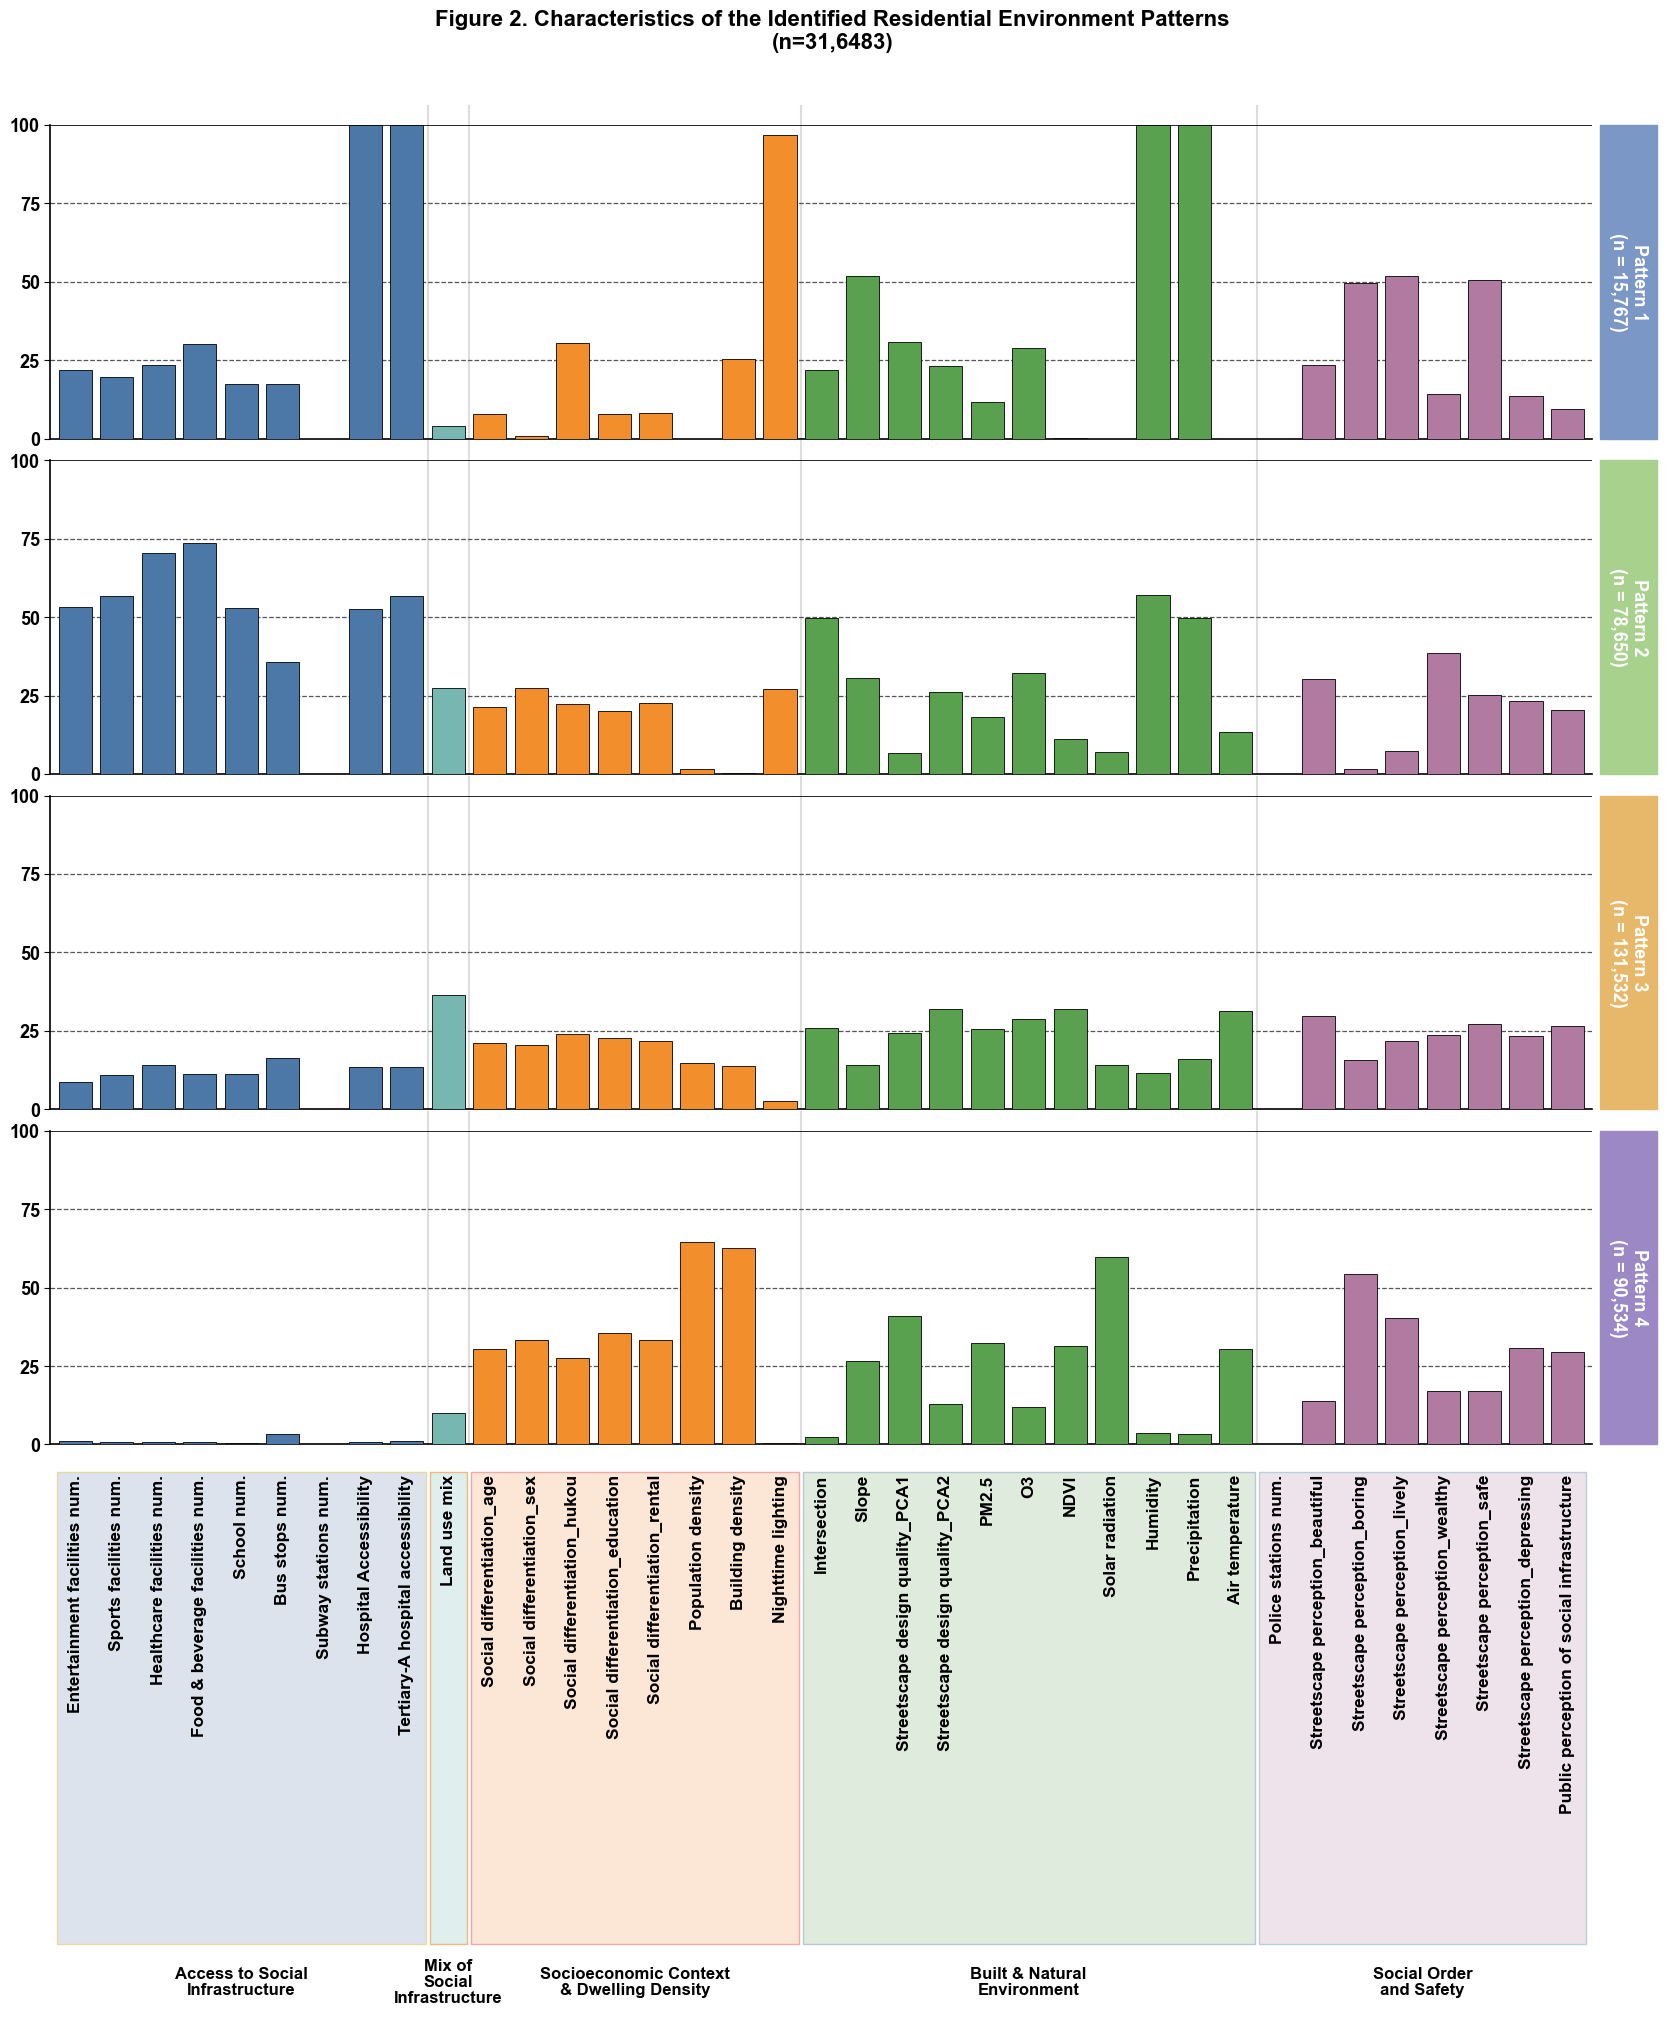

Saved: Figure2_patterns.png / Figure2_patterns.pdf


In [14]:
# ════════════════════════════════════════════════════════════════
# 12. Figure 2: Visualization for Disadvantaged % 
# ════════════════════════════════════════════════════════════════

# Note: Final Figure 2 were post-processed in PowerPoint for visual 
# (Added text annotations for specific environmental indicators)
# The code below reproduces the underlying data and preliminary plots.

plt.rcParams['font.family'] = 'Arial'  
plt.rcParams['font.weight'] = 'bold'

CSV_PATH = 'disadvantaged_pct.csv'
OUT_NAME = 'Figure2_patterns'

# Variable groups

GROUPS = {
    'Access to Social\nInfrastructure': [
        ('culture',    'Entertainment facilities num.'),
        ('sports',     'Sports facilities num.'),
        ('HEALTHCARE', 'Healthcare facilities num.'),
        ('FOOD',       'Food & beverage facilities num.'),
        ('SCHOOL',     'School num.'),
        ('bus',        'Bus stops num.'),
        ('SUBWAY',     'Subway stations num.'),
        ('acc',        'Hospital Accessibility'),
        ('accA',       'Tertiary-A hospital accessibility'),
    ],
    'Mix of\nSocial\nInfrastructure': [
        ('LAND_USE_MIX', 'Land use mix'),
    ],
    'Socioeconomic Context\n& Dwelling Density': [
        ('GD_age',  'Social differentiation_age'),
        ('D_sex',   'Social differentiation_sex'),
        ('D_hukou', 'Social differentiation_hukou'),
        ('GD_edu',  'Social differentiation_education'),
        ('D_house', 'Social differentiation_rental'),
        ('pop',     'Population density'),
        ('BD',      'Building density'),
        ('light',   'Nighttime lighting'),
    ],
    'Built & Natural\nEnvironment': [
        ('intersection', 'Intersection'),
        ('DEM30',        'Slope'),
        ('scene_PC1',    'Streetscape design quality_PCA1'),
        ('scene_PC2',    'Streetscape design quality_PCA2'),
        ('PM25_MEAN',    'PM2.5'),
        ('O3_MEAN',      'O3'),
        ('NDVI',      'NDVI'),
        ('sunshine',     'Solar radiation'),
        ('humid',        'Humidity'),
        ('rain',         'Precipitation'),
        ('temperature',  'Air temperature'),
    ],
    'Social Order\nand Safety': [
        ('police',     'Police stations num.'),
        ('beautiful',  'Streetscape perception_beautiful'),
        ('boring',     'Streetscape perception_boring'),
        ('livelier',   'Streetscape perception_lively'),
        ('wealthier',  'Streetscape perception_wealthy'),
        ('safer',      'Streetscape perception_safe'),
        ('depressing', 'Streetscape perception_depressing'),
        ('senti_mean', 'Public perception of social infrastructure'),
    ],
}

# bar colour, background-band colour, band edge colour
GROUP_STYLE = [
    ('#4C78A8', '#DCE3EC', '#E8D9A0'),
    ('#76B7B2', '#E0EEEE', '#F0B87A'),
    ('#F28E2B', '#FCE6D5', '#F0A8A8'),
    ('#59A14F', '#DFEBDC', '#B8C8D8'),
    ('#B07AA1', '#EEE3EA', '#B8D0D8'),
]

# Panel order (top → bottom) and side-label colours
ROW_ORDER  = [1, 2, 3, 4]
PAT_COLORS = {1: '#7B97C6', 2: '#A9D18E', 3: '#E8B86A', 4: '#9C88C4'}

# Data
df_plot = pd.read_csv(CSV_PATH).set_index('cluster')

cols, labels, bar_colors, bounds = [], [], [], []   # bounds = (start, end) per group
for gi, (grp, items) in enumerate(GROUPS.items()):
    start = len(cols)
    for c, lab in items:
        cols.append(c); labels.append(lab); bar_colors.append(GROUP_STYLE[gi][0])
    bounds.append((start, len(cols)))
missing = [c for c in cols if c not in df_plot.columns]
if missing:
    raise KeyError(f'Columns not found in {CSV_PATH}: {missing}')
N = len(cols)

# Figure layout
fig = plt.figure(figsize=(17, 21), facecolor='white')
gs = GridSpec(5, 2, figure=fig,
              height_ratios=[1, 1, 1, 1, 1.75], width_ratios=[60, 2.2],
              hspace=0.06, wspace=0.01,
              left=0.04, right=0.985, top=0.93, bottom=0.03)

fig.suptitle('Figure 2. Characteristics of the Identified Residential Environment Patterns\n'
             '(n=31,6483)', fontsize=16, fontweight='bold', y=0.985)

xlim = (-0.6, N - 0.4)
sep_x = [b[1] - 0.5 for b in bounds[:-1]]          # vertical separators between groups

for ri, k in enumerate(ROW_ORDER):
    ax = fig.add_subplot(gs[ri, 0])
    vals = df_plot.loc[k, cols].astype(float).values

    ax.bar(range(N), vals, width=0.8, color=bar_colors,
           edgecolor='black', linewidth=0.6, zorder=3)
    for y in (25, 50, 75):
        ax.axhline(y, color='#555555', ls='--', lw=0.9, zorder=1)
    ax.axhline(100, color='black', lw=1.2, zorder=1)
    for x in sep_x:
        ax.plot([x, x], [0, 106], color='#DDDDDD', lw=1.5, clip_on=False, zorder=0)

    ax.set_xlim(*xlim); ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(axis='y', labelsize=13, length=4)
    for t in ax.get_yticklabels():
        t.set_fontweight('bold')
    ax.set_xticks([])
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)

    # side label
    sax = fig.add_subplot(gs[ri, 1])
    sax.set_axis_off()
    sax.add_patch(Rectangle((0, 0), 1, 1, transform=sax.transAxes,
                            color=PAT_COLORS[k], clip_on=False))
    sax.text(0.5, 0.5, f'Pattern {k}\n(n = {int(df_plot.loc[k, "n"]):,})',
             rotation=270, ha='center', va='center',
             color='white', fontsize=13, fontweight='bold', transform=sax.transAxes)

# Bottom panel: coloured bands, variable labels, group titles
lax = fig.add_subplot(gs[4, 0])
lax.set_xlim(*xlim); lax.set_ylim(0, 1)
lax.set_axis_off()

for gi, (start, end) in enumerate(bounds):
    _, band, edge = GROUP_STYLE[gi]
    lax.add_patch(Rectangle((start - 0.45, 0.13), (end - start) - 0.1, 0.86,
                            facecolor=band, edgecolor=edge, lw=1.0))
    lax.text((start + end - 1) / 2, 0.06, list(GROUPS)[gi],
             ha='center', va='center', fontsize=12, fontweight='bold', linespacing=1.1)

for i, lab in enumerate(labels):
    lax.text(i, 0.985, lab, rotation=90, ha='center', va='top',
             fontsize=12.5, fontweight='bold')

plt.savefig(f'{OUT_NAME}.png', dpi=800, facecolor='white')
plt.savefig(f'{OUT_NAME}.pdf', facecolor='white')

plt.show()
plt.close()
print(f'Saved: {OUT_NAME}.png / {OUT_NAME}.pdf')


Generating pattern heatmap...


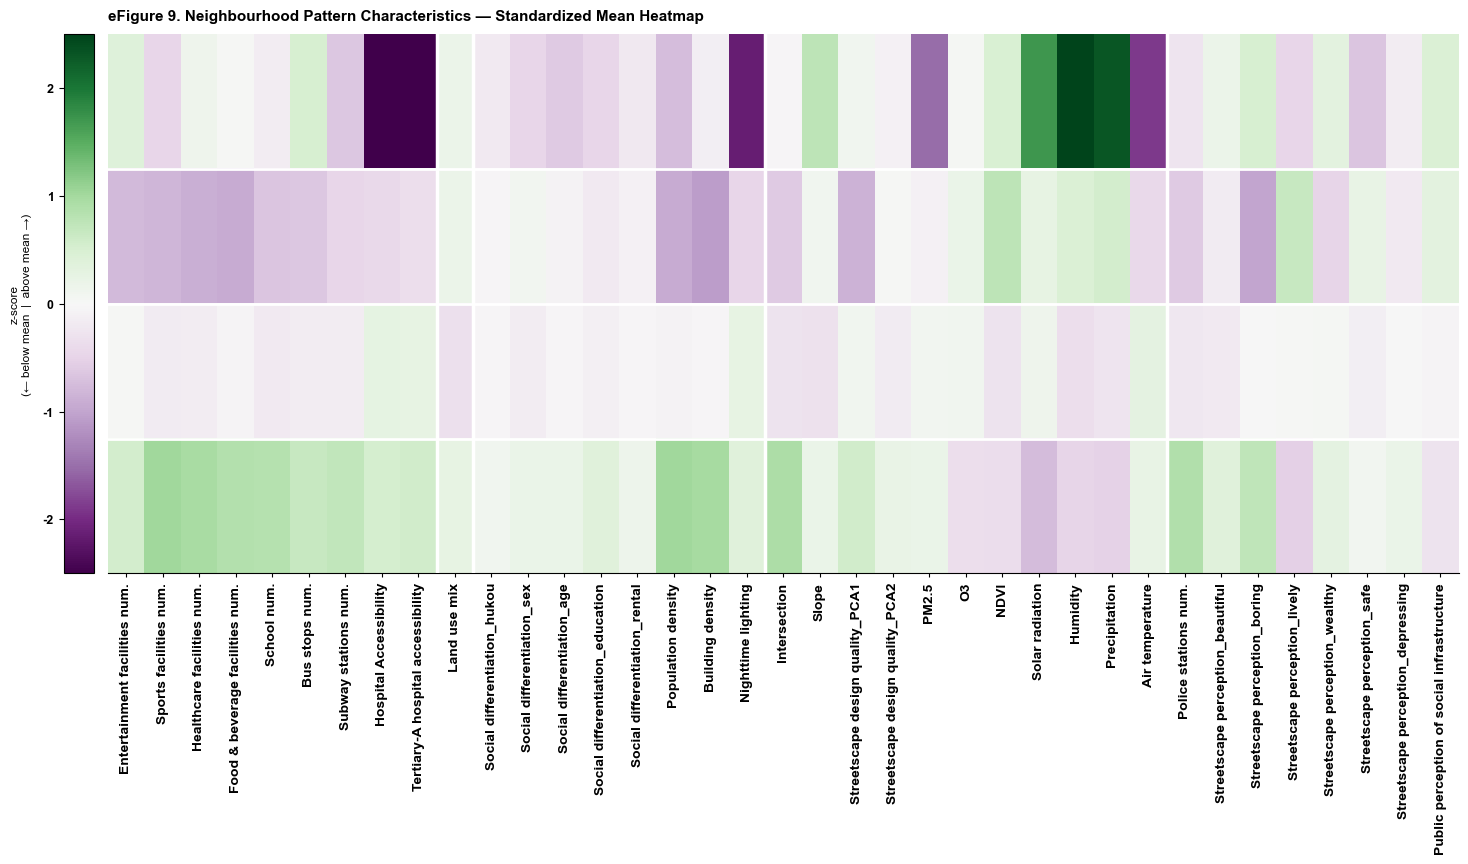

Pattern heatmap saved: pattern_heatmap.png


In [15]:
# ════════════════════════════════════════════════════════════════
# 13. Supplementary Figure 9: Pattern heatmap 
# ════════════════════════════════════════════════════════════════

print("\nGenerating pattern heatmap...")

HMAP_VAR_GROUPS = {
    'Access to Social Infrastructure': [
        'culture', 'sports', 'HEALTHCARE', 'FOOD', 'SCHOOL',
        'bus', 'SUBWAY', 'acc', 'accA'],
    'Mix of SI': ['LAND_USE_MIX'],
    'Socioeconomic Context & Dwelling Density': [
        'D_hukou', 'D_sex', 'GD_age', 'GD_edu', 'D_house', 'pop', 'BD', 'light'],
    'Building & Natural Environment': [
        'intersection', 'DEM30', 'scene_PC1', 'scene_PC2',
        'PM25_MEAN', 'O3_MEAN', 'NDVI', 'sunshine', 'humid', 'rain', 'temperature'],
    'Social Order & Safety': [
        'police', 'beautiful', 'boring', 'livelier',
        'wealthier', 'safer', 'depressing', 'senti_mean'],
}
HMAP_VAR_XLABELS = {
    'acc':         'Hospital Accessibility',
    'accA':        'Tertiary-A hospital accessibility',
    'HEALTHCARE':  'Healthcare facilities num.',
    'culture':     'Entertainment facilities num.',
    'sports':      'Sports facilities num.',
    'bus':         'Bus stops num.',
    'SUBWAY':      'Subway stations num.',
    'FOOD':        'Food & beverage facilities num.',
    'police':      'Police stations num.',
    'SCHOOL':      'School num.',
    'LAND_USE_MIX':'Land use mix',
    'pop':         'Population density',
    'BD':          'Building density',
    'intersection':'Intersection',
    'NDVI':     'NDVI',
    'DEM30':       'Slope',
    'sunshine':    'Solar radiation',
    'O3_MEAN':     'O3',
    'PM25_MEAN':   'PM2.5',
    'humid':       'Humidity',
    'rain':        'Precipitation',
    'temperature': 'Air temperature',
    'light':       'Nighttime lighting',
    'D_hukou':     'Social differentiation_hukou',
    'D_sex':       'Social differentiation_sex',
    'GD_age':      'Social differentiation_age',
    'GD_edu':      'Social differentiation_education',
    'D_house':     'Social differentiation_rental',
    'beautiful':   'Streetscape perception_beautiful',
    'boring':      'Streetscape perception_boring',
    'livelier':    'Streetscape perception_lively',
    'depressing':  'Streetscape perception_depressing',
    'safer':       'Streetscape perception_safe',
    'wealthier':   'Streetscape perception_wealthy',
    'senti_mean':  'Public perception of social infrastructure',
    'scene_PC1':   'Streetscape design quality_PCA1',
    'scene_PC2':   'Streetscape design quality_PCA2',
}

hmap_ordered = []
for grp, vs in HMAP_VAR_GROUPS.items():
    hmap_ordered.extend(vs)
hmap_labels = [HMAP_VAR_XLABELS.get(v, v) for v in hmap_ordered]
n_hmap_vars = len(hmap_ordered)

# Standardise all cluster vars
scaler_hmap = StandardScaler()
X_hmap_std  = scaler_hmap.fit_transform(df_clean[hmap_ordered])
df_hmap_std = pd.DataFrame(X_hmap_std, columns=hmap_ordered, index=df_clean.index)
df_hmap_std['cluster'] = df_clean['cluster'].values

# Compute z-score mean per pattern
Z_hmap = np.array([
    [df_hmap_std[df_hmap_std['cluster']==k][v].mean() for v in hmap_ordered]
    for k in range(1, N_CLUSTERS+1)
])  # shape (4, n_vars)

fig = plt.figure(figsize=(18, 7), facecolor='white')
gs_hmap = mgridspec.GridSpec(1, 2, figure=fig,
                               width_ratios=[0.5, 22], wspace=0.02)
ax_cb_hmap  = fig.add_subplot(gs_hmap[0, 0])
ax_heat     = fig.add_subplot(gs_hmap[0, 1])

cmap_hmap = plt.cm.PRGn
norm_hmap = mcolors.TwoSlopeNorm(vmin=-2.5, vcenter=0, vmax=2.5)

im_hmap = ax_heat.imshow(Z_hmap, aspect='auto', cmap=cmap_hmap,
                          norm=norm_hmap, interpolation='nearest')

# Row separators
for row_i in range(1, N_CLUSTERS):
    ax_heat.axhline(row_i - 0.5, color='white', linewidth=2, zorder=5)

# Group boundary lines
cumsum_h = 0
for gi, (grp, vs) in enumerate(HMAP_VAR_GROUPS.items()):
    cumsum_h += len(vs)
    if gi < len(HMAP_VAR_GROUPS) - 1:
        ax_heat.axvline(cumsum_h - 0.5, color='white', linewidth=2.5, zorder=5)

ax_heat.set_xticks(range(n_hmap_vars))
ax_heat.set_xticklabels(hmap_labels, rotation=90, ha='center', fontweight='bold')
ax_heat.tick_params(axis='x', which='both', length=3, width=0.8,
                    color='black', direction='out', bottom=True, top=False)
ax_heat.xaxis.set_ticks_position('bottom')
ax_heat.set_yticks([])
for sp in ['top', 'right', 'left']:
    ax_heat.spines[sp].set_visible(False)
ax_heat.spines['bottom'].set_linewidth(0.8)
ax_heat.set_facecolor('white')
ax_heat.set_title('eFigure 9. Neighbourhood Pattern Characteristics — Standardized Mean Heatmap',
                  fontsize=11, fontweight='bold', pad=10, loc='left')

# Colorbar on left
cb_hmap = fig.colorbar(im_hmap, cax=ax_cb_hmap, orientation='vertical')
cb_hmap.set_ticks([-2, -1, 0, 1, 2])
cb_hmap.set_ticklabels(['-2', '-1', '0', '1', '2'])
cb_hmap.ax.tick_params(labelsize=9)
ax_cb_hmap.yaxis.set_ticks_position('left')
ax_cb_hmap.yaxis.set_label_position('left')
cb_hmap.set_label('z-score\n(← below mean  |  above mean →)', fontsize=8.5, labelpad=8)

plt.savefig('efig9_pattern_heatmap.png', dpi=500, bbox_inches='tight', facecolor='white')

plt.show()
plt.close()
print("Pattern heatmap saved: pattern_heatmap.png")

In [16]:
# ════════════════════════════════════════════════════════════════
# 14. Sensitivity 3-1: LMM without school-level covariates
# ════════════════════════════════════════════════════════════════

print("\nLMM sensitivity1 check...")

df_clean['e2'] = np.where(df_clean['cluster']==2,  1, np.where(df_clean['cluster']==1, -1, 0))
df_clean['e3'] = np.where(df_clean['cluster']==3,  1, np.where(df_clean['cluster']==1, -1, 0))
df_clean['e4'] = np.where(df_clean['cluster']==4,  1, np.where(df_clean['cluster']==1, -1, 0))
ctrl_formula = ' + '.join(CTRL_VARS[:7])  # exclude street_id, code_county

all_results = {}
print(f"\nLMM effect coding (N={len(df_clean):,}):")
for out, lbl in zip(OUTCOMES, OUT_LABELS):
    formula = f'{out} ~ e2 + e3 + e4 + {ctrl_formula}'
    model   = smf.mixedlm(formula, data=df_clean, groups=df_clean['street_id'])
    res     = model.fit(method='lbfgs', maxiter=200, disp=False)

    row = {}
    for p, key in [('2', 'e2'), ('3', 'e3'), ('4', 'e4')]:
        b       = res.params[key]
        se      = res.bse[key]
        pv      = res.pvalues[key]
        ci_lo   = b - 1.96 * se
        ci_hi   = b + 1.96 * se
        sig     = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else ''
        row[p]  = {'b': round(b,3), 'ci_lo': round(ci_lo,3), 'ci_hi': round(ci_hi,3),
                   'p': round(pv,4), 'sig': sig}

    b1      = -(res.params['e2'] + res.params['e3'] + res.params['e4'])
    se1     = np.sqrt(res.bse['e2']**2 + res.bse['e3']**2 + res.bse['e4']**2)
    pv1     = 2 * (1 - sc_stats.norm.cdf(abs(b1 / se1)))
    ci_lo1  = b1 - 1.96 * se1
    ci_hi1  = b1 + 1.96 * se1
    sig1    = '***' if pv1<0.001 else '**' if pv1<0.01 else '*' if pv1<0.05 else ''
    row['1'] = {'b': round(b1,3), 'ci_lo': round(ci_lo1,3), 'ci_hi': round(ci_hi1,3),
                'p': round(pv1,4), 'sig': sig1}

    all_results[out] = row
    r = lambda p: row[p]
    print(f"  {lbl[:24]:24s}: "
          f"P1={r('1')['b']:+.3f}{r('1')['sig']:3s} "
          f"P2={r('2')['b']:+.3f}{r('2')['sig']:3s} "
          f"P3={r('3')['b']:+.3f}{r('3')['sig']:3s} "
          f"P4={r('4')['b']:+.3f}{r('4')['sig']:3s}")

# Save LMM table
pat_short = {'1': 'P1 Healthcare-deprived, climatically exposed', '2': 'P2 SI-deficient, green open-streetscape',
             '3': 'P3 Socio-environmentally average', '4': 'P4 SI-rich, high-density built'}
lmm_rows = []
for out, lbl in zip(OUTCOMES, OUT_LABELS):
    row = {'SDQ Outcome': lbl}
    for p in ['1', '2', '3', '4']:
        r = all_results[out][p]
        row[f'{pat_short[p]} β']     = r['b']
        row[f'{pat_short[p]} 95%CI'] = f"({r['ci_lo']},{r['ci_hi']})"
        row[f'{pat_short[p]} p']     = r['p']
        row[f'{pat_short[p]} sig']   = r['sig']
    lmm_rows.append(row)
pd.DataFrame(lmm_rows).to_csv('lmm_sensitivity1.csv', index=False)
print("LMM table saved: lmm_sensitivity1.csv")


LMM sensitivity1 check...

LMM effect coding (N=316,483):
  Emotional problems      : P1=+0.064*** P2=-0.023*** P3=-0.030*** P4=-0.011   
  Conduct problems        : P1=+0.029**  P2=-0.014**  P3=-0.013**  P4=-0.002   
  Hyperactivity/inattentio: P1=-0.012    P2=-0.003    P3=+0.001    P4=+0.014   
  Peer relationship proble: P1=+0.074*** P2=-0.018**  P3=-0.027*** P4=-0.029***
  Prosocial behaviour     : P1=-0.027    P2=+0.009    P3=+0.012    P4=+0.006   
  Total difficulties      : P1=+0.155*** P2=-0.058**  P3=-0.069*** P4=-0.028   
  Internalizing behaviour : P1=+0.138*** P2=-0.041*** P3=-0.057*** P4=-0.040***
  Externalizing behaviour : P1=+0.017    P2=-0.017    P3=-0.012    P4=+0.012   
LMM table saved: lmm_sensitivity1.csv



Generating eFigure 6 (forest plot)...


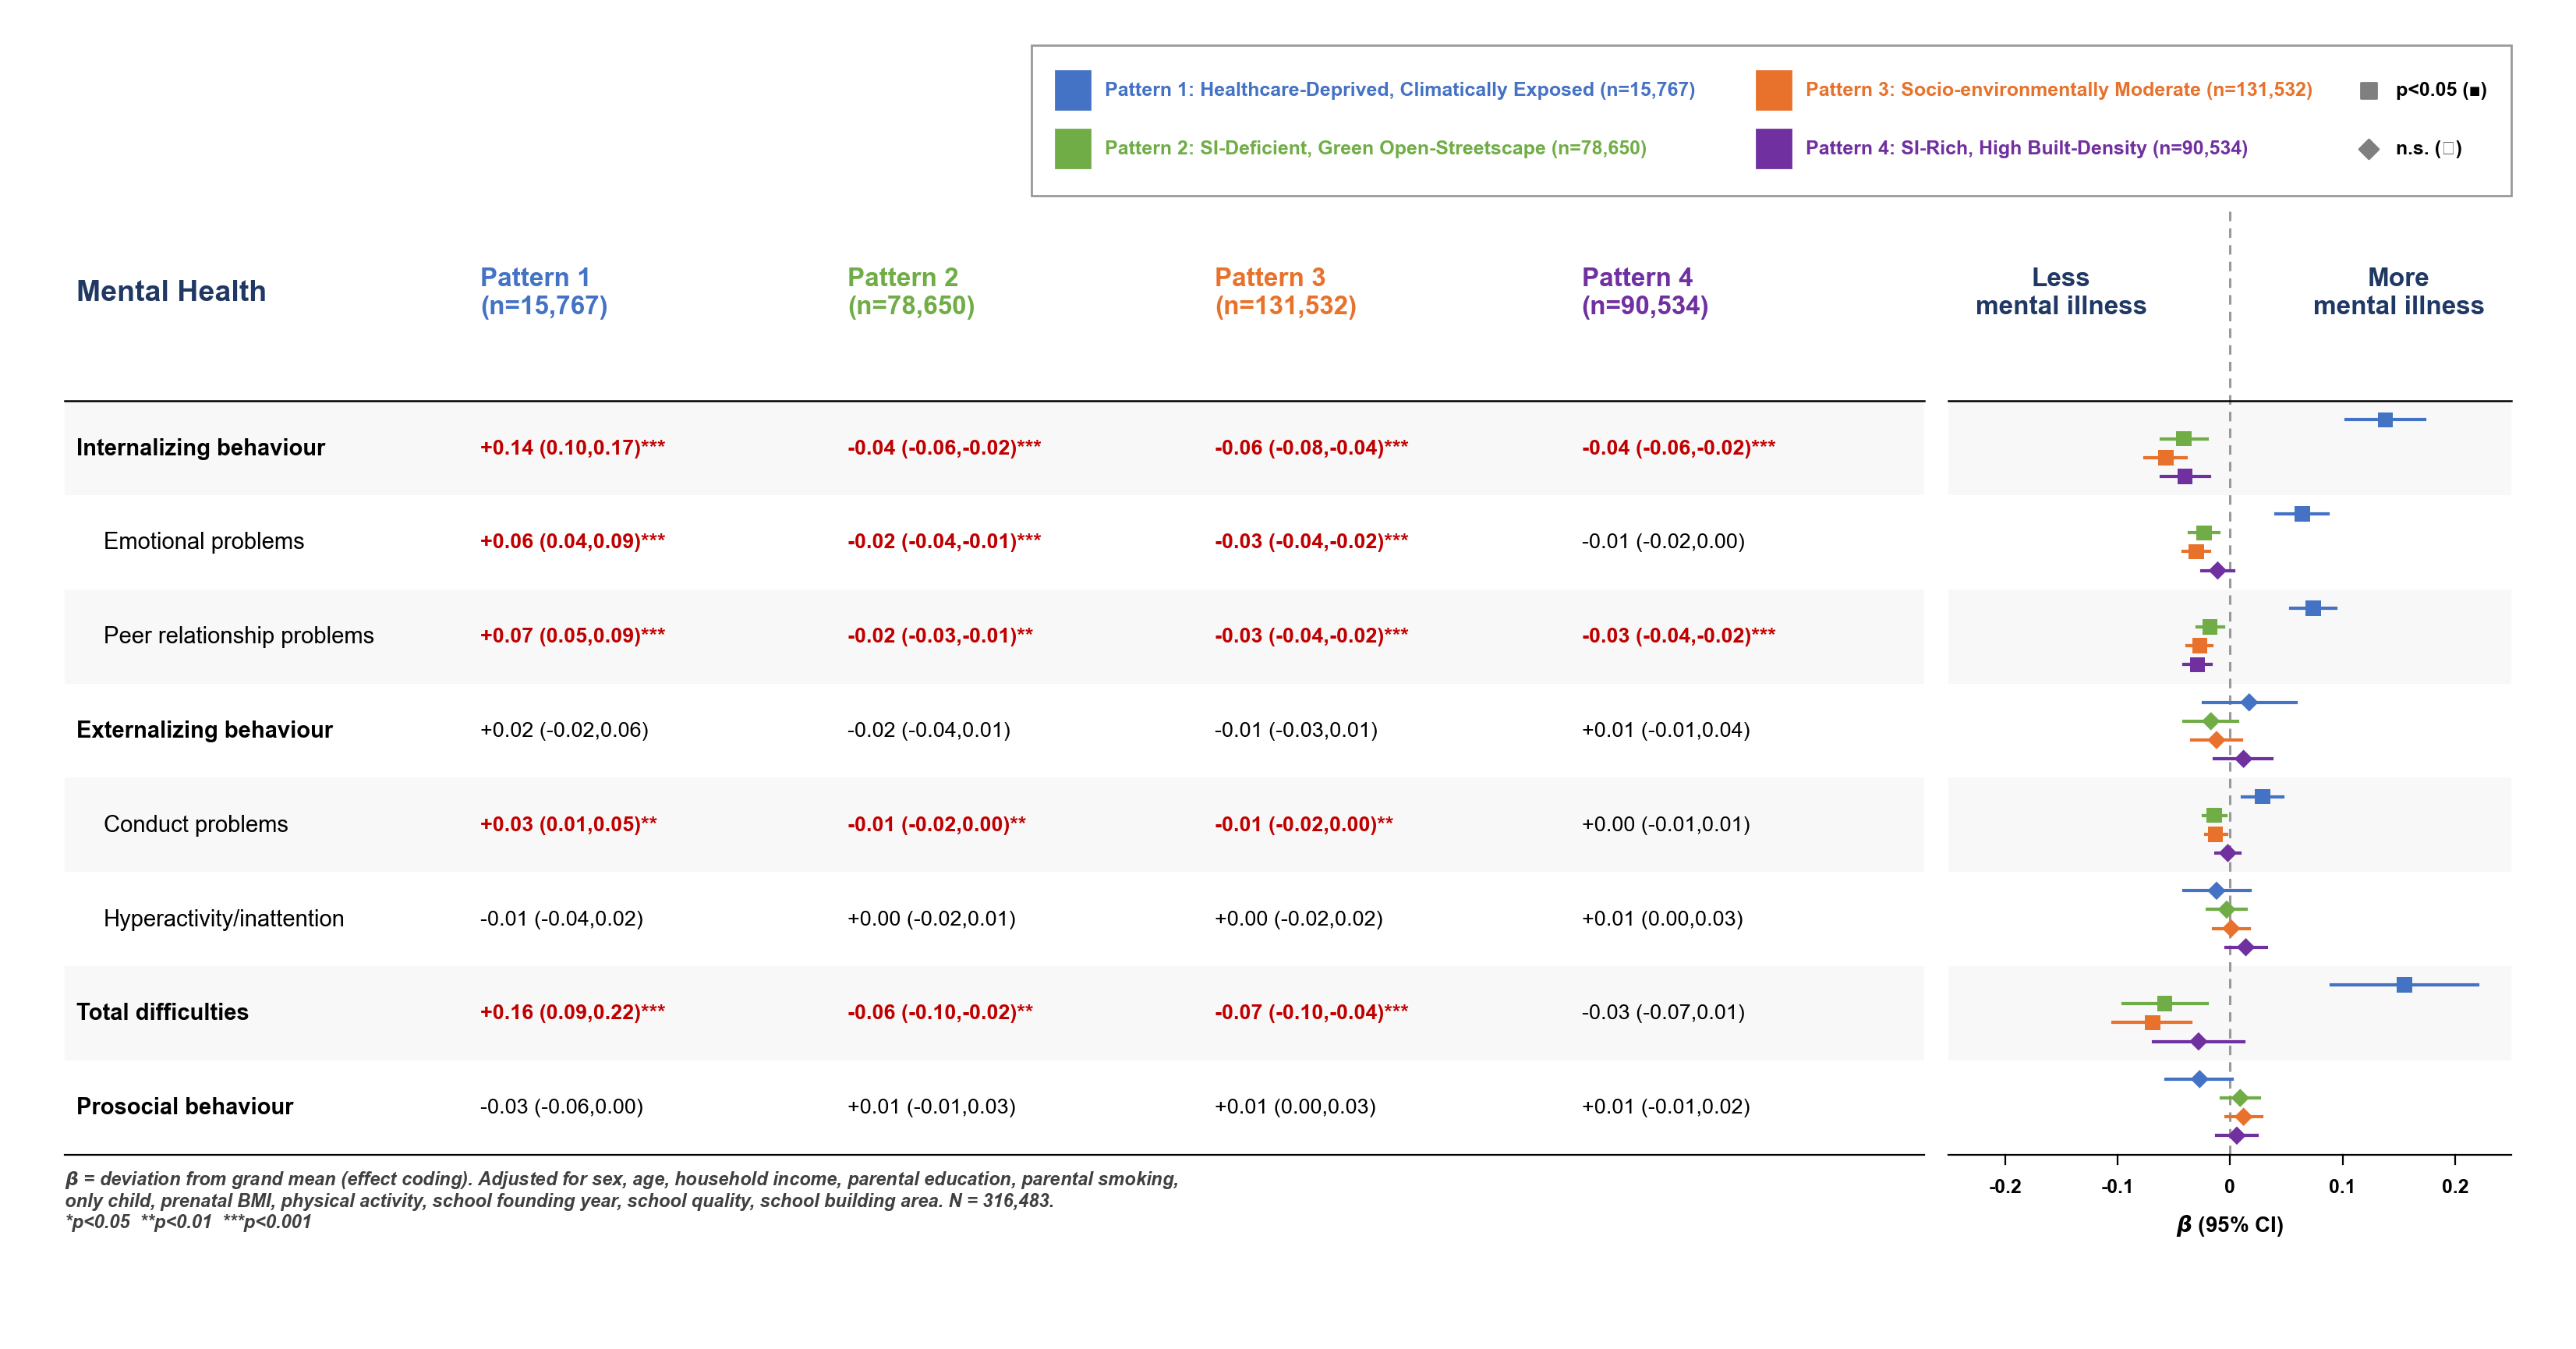

eFigure 6 (forest) saved: efig6_forest.png


In [17]:
# ════════════════════════════════════════════════════════════════
# 15. Supplementary Figure 6: Forest plot (LMM without school-level covariates)
# ════════════════════════════════════════════════════════════════

print("\nGenerating eFigure 6 (forest plot)...")

# Pattern sizes / colours / names 
PAT_N = {k: int((df_clean['cluster'] == k).sum()) for k in range(1, N_CLUSTERS + 1)}
n1, n2, n3, n4 = PAT_N[1], PAT_N[2], PAT_N[3], PAT_N[4]

c1, c2, c3, c4 = "#4472C4", "#70AD47", "#E8722C", "#7030A0"   
colors = [c1, c2, c3, c4]
navy = "#1F3864"
sig_red = "#C00000"
pats = ['1', '2', '3', '4']

# Row order + indentation 
row_order = [
    ("Internalizing behaviour",    False),
    ("Emotional problems",         True),
    ("Peer relationship problems", True),
    ("Externalizing behaviour",    False),
    ("Conduct problems",           True),
    ("Hyperactivity/inattention",  True),
    ("Total difficulties",         False),
    ("Prosocial behaviour",        False),
]
label_to_out = dict(zip(OUT_LABELS, OUTCOMES))     
outcomes     = [lab for lab, _ in row_order]
indent_flags = [ind for _, ind in row_order]
n_rows = len(outcomes)
row_h = 1.0

# Pull results: (beta, lo, hi, stars-string) per pattern 
data = {}
for lab in outcomes:
    out = label_to_out[lab]
    data[lab] = []
    for p in pats:
        r = all_results[out][p]
        data[lab].append((r['b'], r['ci_lo'], r['ci_hi'], r['sig']))   # r['sig'] = '', '*', '**' or '***'

# Figure / shared axes 
fig, ax = plt.subplots(figsize=(17, 9.5), dpi=200)
fig.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.06)

TABLE_X0, TABLE_X1 = 0.0, 76.0      # table region
PLOT_X0,  PLOT_X1  = 77.0, 100.0    # forest region

ax.set_xlim(-2, 102)
ax.set_ylim(-1.9, n_rows + 4.1)

name_x   = 0.5
indent_x = 1.1
col_x    = [17.0, 32.0, 47.0, 62.0]

y_legend  = n_rows + 3.3
y_colhead = n_rows + 1.15
y_topline = n_rows

# Row shading 
for i in range(n_rows):
    y = n_rows - i - 1
    if i % 2 == 0:
        ax.add_patch(mpatches.Rectangle((TABLE_X0, y), TABLE_X1 - TABLE_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))
        ax.add_patch(mpatches.Rectangle((PLOT_X0, y), PLOT_X1 - PLOT_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))

# Legend box 
sw, sh = 1.4, 0.40
row_gap = 0.62
y_row0 = y_legend
y_row1 = y_legend - row_gap
col1_x = 19.0

labels = [
    (c1, f"Pattern 1: Healthcare-Deprived, Climatically Exposed (n={n1:,})"),
    (c2, f"Pattern 2: SI-Deficient, Green Open-Streetscape (n={n2:,})"),
    (c3, f"Pattern 3: Socio-environmentally Moderate (n={n3:,})"),
    (c4, f"Pattern 4: SI-Rich, High Built-Density (n={n4:,})"),
]
inv = ax.transData.inverted()

def text_x1(t):
    bbox = t.get_window_extent(renderer=fig.canvas.get_renderer())
    return inv.transform((bbox.x1, 0))[0]

def draw_legend(dx):
    arts = []
    def item(x, y, color, text, fontsize=9.0):
        arts.append(ax.add_patch(mpatches.Rectangle((x, y - sh / 2), sw, sh, color=color, zorder=5)))
        t = ax.text(x + sw + 0.6, y, text, fontsize=fontsize, color=color,
                    fontweight="bold", va="center", ha="left", zorder=5)
        arts.append(t)
        return t

    t1 = item(col1_x + dx, y_row0, *labels[0])
    t2 = item(col1_x + dx, y_row1, *labels[1])
    fig.canvas.draw()
    col2_x = max(text_x1(t1), text_x1(t2)) + 2.5
    t3 = item(col2_x, y_row0, *labels[2])
    t4 = item(col2_x, y_row1, *labels[3])
    fig.canvas.draw()
    col3_x = max(text_x1(t3), text_x1(t4)) + 2.3

    arts.append(ax.scatter([col3_x], [y_row0], marker="s", s=55, color="#7f7f7f", zorder=5))
    t5 = ax.text(col3_x + 1.1, y_row0, "p<0.05 (\u25A0)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts.append(ax.scatter([col3_x], [y_row1], marker="D", s=40, color="#7f7f7f", zorder=5))
    t6 = ax.text(col3_x + 1.1, y_row1, "n.s. (\u25C6)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts += [t5, t6]
    fig.canvas.draw()

    box_x0 = 18.0 + dx
    box_x1 = max(text_x1(t5), text_x1(t6)) + 1.0
    box_y0, box_y1 = y_row1 - sh / 2 - 0.30, y_row0 + sh / 2 + 0.28
    arts.append(ax.add_patch(mpatches.FancyBboxPatch(
        (box_x0, box_y0), box_x1 - box_x0, box_y1 - box_y0,
        boxstyle="square,pad=0", linewidth=1.0,
        edgecolor="#999999", facecolor="white", zorder=3.5)))
    return arts, box_x1

arts, right_edge = draw_legend(0.0)
for a in arts:
    a.remove()
arts, right_edge = draw_legend(PLOT_X1 - right_edge)

# Column headers
ax.text(name_x, y_colhead, "Mental Health", fontsize=13.5, fontweight="bold",
        color=navy, va="center", ha="left")

col_labels = [f"Pattern 1\n(n={n1:,})", f"Pattern 2\n(n={n2:,})",
              f"Pattern 3\n(n={n3:,})", f"Pattern 4\n(n={n4:,})"]
for cx, lbl, col in zip(col_x, col_labels, colors):
    ax.text(cx, y_colhead, lbl, color=col, fontsize=12.0, fontweight="bold",
            va="center", ha="left")

ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.20, y_colhead, "Less\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")
ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.80, y_colhead, "More\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")

# top border lines
ax.plot([TABLE_X0, TABLE_X1], [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)
ax.plot([PLOT_X0, PLOT_X1],   [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)

# Table rows 
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    label_x = name_x + (indent_x if indent_flags[i] else 0.0)
    weight = "normal" if indent_flags[i] else "bold"
    ax.text(label_x, yc, lab, fontsize=10.5, va="center", ha="left", zorder=2,
            color="black", fontweight=weight)
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        txt_color = sig_red if sig else "black"
        w = "bold" if sig else "normal"
        def f2(v, signed=False):
            v = round(v, 2) + 0.0          
            return f"{v:+.2f}" if signed else f"{v:.2f}"
    
        txt = f"{f2(beta, True)} ({f2(lo)},{f2(hi)}){stars}"
        ax.text(col_x[j], yc, txt, fontsize=9.7, color=txt_color, fontweight=w,
                va="center", ha="left", zorder=2)

ax.plot([TABLE_X0, TABLE_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

# Forest plot
xlim = 0.25                                   # axis range: -0.25 ~ +0.25
def to_plot_x(v):
    v = min(max(v, -xlim), xlim)              # clip CI at the axis limits
    return PLOT_X0 + (v + xlim) / (2 * xlim) * (PLOT_X1 - PLOT_X0)

zero_x = to_plot_x(0.0)
ax.plot([zero_x, zero_x], [0, y_colhead + 0.9], color="#999999",
        linestyle=(0, (4, 3)), linewidth=1.1, zorder=1)
ax.plot([PLOT_X0, PLOT_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

offsets = [0.3, 0.1, -0.1, -0.3]
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        col = colors[j]
        yy = yc + offsets[j]
        ax.plot([to_plot_x(lo), to_plot_x(hi)], [yy, yy], color=col, linewidth=1.5, zorder=3)
        ax.scatter([to_plot_x(beta)], [yy], color=col, marker="s" if sig else "D",
                   s=50 if sig else 36, zorder=4, edgecolor="none")

x_ticks = [-0.2, -0.1, 0, 0.1, 0.2]
for xt in x_ticks:
    px = to_plot_x(xt)
    ax.plot([px, px], [0, -0.1], color="black", linewidth=0.8, zorder=4)
    ax.text(px, -0.25, f"{xt:g}", fontsize=9, ha="center", va="top")
ax.text((PLOT_X0 + PLOT_X1) / 2, -0.62, r"$\beta$ (95% CI)", fontsize=10, ha="center", va="top")

# Footnote 
ax.text(TABLE_X0, -0.15,
        r"$\beta$ = deviation from grand mean (effect coding). Adjusted for sex, age, household income, parental education, parental smoking,"
        f"\nonly child, prenatal BMI, physical activity, school founding year, school quality, school building area. N = {len(df_clean):,}."
        "\n*p<0.05  **p<0.01  ***p<0.001",
        fontsize=8.5, va="top", ha="left", style="italic", color="#404040")

ax.axis("off")

plt.savefig('efig6_forest.png', dpi=800, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()
print("eFigure 6 (forest) saved: efig6_forest.png")

In [18]:
# ════════════════════════════════════════════════════════════════
# 16. LMM full analysis: all 4 patterns vs grand mean
#     add school-level covariates(school_year, school_area, school_quality from School_var.csv)
#     Matched to df_clean via PCODE1; random intercept = street_id
# ════════════════════════════════════════════════════════════════

from sklearn.experimental import enable_iterative_imputer   # noqa
from sklearn.impute import IterativeImputer

print("\nLoading school covariates from School_var.csv...")
COVAR_PATH   = 'School_var.csv'
SCH_COV_VARS = ['school_year_z', 'school_area_z', 'school_quality']
MI_M         = 5    # number of imputed datasets
MI_SEED      = 42

_df_covar = pd.read_csv(COVAR_PATH, low_memory=False)
_df_covar['PCODE1'] = _df_covar['PCODE1'].astype(str)

# Left-join to keep ALL df_clean rows; missing school covariates become NaN
_pcode_series = df.loc[df_clean.index, 'PCODE1'].astype(str).rename('PCODE1')
df_clean_with_pcode = df_clean.copy()
df_clean_with_pcode['PCODE1'] = _pcode_series.values

_df_sch_cov_all = _df_covar[['PCODE1'] + SCH_COV_VARS].drop_duplicates('PCODE1')
df_lmm_sch = df_clean_with_pcode.merge(_df_sch_cov_all, on='PCODE1', how='left')

n_missing_sch = df_lmm_sch[SCH_COV_VARS].isnull().any(axis=1).sum()
print(f"  Full sample N = {len(df_lmm_sch):,}  "
      f"(school covariates missing for {n_missing_sch:,} obs → will impute)")

# Effect codes on full sample
df_lmm_sch['e2'] = np.where(df_lmm_sch['cluster']==2,  1,
                   np.where(df_lmm_sch['cluster']==1, -1, 0))
df_lmm_sch['e3'] = np.where(df_lmm_sch['cluster']==3,  1,
                   np.where(df_lmm_sch['cluster']==1, -1, 0))
df_lmm_sch['e4'] = np.where(df_lmm_sch['cluster']==4,  1,
                   np.where(df_lmm_sch['cluster']==1, -1, 0))

ctrl_formula_sch = ctrl_formula + ' + ' + ' + '.join(SCH_COV_VARS)

# Multiple imputation of school covariates
_mi_aux_vars = ['e2', 'e3', 'e4'] + [v for v in CTRL_VARS[:7] if v in df_lmm_sch.columns]
_mi_cols     = _mi_aux_vars + SCH_COV_VARS          # columns fed to imputer
_X_for_mi    = df_lmm_sch[_mi_cols].copy()

print(f"  Running MICE (m={MI_M}) on {len(_X_for_mi):,} rows × "
      f"{len(_mi_cols)} vars ({n_missing_sch:,} rows need imputation)...")

_imputed_datasets = []
for _m in range(MI_M):
    _imp = IterativeImputer(random_state=MI_SEED + _m, max_iter=10,
                            sample_posterior=True)
    _X_imp = _imp.fit_transform(_X_for_mi)
    _df_imp = df_lmm_sch.copy()
    # Replace school cov columns with imputed values
    _sch_col_idx = [_mi_cols.index(v) for v in SCH_COV_VARS]
    for _j, _v in zip(_sch_col_idx, SCH_COV_VARS):
        _df_imp[_v] = _X_imp[:, _j]
    _imputed_datasets.append(_df_imp)
    print(f"    Imputation {_m+1}/{MI_M} done")

# Rubin's rules pooling helper
def _rubin_pool(b_list, se_list):
    """Pool m estimates with Rubin's rules.
    Returns (b_pool, se_pool) where se_pool accounts for within- and
    between-imputation variance."""
    m   = len(b_list)
    b_  = np.mean(b_list)
    # within-imputation variance
    U_  = np.mean([s**2 for s in se_list])
    # between-imputation variance
    B_  = np.var(b_list, ddof=1) if m > 1 else 0.0
    # total variance
    T_  = U_ + (1 + 1/m) * B_
    return b_, np.sqrt(T_)

# Run LMM on each imputed dataset, pool with Rubin's rules
sch_cov_results = {}
all_coef_rows   = []        # NEW: every fixed effect (incl. covariates), pooled
print(f"\n  LMM with school covariates — MI pooled (N={len(df_lmm_sch):,}):")
for out, lbl in zip(OUTCOMES, OUT_LABELS):
    formula = f'{out} ~ e2 + e3 + e4 + {ctrl_formula_sch}'

    _b_store  = {k: [] for k in ['e2','e3','e4']}
    _se_store = {k: [] for k in ['e2','e3','e4']}
    _full_store = []        # NEW: params / SEs of all terms, one entry per imputation

    for _df_m in _imputed_datasets:
        _model = smf.mixedlm(formula, data=_df_m, groups=_df_m['street_id'])
        _res   = _model.fit(method='lbfgs', maxiter=200, disp=False)
        _full_store.append((_res.params, _res.bse))      # NEW
        for _key in ['e2', 'e3', 'e4']:
            _b_store[_key].append(_res.params[_key])
            _se_store[_key].append(_res.bse[_key])

    row = {}
    for p, key in [('2', 'e2'), ('3', 'e3'), ('4', 'e4')]:
        b, se = _rubin_pool(_b_store[key], _se_store[key])
        pv    = 2 * (1 - sc_stats.norm.cdf(abs(b / se)))
        ci_lo = b - 1.96 * se
        ci_hi = b + 1.96 * se
        sig   = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else ''
        row[p] = {'b': round(b,3), 'ci_lo': round(ci_lo,3),
                  'ci_hi': round(ci_hi,3), 'p': round(pv,4), 'sig': sig}

    # Pattern 1 derived from effect coding constraint: b1 = -(b2+b3+b4)
    b_e2, se_e2 = _rubin_pool(_b_store['e2'], _se_store['e2'])
    b_e3, se_e3 = _rubin_pool(_b_store['e3'], _se_store['e3'])
    b_e4, se_e4 = _rubin_pool(_b_store['e4'], _se_store['e4'])
    b1  = -(b_e2 + b_e3 + b_e4)
    se1 = np.sqrt(se_e2**2 + se_e3**2 + se_e4**2)
    pv1 = 2 * (1 - sc_stats.norm.cdf(abs(b1 / se1)))
    ci_lo1 = b1 - 1.96 * se1
    ci_hi1 = b1 + 1.96 * se1
    sig1   = '***' if pv1<0.001 else '**' if pv1<0.01 else '*' if pv1<0.05 else ''
    row['1'] = {'b': round(b1,3), 'ci_lo': round(ci_lo1,3),
                'ci_hi': round(ci_hi1,3), 'p': round(pv1,4), 'sig': sig1}

    sch_cov_results[out] = row

    # NEW: pool ALL fixed effects (intercept, e2/e3/e4, covariates, school vars) with Rubin's rules
    for _name in _full_store[0][0].index:
        if 'Var' in _name or 'Cov' in _name:      # skip random-effect variance terms
            continue
        _b, _se = _rubin_pool([p[_name] for p, s in _full_store],
                              [s[_name] for p, s in _full_store])
        _pv = 2 * (1 - sc_stats.norm.cdf(abs(_b / _se)))
        all_coef_rows.append({'Outcome': lbl, 'Variable': _name, 'Beta': round(_b, 4),
                              'SE': round(_se, 4), 'CI_lo': round(_b - 1.96 * _se, 4),
                              'CI_hi': round(_b + 1.96 * _se, 4), 'p': round(_pv, 4),
                              'sig': '***' if _pv < 0.001 else '**' if _pv < 0.01 else '*' if _pv < 0.05 else ''})
    all_coef_rows.append({'Outcome': lbl, 'Variable': 'Pattern 1 (derived: -(e2+e3+e4))',
                          'Beta': row['1']['b'], 'CI_lo': row['1']['ci_lo'], 'CI_hi': row['1']['ci_hi'],
                          'p': row['1']['p'], 'sig': row['1']['sig']})

    r = lambda p: row[p]
    print(f"    {lbl[:24]:24s}: "
          f"P1={r('1')['b']:+.3f}{r('1')['sig']:3s} "
          f"P2={r('2')['b']:+.3f}{r('2')['sig']:3s} "
          f"P3={r('3')['b']:+.3f}{r('3')['sig']:3s} "
          f"P4={r('4')['b']:+.3f}{r('4')['sig']:3s}")

# Save results table
sch_cov_rows = []
for out, lbl in zip(OUTCOMES, OUT_LABELS):
    row = {'SDQ Outcome': lbl}
    for p in ['1', '2', '3', '4']:
        r = sch_cov_results[out][p]
        row[f'{pat_short[p]} β']     = r['b']
        row[f'{pat_short[p]} 95%CI'] = f"({r['ci_lo']},{r['ci_hi']})"
        row[f'{pat_short[p]} p']     = r['p']
        row[f'{pat_short[p]} sig']   = r['sig']
    sch_cov_rows.append(row)
pd.DataFrame(sch_cov_rows).to_csv('lmm_school_covariates.csv', index=False)
print("  School-covariate LMM table saved: lmm_school_covariates.csv")

pd.DataFrame(all_coef_rows).to_csv('lmm_school_covariates_all_coefs.csv', index=False)
print("  All-coefficient table saved: lmm_school_covariates_all_coefs.csv")


Loading school covariates from School_var.csv...
  Full sample N = 316,483  (school covariates missing for 734 obs → will impute)
  Running MICE (m=5) on 316,483 rows × 13 vars (734 rows need imputation)...
    Imputation 1/5 done
    Imputation 2/5 done
    Imputation 3/5 done
    Imputation 4/5 done
    Imputation 5/5 done

  LMM with school covariates — MI pooled (N=316,483):
    Emotional problems      : P1=+0.058*** P2=-0.017*   P3=-0.028*** P4=-0.013   
    Conduct problems        : P1=+0.033*** P2=-0.006    P3=-0.015**  P4=-0.011   
    Hyperactivity/inattentio: P1=-0.011    P2=+0.006    P3=+0.000    P4=+0.005   
    Peer relationship proble: P1=+0.074*** P2=-0.013*   P3=-0.027*** P4=-0.033***
    Prosocial behaviour     : P1=-0.025    P2=+0.005    P3=+0.011    P4=+0.009   
    Total difficulties      : P1=+0.160*** P2=-0.036    P3=-0.075*** P4=-0.050*  
    Internalizing behaviour : P1=+0.132*** P2=-0.031**  P3=-0.056*** P4=-0.045***
    Externalizing behaviour : P1=+0.022    


Generating Figure 3 (forest plot)...


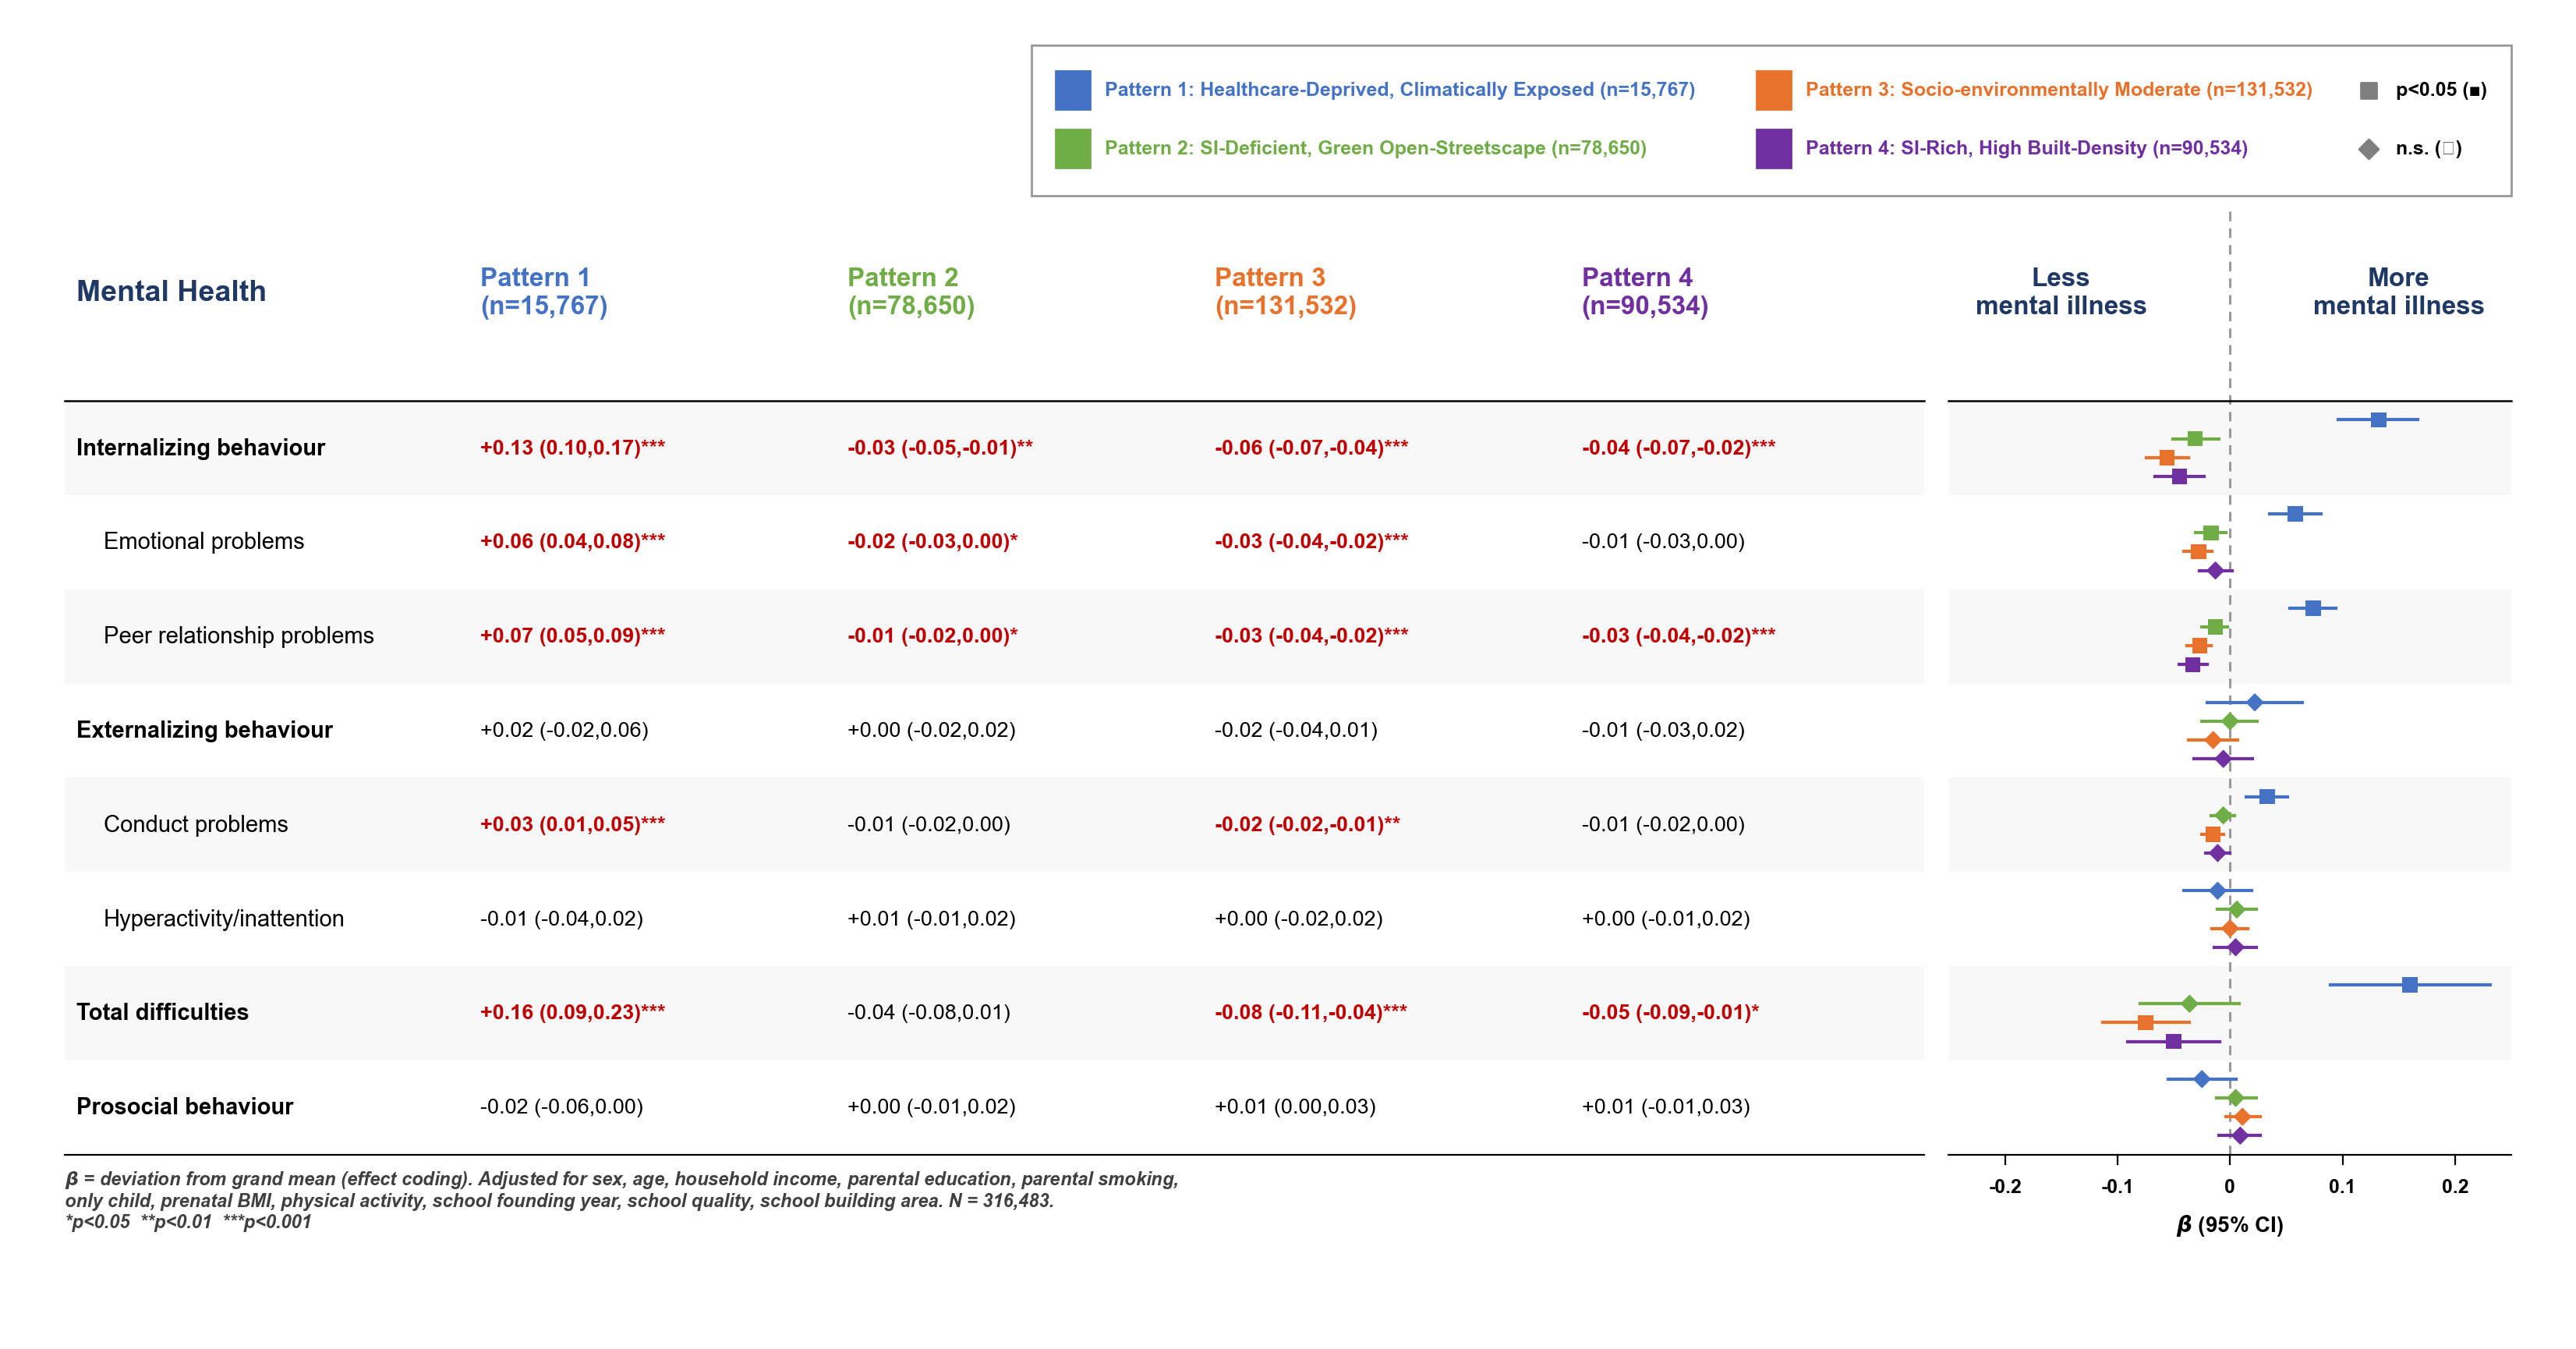

Figure 3 (forest) saved: Fig3_forest.png


In [19]:
# ════════════════════════════════════════════════════════════════
# 17. Figure 3: Forest plot (LMM full results)
# ════════════════════════════════════════════════════════════════

print("\nGenerating Figure 3 (forest plot)...")

# Pattern sizes / colours / names 
PAT_N = {k: int((df_clean['cluster'] == k).sum()) for k in range(1, N_CLUSTERS + 1)}
n1, n2, n3, n4 = PAT_N[1], PAT_N[2], PAT_N[3], PAT_N[4]

c1, c2, c3, c4 = "#4472C4", "#70AD47", "#E8722C", "#7030A0"   
colors = [c1, c2, c3, c4]
navy = "#1F3864"
sig_red = "#C00000"
pats = ['1', '2', '3', '4']

# Row order + indentation 
row_order = [
    ("Internalizing behaviour",    False),
    ("Emotional problems",         True),
    ("Peer relationship problems", True),
    ("Externalizing behaviour",    False),
    ("Conduct problems",           True),
    ("Hyperactivity/inattention",  True),
    ("Total difficulties",         False),
    ("Prosocial behaviour",        False),
]
label_to_out = dict(zip(OUT_LABELS, OUTCOMES))      
outcomes     = [lab for lab, _ in row_order]
indent_flags = [ind for _, ind in row_order]
n_rows = len(outcomes)
row_h = 1.0

# Pull results: (beta, lo, hi, stars-string) per pattern 
data = {}
for lab in outcomes:
    out = label_to_out[lab]
    data[lab] = []
    for p in pats:
        r = sch_cov_results[out][p]
        data[lab].append((r['b'], r['ci_lo'], r['ci_hi'], r['sig']))   # r['sig'] = '', '*', '**' or '***'

# Figure / shared axes 
fig, ax = plt.subplots(figsize=(17, 9.5), dpi=200)
fig.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.06)

TABLE_X0, TABLE_X1 = 0.0, 76.0      # table region
PLOT_X0,  PLOT_X1  = 77.0, 100.0    # forest region

ax.set_xlim(-2, 102)
ax.set_ylim(-1.9, n_rows + 4.1)

name_x   = 0.5
indent_x = 1.1
col_x    = [17.0, 32.0, 47.0, 62.0]

y_legend  = n_rows + 3.3
y_colhead = n_rows + 1.15
y_topline = n_rows

# Row shading 
for i in range(n_rows):
    y = n_rows - i - 1
    if i % 2 == 0:
        ax.add_patch(mpatches.Rectangle((TABLE_X0, y), TABLE_X1 - TABLE_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))
        ax.add_patch(mpatches.Rectangle((PLOT_X0, y), PLOT_X1 - PLOT_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))
        
# Legend box 
sw, sh = 1.4, 0.40
row_gap = 0.62
y_row0 = y_legend
y_row1 = y_legend - row_gap
col1_x = 19.0

labels = [
    (c1, f"Pattern 1: Healthcare-Deprived, Climatically Exposed (n={n1:,})"),
    (c2, f"Pattern 2: SI-Deficient, Green Open-Streetscape (n={n2:,})"),
    (c3, f"Pattern 3: Socio-environmentally Moderate (n={n3:,})"),
    (c4, f"Pattern 4: SI-Rich, High Built-Density (n={n4:,})"),
]
inv = ax.transData.inverted()

def text_x1(t):
    bbox = t.get_window_extent(renderer=fig.canvas.get_renderer())
    return inv.transform((bbox.x1, 0))[0]

def draw_legend(dx):
    arts = []
    def item(x, y, color, text, fontsize=9.0):
        arts.append(ax.add_patch(mpatches.Rectangle((x, y - sh / 2), sw, sh, color=color, zorder=5)))
        t = ax.text(x + sw + 0.6, y, text, fontsize=fontsize, color=color,
                    fontweight="bold", va="center", ha="left", zorder=5)
        arts.append(t)
        return t

    t1 = item(col1_x + dx, y_row0, *labels[0])
    t2 = item(col1_x + dx, y_row1, *labels[1])
    fig.canvas.draw()
    col2_x = max(text_x1(t1), text_x1(t2)) + 2.5
    t3 = item(col2_x, y_row0, *labels[2])
    t4 = item(col2_x, y_row1, *labels[3])
    fig.canvas.draw()
    col3_x = max(text_x1(t3), text_x1(t4)) + 2.3

    arts.append(ax.scatter([col3_x], [y_row0], marker="s", s=55, color="#7f7f7f", zorder=5))
    t5 = ax.text(col3_x + 1.1, y_row0, "p<0.05 (\u25A0)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts.append(ax.scatter([col3_x], [y_row1], marker="D", s=40, color="#7f7f7f", zorder=5))
    t6 = ax.text(col3_x + 1.1, y_row1, "n.s. (\u25C6)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts += [t5, t6]
    fig.canvas.draw()

    box_x0 = 18.0 + dx
    box_x1 = max(text_x1(t5), text_x1(t6)) + 1.0
    box_y0, box_y1 = y_row1 - sh / 2 - 0.30, y_row0 + sh / 2 + 0.28
    arts.append(ax.add_patch(mpatches.FancyBboxPatch(
        (box_x0, box_y0), box_x1 - box_x0, box_y1 - box_y0,
        boxstyle="square,pad=0", linewidth=1.0,
        edgecolor="#999999", facecolor="white", zorder=3.5)))
    return arts, box_x1

arts, right_edge = draw_legend(0.0)
for a in arts:
    a.remove()
arts, right_edge = draw_legend(PLOT_X1 - right_edge)

# Column headers 
ax.text(name_x, y_colhead, "Mental Health", fontsize=13.5, fontweight="bold",
        color=navy, va="center", ha="left")

col_labels = [f"Pattern 1\n(n={n1:,})", f"Pattern 2\n(n={n2:,})",
              f"Pattern 3\n(n={n3:,})", f"Pattern 4\n(n={n4:,})"]
for cx, lbl, col in zip(col_x, col_labels, colors):
    ax.text(cx, y_colhead, lbl, color=col, fontsize=12.0, fontweight="bold",
            va="center", ha="left")

ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.20, y_colhead, "Less\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")
ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.80, y_colhead, "More\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")

# top border lines
ax.plot([TABLE_X0, TABLE_X1], [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)
ax.plot([PLOT_X0, PLOT_X1],   [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)

# Table rows 
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    label_x = name_x + (indent_x if indent_flags[i] else 0.0)
    weight = "normal" if indent_flags[i] else "bold"
    ax.text(label_x, yc, lab, fontsize=10.5, va="center", ha="left", zorder=2,
            color="black", fontweight=weight)
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        txt_color = sig_red if sig else "black"
        w = "bold" if sig else "normal"
        def f2(v, signed=False):
            v = round(v, 2) + 0.0          
            return f"{v:+.2f}" if signed else f"{v:.2f}"
    
        txt = f"{f2(beta, True)} ({f2(lo)},{f2(hi)}){stars}"
        ax.text(col_x[j], yc, txt, fontsize=9.7, color=txt_color, fontweight=w,
                va="center", ha="left", zorder=2)

ax.plot([TABLE_X0, TABLE_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

# Forest plot 
xlim = 0.25                                   # axis range: -0.25 ~ +0.25
def to_plot_x(v):
    v = min(max(v, -xlim), xlim)              # clip CI at the axis limits
    return PLOT_X0 + (v + xlim) / (2 * xlim) * (PLOT_X1 - PLOT_X0)

zero_x = to_plot_x(0.0)
ax.plot([zero_x, zero_x], [0, y_colhead + 0.9], color="#999999",
        linestyle=(0, (4, 3)), linewidth=1.1, zorder=1)
ax.plot([PLOT_X0, PLOT_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

offsets = [0.3, 0.1, -0.1, -0.3]
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        col = colors[j]
        yy = yc + offsets[j]
        ax.plot([to_plot_x(lo), to_plot_x(hi)], [yy, yy], color=col, linewidth=1.5, zorder=3)
        ax.scatter([to_plot_x(beta)], [yy], color=col, marker="s" if sig else "D",
                   s=50 if sig else 36, zorder=4, edgecolor="none")

x_ticks = [-0.2, -0.1, 0, 0.1, 0.2]
for xt in x_ticks:
    px = to_plot_x(xt)
    ax.plot([px, px], [0, -0.1], color="black", linewidth=0.8, zorder=4)
    ax.text(px, -0.25, f"{xt:g}", fontsize=9, ha="center", va="top")
ax.text((PLOT_X0 + PLOT_X1) / 2, -0.62, r"$\beta$ (95% CI)", fontsize=10, ha="center", va="top")

# Footnote 
ax.text(TABLE_X0, -0.15,
        r"$\beta$ = deviation from grand mean (effect coding). Adjusted for sex, age, household income, parental education, parental smoking,"
        f"\nonly child, prenatal BMI, physical activity, school founding year, school quality, school building area. N = {len(df_clean):,}."
        "\n*p<0.05  **p<0.01  ***p<0.001",
        fontsize=8.5, va="top", ha="left", style="italic", color="#404040")

ax.axis("off")

plt.savefig('Fig3_forest.png', dpi=800, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()
print("Figure 3 (forest) saved: Fig3_forest.png")

In [20]:
# ════════════════════════════════════════════════════════════════
# 18. Sensitivity 3-2: LMM with school as random intercept
# ════════════════════════════════════════════════════════════════

print("\nLMM sensitivity2 check...")

SCHOOL_COL = SCHOOL_ID_COL  # 'school.wj_2020'

if SCHOOL_COL not in df_clean.columns:
    print(f"  WARNING: '{SCHOOL_COL}' not found — skipping school sensitivity.")
else:
    _df_sch = _imputed_datasets[0].dropna(subset=[SCHOOL_COL])
    print(f"  N={len(_df_sch):,}, Schools={_df_sch[SCHOOL_COL].nunique()}")

    ctrl_formula_sch19 = ctrl_formula + ' + ' + ' + '.join(SCH_COV_VARS)

    sens_school_results = {}
    print(f"  Running LMM with school random intercept + school covariates...")
    for out, lbl in zip(OUTCOMES, OUT_LABELS):
        formula = f'{out} ~ e2 + e3 + e4 + {ctrl_formula_sch19}'
        model   = smf.mixedlm(formula, data=_df_sch, groups=_df_sch[SCHOOL_COL])
        res     = model.fit(method='lbfgs', maxiter=200, disp=False)

        row = {}
        for p, key in [('2', 'e2'), ('3', 'e3'), ('4', 'e4')]:
            b     = res.params[key]
            se    = res.bse[key]
            pv    = res.pvalues[key]
            ci_lo = b - 1.96 * se
            ci_hi = b + 1.96 * se
            sig   = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else ''
            row[p] = {'b': round(b,3), 'ci_lo': round(ci_lo,3),
                      'ci_hi': round(ci_hi,3), 'p': round(pv,4), 'sig': sig}

        b1    = -(res.params['e2'] + res.params['e3'] + res.params['e4'])
        se1   = np.sqrt(res.bse['e2']**2 + res.bse['e3']**2 + res.bse['e4']**2)
        pv1   = 2 * (1 - sc_stats.norm.cdf(abs(b1 / se1)))
        ci_lo1 = b1 - 1.96 * se1
        ci_hi1 = b1 + 1.96 * se1
        sig1   = '***' if pv1<0.001 else '**' if pv1<0.01 else '*' if pv1<0.05 else ''
        row['1'] = {'b': round(b1,3), 'ci_lo': round(ci_lo1,3),
                    'ci_hi': round(ci_hi1,3), 'p': round(pv1,4), 'sig': sig1}

        sens_school_results[out] = row
        r = lambda p: row[p]
        print(f"    {lbl[:24]:24s}: "
              f"P1={r('1')['b']:+.3f}{r('1')['sig']:3s} "
              f"P2={r('2')['b']:+.3f}{r('2')['sig']:3s} "
              f"P3={r('3')['b']:+.3f}{r('3')['sig']:3s} "
              f"P4={r('4')['b']:+.3f}{r('4')['sig']:3s}")

    # Save tables
    sch_rows = []
    for out, lbl in zip(OUTCOMES, OUT_LABELS):
        row = {'SDQ Outcome': lbl}
        for p in ['1', '2', '3', '4']:
            r = sens_school_results[out][p]
            row[f'{pat_short[p]} β']     = r['b']
            row[f'{pat_short[p]} 95%CI'] = f"({r['ci_lo']},{r['ci_hi']})"
            row[f'{pat_short[p]} p']     = r['p']
            row[f'{pat_short[p]} sig']   = r['sig']
        sch_rows.append(row)
    pd.DataFrame(sch_rows).to_csv('sensitivity_school_lmm.csv', index=False)

    comp_rows = []
    for out, lbl in zip(OUTCOMES, OUT_LABELS):
        row = {'SDQ Outcome': lbl}
        for p in ['1', '2', '3', '4']:
            rs = all_results[out][p]
            rc = sens_school_results[out][p]
            pn = pat_short[p].replace(' ', '_')
            row[f'{pn}_street_β']   = rs['b']
            row[f'{pn}_street_sig'] = rs['sig']
            row[f'{pn}_school_β']   = rc['b']
            row[f'{pn}_school_sig'] = rc['sig']
        comp_rows.append(row)
    pd.DataFrame(comp_rows).to_csv('sensitivity_street_vs_school1.csv', index=False)
    print("  School LMM tables saved.")


LMM sensitivity2 check...
  N=316,483, Schools=1416
  Running LMM with school random intercept + school covariates...
    Emotional problems      : P1=+0.101*** P2=-0.036*** P3=-0.038*** P4=-0.027*  
    Conduct problems        : P1=+0.019    P2=-0.008    P3=-0.007    P4=-0.004   
    Hyperactivity/inattentio: P1=+0.014    P2=-0.009    P3=+0.000    P4=-0.005   
    Peer relationship proble: P1=+0.086*** P2=-0.020*   P3=-0.029*** P4=-0.036***
    Prosocial behaviour     : P1=-0.016    P2=+0.005    P3=-0.003    P4=+0.014   
    Total difficulties      : P1=+0.220*** P2=-0.073*   P3=-0.074**  P4=-0.072*  
    Internalizing behaviour : P1=+0.187*** P2=-0.056*** P3=-0.067*** P4=-0.063***
    Externalizing behaviour : P1=+0.033    P2=-0.017    P3=-0.007    P4=-0.009   
  School LMM tables saved.



Generating eFigure 7 (forest plot)...


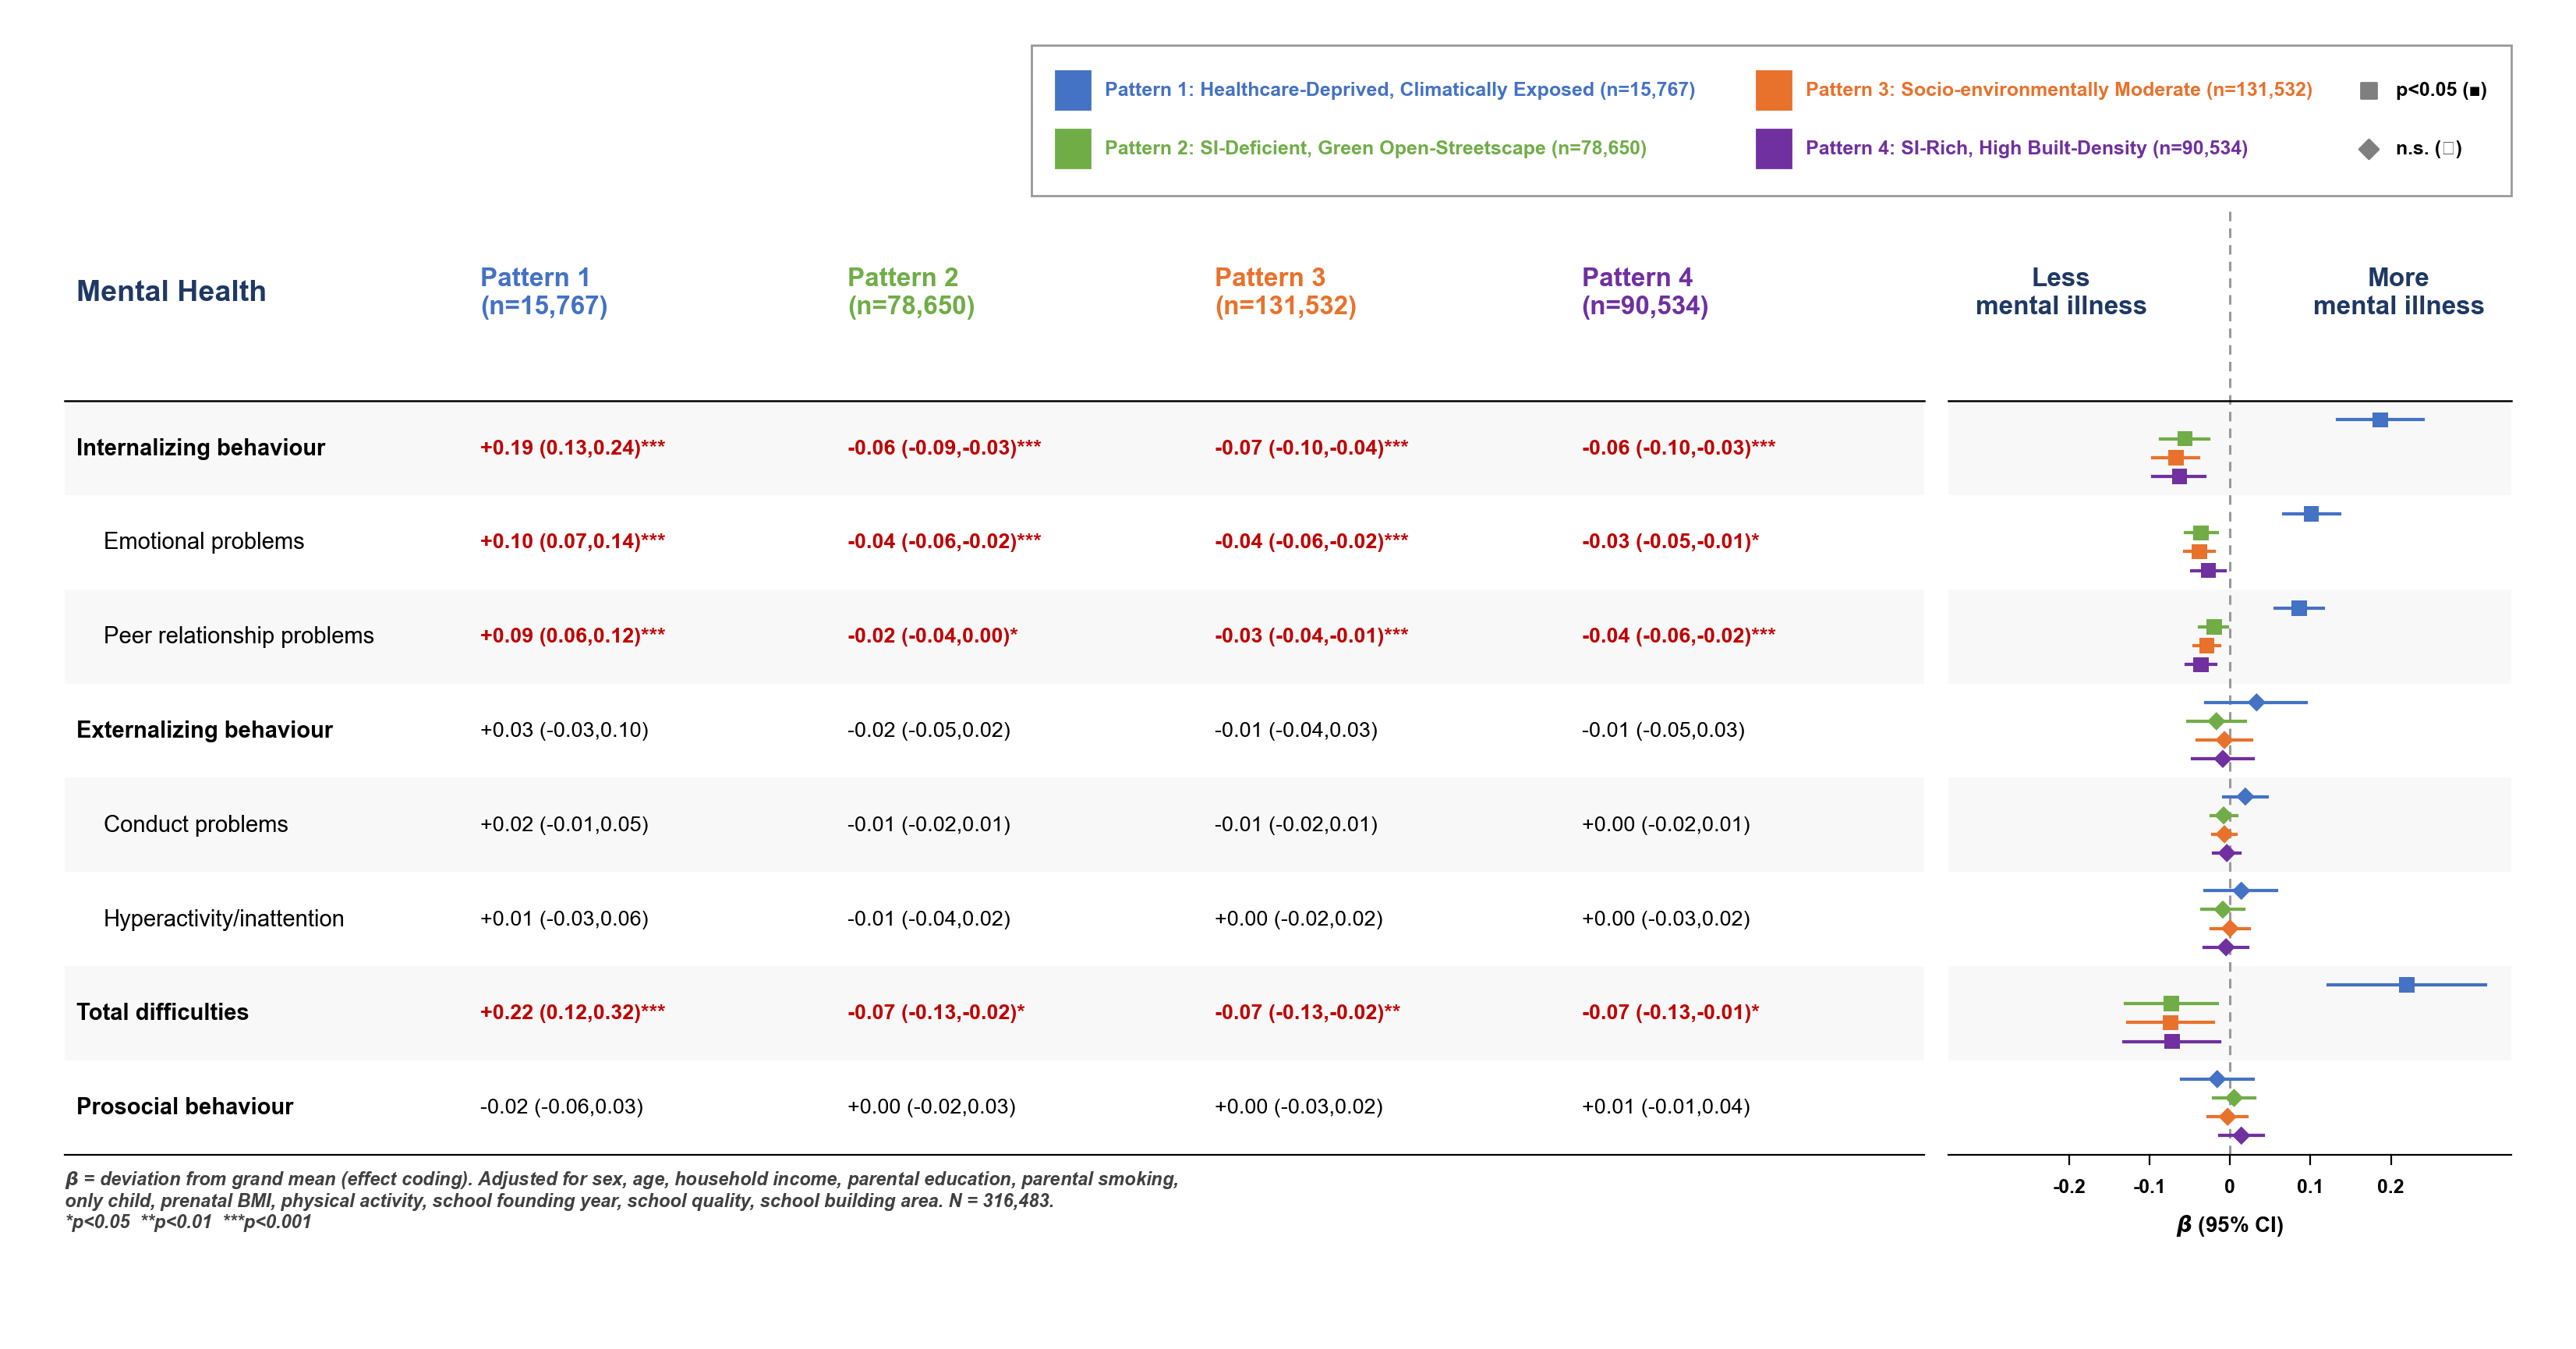

eFigure 7 (forest) saved: efig7_forest.png


In [21]:
# ════════════════════════════════════════════════════════════════
# 19. Supplementary Figure 7: Forest plot (LMM with school as random intercept)
# ════════════════════════════════════════════════════════════════

print("\nGenerating eFigure 7 (forest plot)...")

# Pattern sizes / colours / names 
PAT_N = {k: int((df_clean['cluster'] == k).sum()) for k in range(1, N_CLUSTERS + 1)}
n1, n2, n3, n4 = PAT_N[1], PAT_N[2], PAT_N[3], PAT_N[4]

c1, c2, c3, c4 = "#4472C4", "#70AD47", "#E8722C", "#7030A0"  
colors = [c1, c2, c3, c4]
navy = "#1F3864"
sig_red = "#C00000"
pats = ['1', '2', '3', '4']

# Row order + indentation 
row_order = [
    ("Internalizing behaviour",    False),
    ("Emotional problems",         True),
    ("Peer relationship problems", True),
    ("Externalizing behaviour",    False),
    ("Conduct problems",           True),
    ("Hyperactivity/inattention",  True),
    ("Total difficulties",         False),
    ("Prosocial behaviour",        False),
]
label_to_out = dict(zip(OUT_LABELS, OUTCOMES))      
outcomes     = [lab for lab, _ in row_order]
indent_flags = [ind for _, ind in row_order]
n_rows = len(outcomes)
row_h = 1.0

# Pull results: (beta, lo, hi, stars-string) per pattern 
data = {}
for lab in outcomes:
    out = label_to_out[lab]
    data[lab] = []
    for p in pats:
        r = sens_school_results[out][p]
        data[lab].append((r['b'], r['ci_lo'], r['ci_hi'], r['sig']))   # r['sig'] = '', '*', '**' or '***'

# Figure / shared axes 
fig, ax = plt.subplots(figsize=(17, 9.5), dpi=200)
fig.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.06)

TABLE_X0, TABLE_X1 = 0.0, 76.0      # table region
PLOT_X0,  PLOT_X1  = 77.0, 100.0    # forest region

ax.set_xlim(-2, 102)
ax.set_ylim(-1.9, n_rows + 4.1)

name_x   = 0.5
indent_x = 1.1
col_x    = [17.0, 32.0, 47.0, 62.0]

y_legend  = n_rows + 3.3
y_colhead = n_rows + 1.15
y_topline = n_rows

# Row shading
for i in range(n_rows):
    y = n_rows - i - 1
    if i % 2 == 0:
        ax.add_patch(mpatches.Rectangle((TABLE_X0, y), TABLE_X1 - TABLE_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))
        ax.add_patch(mpatches.Rectangle((PLOT_X0, y), PLOT_X1 - PLOT_X0, row_h,
                                        color="#F8F8F8", zorder=0, linewidth=0))
        
# Legend box 
sw, sh = 1.4, 0.40
row_gap = 0.62
y_row0 = y_legend
y_row1 = y_legend - row_gap
col1_x = 19.0

labels = [
    (c1, f"Pattern 1: Healthcare-Deprived, Climatically Exposed (n={n1:,})"),
    (c2, f"Pattern 2: SI-Deficient, Green Open-Streetscape (n={n2:,})"),
    (c3, f"Pattern 3: Socio-environmentally Moderate (n={n3:,})"),
    (c4, f"Pattern 4: SI-Rich, High Built-Density (n={n4:,})"),
]
inv = ax.transData.inverted()

def text_x1(t):
    bbox = t.get_window_extent(renderer=fig.canvas.get_renderer())
    return inv.transform((bbox.x1, 0))[0]

def draw_legend(dx):
    arts = []
    def item(x, y, color, text, fontsize=9.0):
        arts.append(ax.add_patch(mpatches.Rectangle((x, y - sh / 2), sw, sh, color=color, zorder=5)))
        t = ax.text(x + sw + 0.6, y, text, fontsize=fontsize, color=color,
                    fontweight="bold", va="center", ha="left", zorder=5)
        arts.append(t)
        return t

    t1 = item(col1_x + dx, y_row0, *labels[0])
    t2 = item(col1_x + dx, y_row1, *labels[1])
    fig.canvas.draw()
    col2_x = max(text_x1(t1), text_x1(t2)) + 2.5
    t3 = item(col2_x, y_row0, *labels[2])
    t4 = item(col2_x, y_row1, *labels[3])
    fig.canvas.draw()
    col3_x = max(text_x1(t3), text_x1(t4)) + 2.3

    arts.append(ax.scatter([col3_x], [y_row0], marker="s", s=55, color="#7f7f7f", zorder=5))
    t5 = ax.text(col3_x + 1.1, y_row0, "p<0.05 (\u25A0)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts.append(ax.scatter([col3_x], [y_row1], marker="D", s=40, color="#7f7f7f", zorder=5))
    t6 = ax.text(col3_x + 1.1, y_row1, "n.s. (\u25C6)", fontsize=9.0, color="black",
                 va="center", ha="left", zorder=5)
    arts += [t5, t6]
    fig.canvas.draw()

    box_x0 = 18.0 + dx
    box_x1 = max(text_x1(t5), text_x1(t6)) + 1.0
    box_y0, box_y1 = y_row1 - sh / 2 - 0.30, y_row0 + sh / 2 + 0.28
    arts.append(ax.add_patch(mpatches.FancyBboxPatch(
        (box_x0, box_y0), box_x1 - box_x0, box_y1 - box_y0,
        boxstyle="square,pad=0", linewidth=1.0,
        edgecolor="#999999", facecolor="white", zorder=3.5)))
    return arts, box_x1

arts, right_edge = draw_legend(0.0)
for a in arts:
    a.remove()
arts, right_edge = draw_legend(PLOT_X1 - right_edge)

# Column headers
ax.text(name_x, y_colhead, "Mental Health", fontsize=13.5, fontweight="bold",
        color=navy, va="center", ha="left")

col_labels = [f"Pattern 1\n(n={n1:,})", f"Pattern 2\n(n={n2:,})",
              f"Pattern 3\n(n={n3:,})", f"Pattern 4\n(n={n4:,})"]
for cx, lbl, col in zip(col_x, col_labels, colors):
    ax.text(cx, y_colhead, lbl, color=col, fontsize=12.0, fontweight="bold",
            va="center", ha="left")

ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.20, y_colhead, "Less\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")
ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.80, y_colhead, "More\nmental illness",
        fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")

# top border lines
ax.plot([TABLE_X0, TABLE_X1], [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)
ax.plot([PLOT_X0, PLOT_X1],   [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)

# Table rows 
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    label_x = name_x + (indent_x if indent_flags[i] else 0.0)
    weight = "normal" if indent_flags[i] else "bold"
    ax.text(label_x, yc, lab, fontsize=10.5, va="center", ha="left", zorder=2,
            color="black", fontweight=weight)
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        txt_color = sig_red if sig else "black"
        w = "bold" if sig else "normal"
        def f2(v, signed=False):
            v = round(v, 2) + 0.0          
            return f"{v:+.2f}" if signed else f"{v:.2f}"
    
        txt = f"{f2(beta, True)} ({f2(lo)},{f2(hi)}){stars}"
        ax.text(col_x[j], yc, txt, fontsize=9.7, color=txt_color, fontweight=w,
                va="center", ha="left", zorder=2)

ax.plot([TABLE_X0, TABLE_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

# Forest plot
xlim = 0.35                                   # axis range: -0.35 ~ +0.35
def to_plot_x(v):
    v = min(max(v, -xlim), xlim)              # clip CI at the axis limits
    return PLOT_X0 + (v + xlim) / (2 * xlim) * (PLOT_X1 - PLOT_X0)

zero_x = to_plot_x(0.0)
ax.plot([zero_x, zero_x], [0, y_colhead + 0.9], color="#999999",
        linestyle=(0, (4, 3)), linewidth=1.1, zorder=1)
ax.plot([PLOT_X0, PLOT_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

offsets = [0.3, 0.1, -0.1, -0.3]
for i, lab in enumerate(outcomes):
    y = n_rows - i - 1
    yc = y + 0.5
    for j, (beta, lo, hi, stars) in enumerate(data[lab]):
        sig = len(stars) > 0
        col = colors[j]
        yy = yc + offsets[j]
        ax.plot([to_plot_x(lo), to_plot_x(hi)], [yy, yy], color=col, linewidth=1.5, zorder=3)
        ax.scatter([to_plot_x(beta)], [yy], color=col, marker="s" if sig else "D",
                   s=50 if sig else 36, zorder=4, edgecolor="none")

x_ticks = [-0.2, -0.1, 0, 0.1, 0.2]
for xt in x_ticks:
    px = to_plot_x(xt)
    ax.plot([px, px], [0, -0.1], color="black", linewidth=0.8, zorder=4)
    ax.text(px, -0.25, f"{xt:g}", fontsize=9, ha="center", va="top")
ax.text((PLOT_X0 + PLOT_X1) / 2, -0.62, r"$\beta$ (95% CI)", fontsize=10, ha="center", va="top")

# Footnote 
ax.text(TABLE_X0, -0.15,
        r"$\beta$ = deviation from grand mean (effect coding). Adjusted for sex, age, household income, parental education, parental smoking,"
        f"\nonly child, prenatal BMI, physical activity, school founding year, school quality, school building area. N = {len(df_clean):,}."
        "\n*p<0.05  **p<0.01  ***p<0.001",
        fontsize=8.5, va="top", ha="left", style="italic", color="#404040")

ax.axis("off")

plt.savefig('efig7_forest.png', dpi=800, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()
print("eFigure 7 (forest) saved: efig7_forest.png")

In [22]:
# ════════════════════════════════════════════════════════════════
# 20. Figure 4: OR for SDQ borderline/abnormal by pattern
#     Version A: China-specific cutoffs, 6 subscales 
#     Version B: UK cutoffs, 8 subscales 
# ════════════════════════════════════════════════════════════════

print("\nGenerating Figure 4 (OR for SDQ borderline/abnormal)...")

# China-specific cutoffs — 6 subscales 
SDQ_CUTOFFS_CN = [
    ('emo_score',   'Emotional problems',          4,  5,  False),
    ('peer_score',  'Peer relationship problems',  5,  6,  False),
    ('hyp_score',   'Hyperactivity/inattention',   7,  8,  False),
    ('cond_score',  'Conduct problems',             3,  4,  False),
    ('pros_score',  'Prosocial behaviour',          5,  4,  True),
    ('total_score', 'Total difficulties',          15, 17,  False),
]

# UK cutoffs — 8 subscales 
SDQ_CUTOFFS_UK = [
    ('emo_score',   'Emotional problems',          4,  5,  False),
    ('peer_score',  'Peer relationship problems',  3,  4,  False),
    ('hyp_score',   'Hyperactivity/inattention',   6,  8,  False),
    ('cond_score',  'Conduct problems',             3,  4,  False),
    ('pros_score',  'Prosocial behaviour',          7,  6,  True),
    ('total_score', 'Total difficulties',          14, 17,  False),
    ('int_score',   'Internalizing behaviour',      4,  8,  False),
    ('ext_score',   'Externalizing behaviour',      7, 11,  False),
]

ctrl_vars_or = [v for v in ['sex', 'age', 'Household_income', 'parent_culture',
                              'parent_smoking_history', 'Prenatal_BMI', 'PA_group',
                              'only_child'] if v in df_lmm_sch.columns]

def _make_binary_outcomes(df_in, cutoff_list):
    """Add borderline/abnormal binary columns based on given cutoff_list."""
    df = df_in.copy()
    for out, lbl, bl, abn, rev in cutoff_list:
        if out not in df.columns:
            continue
        if rev:
            df[f'{out}_bl']  = ((df[out] <= bl) & (df[out] > abn)).astype(int)
            df[f'{out}_abn'] = (df[out] <= abn).astype(int)
        else:
            df[f'{out}_bl']  = ((df[out] >= bl) & (df[out] < abn)).astype(int)
            df[f'{out}_abn'] = (df[out] >= abn).astype(int)
    return df

def _run_or_table(df_in, cutoff_list, label=''):
    """Run binary logistic OR for each SDQ outcome × borderline/abnormal.
    Uses a single (already-imputed) dataset — school covariates complete.
    P1 = reference (dummy P2/P3/P4). Returns list of row dicts."""
    rows = []
    ctrl = ctrl_vars_or + SCH_COV_VARS
    df = _make_binary_outcomes(df_in, cutoff_list).copy()
    df['P2'] = (df['cluster'] == 2).astype(int)
    df['P3'] = (df['cluster'] == 3).astype(int)
    df['P4'] = (df['cluster'] == 4).astype(int)
    pred_cols = ['P2', 'P3', 'P4'] + [c for c in ctrl if c in df.columns]

    for out, lbl_o, bl, abn, rev in cutoff_list:
        for cat, col in [('Borderline', f'{out}_bl'), ('Abnormal', f'{out}_abn')]:
            if col not in df.columns:
                continue
            y = df[col].dropna()
            X_df = df.loc[y.index, pred_cols].dropna()
            y = y.loc[X_df.index]
            if y.sum() < 10:
                continue
            try:
                X = sm.add_constant(X_df.astype(float))
                res = sm.Logit(y, X).fit(disp=0, maxiter=200)
                for pat, key in [('2','P2'), ('3','P3'), ('4','P4')]:
                    b  = res.params[key]
                    se = res.bse[key]
                    pv = res.pvalues[key]
                    OR = np.exp(b)
                    lo = np.exp(b - 1.96*se)
                    hi = np.exp(b + 1.96*se)
                    sig = '***' if pv<0.001 else '**' if pv<0.01 else '*' if pv<0.05 else ''
                    rows.append({
                        'SDQ_outcome': lbl_o, 'Category': cat,
                        'Pattern': f'Pattern {pat}',
                        'OR': round(OR,2),
                        'CI_lo': round(lo,2), 'CI_hi': round(hi,2),
                        'p': round(pv,4), 'sig': sig,
                        'OR_str': f'{OR:.2f} ({lo:.2f}, {hi:.2f}){sig}',
                        'N': int(len(y)), 'Version': label
                    })
            except Exception as e:
                print(f"  WARNING: {lbl_o} {cat} failed — {e}")
    return rows

def _pivot_table3(rows, cutoff_list, version_label):
    df_v = pd.DataFrame(rows)
    pivot_rows = []
    for out, lbl_o, *_ in cutoff_list:
        for cat in ['Borderline', 'Abnormal']:
            sub = df_v[(df_v['SDQ_outcome']==lbl_o) & (df_v['Category']==cat)]
            row = {'SDQ Outcome': lbl_o, 'Category': cat, 'Pattern 1': '1.00 (ref)'}
            for pat in ['2','3','4']:
                r = sub[sub['Pattern']==f'Pattern {pat}']
                row[f'Pattern {pat}'] = r['OR_str'].values[0] if len(r) else 'NA'
            n_vals = sub['N'].values
            row['N'] = int(n_vals[0]) if len(n_vals) else 0
            pivot_rows.append(row)
    df_pivot = pd.DataFrame(pivot_rows)
    df_pivot.to_csv(f'Sdq_OR_{version_label}_wide.csv', index=False)
    print(f"  Saved Sdq_OR_{version_label}_wide.csv  (N rows={len(df_pivot)})")
    return df_pivot

_df_or = _imputed_datasets[0]

# Version A: China cutoffs, 6 subscales
print("  Version A: China cutoffs (6 subscales)...")
rows_a = _run_or_table(_df_or, SDQ_CUTOFFS_CN, label='A_China_cutoffs')
_pivot_table3(rows_a, SDQ_CUTOFFS_CN, 'china_cutoffs')


Generating Figure 4 (OR for SDQ borderline/abnormal)...
  Version A: China cutoffs (6 subscales)...
  Saved Sdq_OR_china_cutoffs_wide.csv  (N rows=12)


,SDQ Outcome,Category,Pattern 1,Pattern 2,Pattern 3,Pattern 4,N
0,Emotional problems,Borderline,1.00 (ref),"0.93 (0.86, 0.99)*","0.92 (0.86, 0.98)*","0.96 (0.89, 1.03)",316483
1,Emotional problems,Abnormal,1.00 (ref),"0.85 (0.80, 0.91)***","0.84 (0.79, 0.90)***","0.87 (0.81, 0.93)***",316483
2,Peer relationship problems,Borderline,1.00 (ref),"0.85 (0.79, 0.92)***","0.82 (0.76, 0.88)***","0.80 (0.74, 0.87)***",316483
3,Peer relationship problems,Abnormal,1.00 (ref),"0.87 (0.78, 0.98)*","0.84 (0.75, 0.94)**","0.83 (0.74, 0.93)**",316483
4,Hyperactivity/inattention,Borderline,1.00 (ref),"1.03 (0.96, 1.11)","1.03 (0.96, 1.11)","1.06 (0.98, 1.15)",316483
5,Hyperactivity/inattention,Abnormal,1.00 (ref),"1.01 (0.94, 1.09)","1.01 (0.94, 1.09)","1.05 (0.97, 1.13)",316483
6,Conduct problems,Borderline,1.00 (ref),"0.95 (0.90, 1.01)","0.96 (0.92, 1.02)","1.00 (0.94, 1.05)",316483
7,Conduct problems,Abnormal,1.00 (ref),"0.91 (0.86, 0.97)**","0.91 (0.86, 0.96)***","0.91 (0.86, 0.96)**",316483
8,Prosocial behaviour,Borderline,1.00 (ref),"0.97 (0.93, 1.02)","0.97 (0.93, 1.01)","0.95 (0.91, 0.99)*",316483
9,Prosocial behaviour,Abnormal,1.00 (ref),"0.91 (0.86, 0.96)***","0.90 (0.85, 0.95)***","0.91 (0.86, 0.96)**",316483


In [23]:
# Version B: UK cutoffs, 8 subscales
print("  Version B: UK cutoffs (8 subscales)...")
rows_b = _run_or_table(_df_or, SDQ_CUTOFFS_UK, label='B_UK_cutoffs')
_pivot_table3(rows_b, SDQ_CUTOFFS_UK, 'uk_cutoffs')

  Version B: UK cutoffs (8 subscales)...
  Saved Sdq_OR_uk_cutoffs_wide.csv  (N rows=16)


,SDQ Outcome,Category,Pattern 1,Pattern 2,Pattern 3,Pattern 4,N
0,Emotional problems,Borderline,1.00 (ref),"0.93 (0.86, 0.99)*","0.92 (0.86, 0.98)*","0.96 (0.89, 1.03)",316483
1,Emotional problems,Abnormal,1.00 (ref),"0.85 (0.80, 0.91)***","0.84 (0.79, 0.90)***","0.87 (0.81, 0.93)***",316483
2,Peer relationship problems,Borderline,1.00 (ref),"0.98 (0.93, 1.02)","0.96 (0.92, 1.00)","0.95 (0.91, 0.99)*",316483
3,Peer relationship problems,Abnormal,1.00 (ref),"0.85 (0.81, 0.88)***","0.81 (0.78, 0.85)***","0.81 (0.78, 0.85)***",316483
4,Hyperactivity/inattention,Borderline,1.00 (ref),"0.99 (0.95, 1.04)","0.99 (0.94, 1.04)","1.02 (0.97, 1.08)",316483
5,Hyperactivity/inattention,Abnormal,1.00 (ref),"1.01 (0.94, 1.09)","1.01 (0.94, 1.09)","1.05 (0.97, 1.13)",316483
6,Conduct problems,Borderline,1.00 (ref),"0.95 (0.90, 1.01)","0.96 (0.92, 1.02)","1.00 (0.94, 1.05)",316483
7,Conduct problems,Abnormal,1.00 (ref),"0.91 (0.86, 0.97)**","0.91 (0.86, 0.96)***","0.91 (0.86, 0.96)**",316483
8,Prosocial behaviour,Borderline,1.00 (ref),"1.01 (0.96, 1.06)","1.02 (0.97, 1.07)","1.04 (0.98, 1.09)",316483
9,Prosocial behaviour,Abnormal,1.00 (ref),"0.95 (0.92, 0.98)**","0.94 (0.91, 0.97)***","0.94 (0.90, 0.97)***",316483


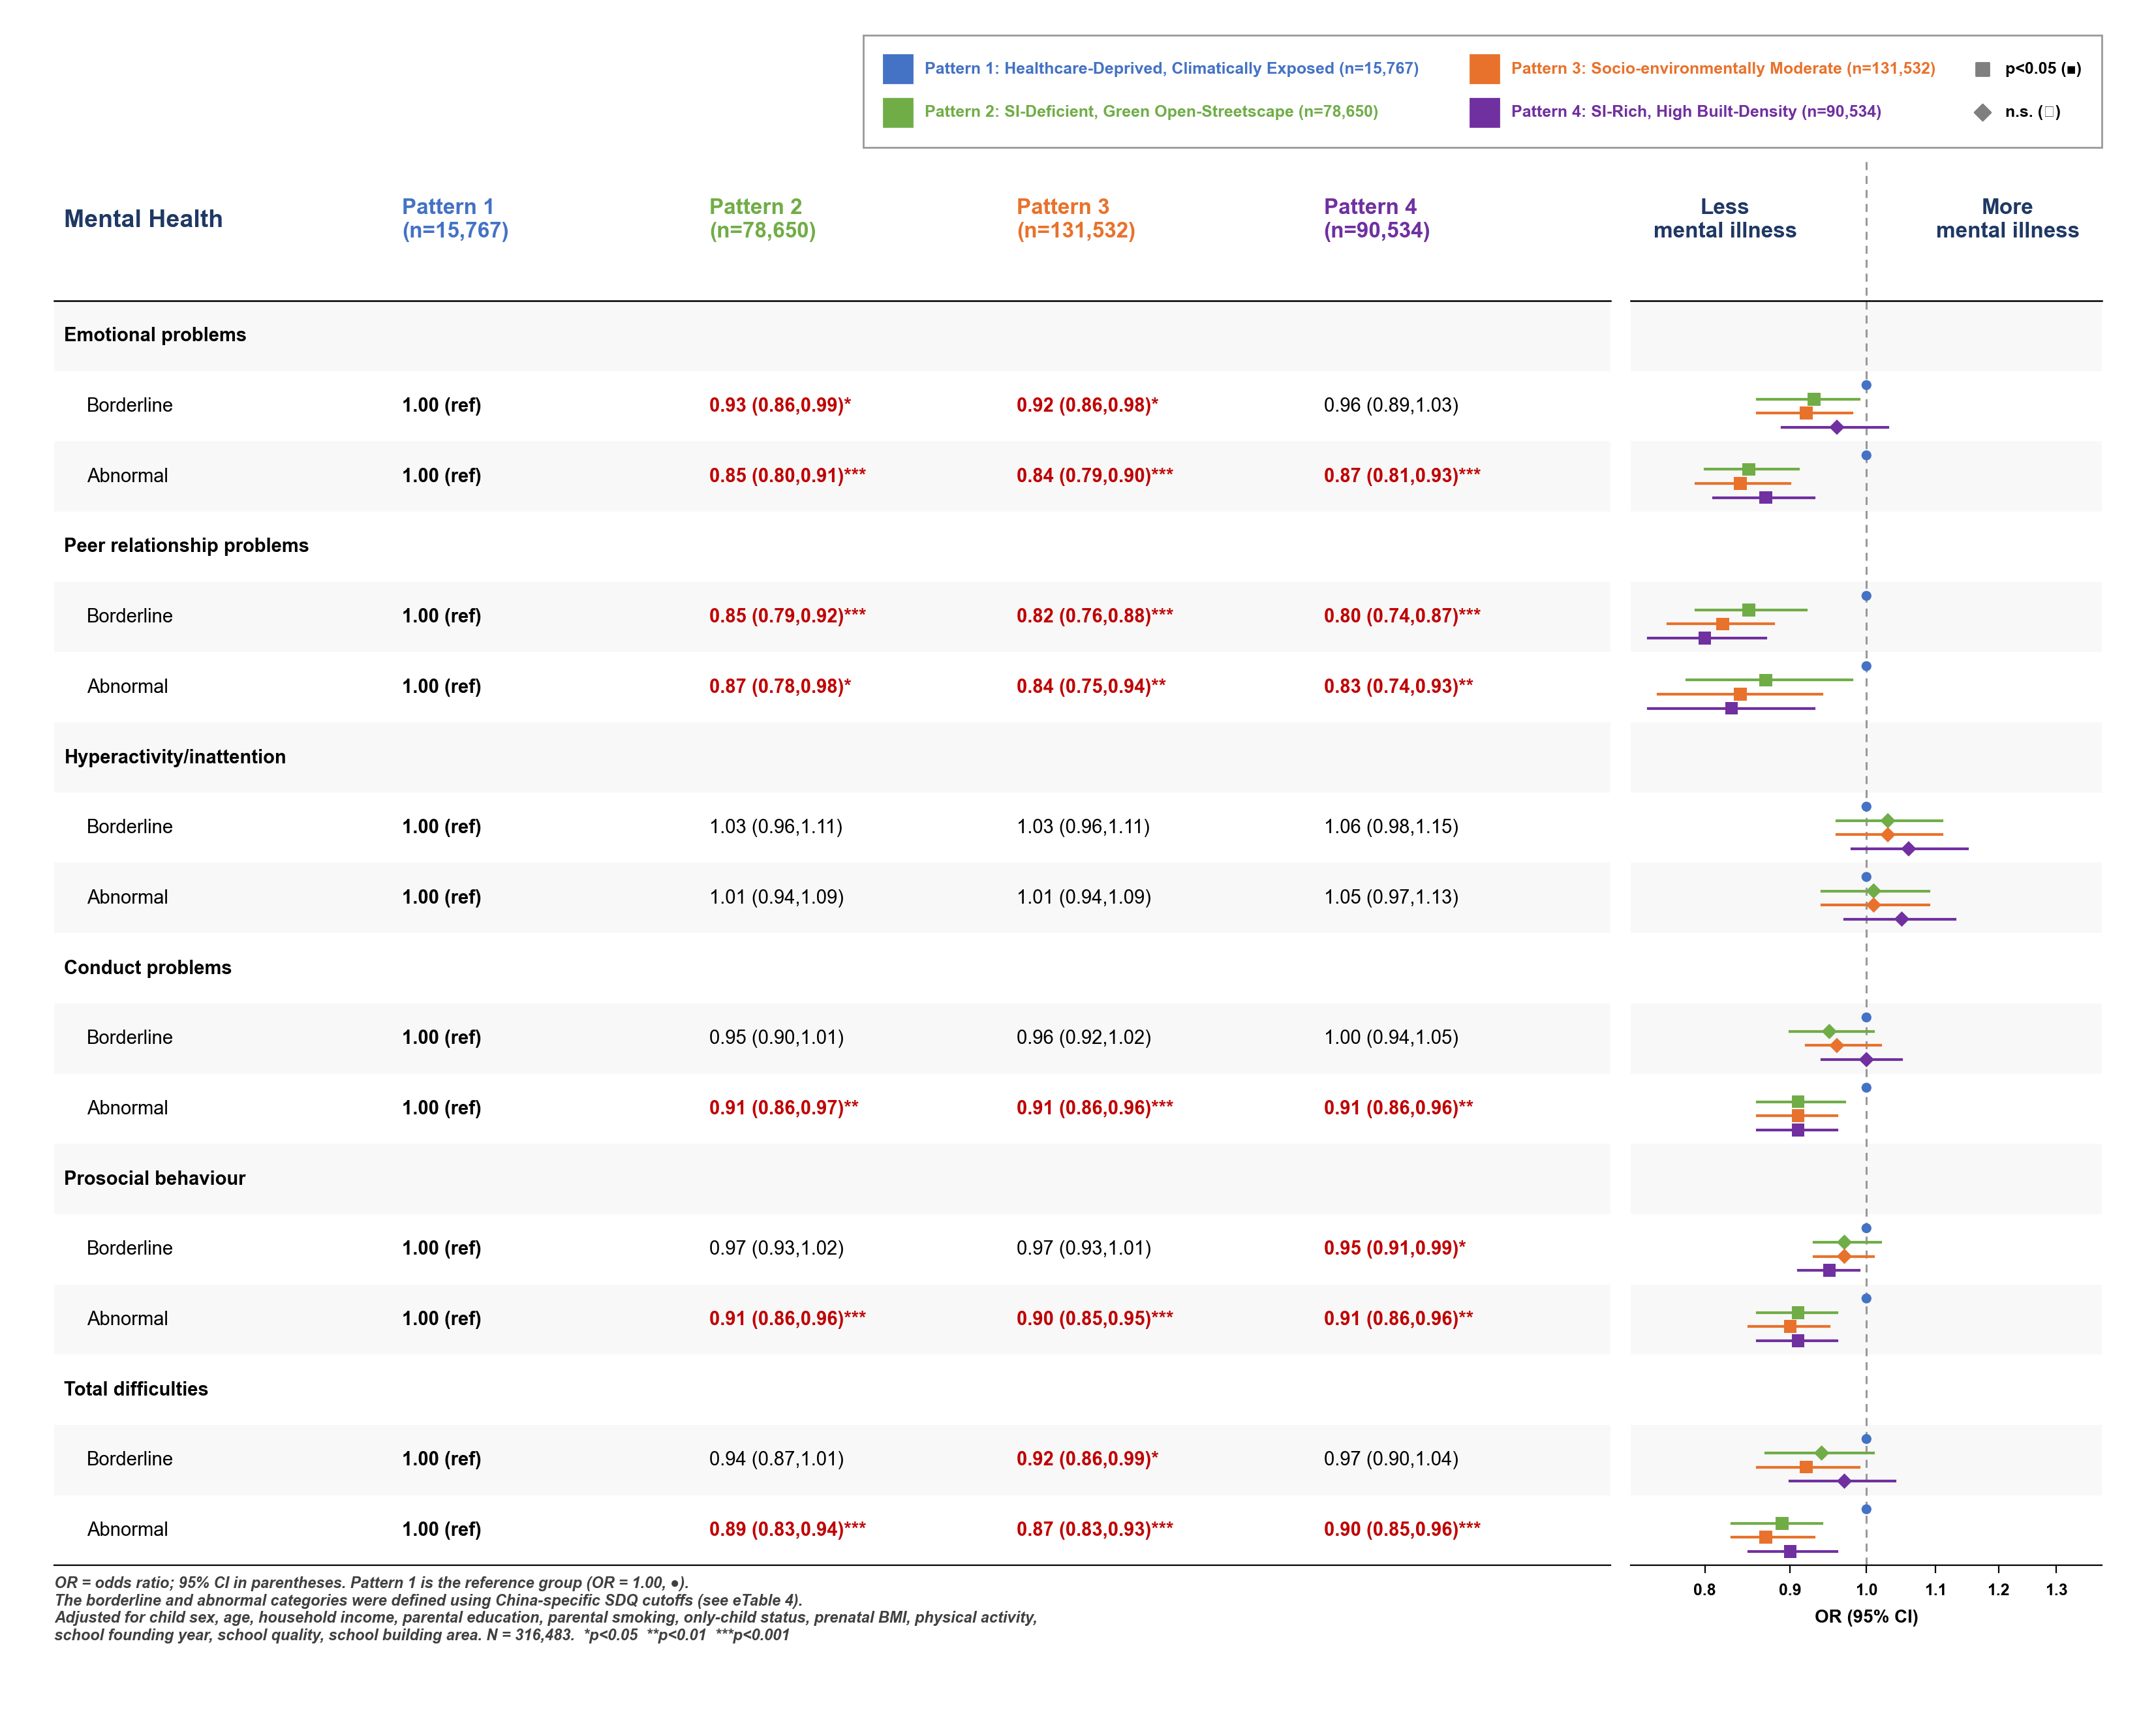

Saved: fig4_or_china_cutoffs.png


In [24]:
# ════════════════════════════════════════════════════════════════
# 21. Forest plots for Sdq ORs
#     Version A: China-specific cutoffs (6 subscales)
#     Version B: UK cutoffs (8 subscales incl. internalizing / externalizing)
# ════════════════════════════════════════════════════════════════


def plot_or_forest(rows, order, cutoff_name, out_png, n_total,
                   legend_dy=5.0, legend_right_align=False, dpi=800):

    # Pattern sizes / colours 
    PAT_N = {k: int((df_clean['cluster'] == k).sum()) for k in range(1, N_CLUSTERS + 1)}
    n1, n2, n3, n4 = PAT_N[1], PAT_N[2], PAT_N[3], PAT_N[4]

    c1, c2, c3, c4 = "#4472C4", "#70AD47", "#E8722C", "#7030A0"   
    colors = [c1, c2, c3, c4]
    navy, sig_red = "#1F3864", "#C00000"

    # Lookup: (outcome, category, pattern number) -> (OR, lo, hi, sig) 
    res = {}
    for r in rows:
        res[(r['SDQ_outcome'], r['Category'], r['Pattern'][-1])] = (r['OR'], r['CI_lo'], r['CI_hi'], r['sig'])

    # Display rows
    disp = []                                   # (label, indent level, data or None)
    for lab, lvl in order:
        sub = []
        for cat in ['Borderline', 'Abnormal']:
            vals = [res.get((lab, cat, p)) for p in ['2', '3', '4']]
            if any(v is not None for v in vals):
                sub.append((cat, lvl + 1, [None] + vals))   # index 0 = Pattern 1 (reference)
        if sub:
            disp.append((lab, lvl, None))
            disp += sub
    n_rows = len(disp)
    row_h = 1.0

    # Axis range from the data (log scale, symmetric around OR = 1) 
    allv = [v for _, _, d in disp if d for t in d[1:] if t for v in (t[1], t[2])]
    m = max(abs(np.log(v)) for v in allv)
    x_hi = np.exp(m * 1.08)
    x_lo = 1 / x_hi
    cand = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.8, 2.0, 2.5]
    x_ticks = [t for t in cand if x_lo <= t <= x_hi]

    # Figure / shared axes
    fig, ax = plt.subplots(figsize=(17, (n_rows + legend_dy + 2.7) * 0.605), dpi=200)
    fig.subplots_adjust(left=0.02, right=0.98, top=0.95, bottom=0.06)

    TABLE_X0, TABLE_X1 = 0.0, 76.0
    PLOT_X0,  PLOT_X1  = 77.0, 100.0

    ax.set_xlim(-2, 102)
    ax.set_ylim(-1.9, n_rows + legend_dy + 0.8)

    name_x, indent_x = 0.5, 1.1
    col_x = [17.0, 32.0, 47.0, 62.0]

    y_legend  = n_rows + legend_dy
    y_colhead = n_rows + 1.15
    y_topline = n_rows

    # Row shading 
    for i in range(n_rows):
        y = n_rows - i - 1
        if i % 2 == 0:
            ax.add_patch(mpatches.Rectangle((TABLE_X0, y), TABLE_X1 - TABLE_X0, row_h,
                                            color="#F8F8F8", zorder=0, linewidth=0))
            ax.add_patch(mpatches.Rectangle((PLOT_X0, y), PLOT_X1 - PLOT_X0, row_h,
                                            color="#F8F8F8", zorder=0, linewidth=0))

    # Legend box 
    sw, sh = 1.4, 0.40
    y_row0, y_row1 = y_legend, y_legend - 0.62
    col1_x = 19.0
    labels = [
        (c1, f"Pattern 1: Healthcare-Deprived, Climatically Exposed (n={n1:,})"),
        (c2, f"Pattern 2: SI-Deficient, Green Open-Streetscape (n={n2:,})"),
        (c3, f"Pattern 3: Socio-environmentally Moderate (n={n3:,})"),
        (c4, f"Pattern 4: SI-Rich, High Built-Density (n={n4:,})"),
    ]
    inv = ax.transData.inverted()

    def text_x1(t):
        bbox = t.get_window_extent(renderer=fig.canvas.get_renderer())
        return inv.transform((bbox.x1, 0))[0]

    def draw_legend(dx):
        arts = []
        def item(x, y, color, text, fontsize=9.0):
            arts.append(ax.add_patch(mpatches.Rectangle((x, y - sh / 2), sw, sh, color=color, zorder=5)))
            t = ax.text(x + sw + 0.6, y, text, fontsize=fontsize, color=color,
                        fontweight="bold", va="center", ha="left", zorder=5)
            arts.append(t)
            return t
        t1 = item(col1_x + dx, y_row0, *labels[0])
        t2 = item(col1_x + dx, y_row1, *labels[1])
        fig.canvas.draw()
        col2_x = max(text_x1(t1), text_x1(t2)) + 2.5
        t3 = item(col2_x, y_row0, *labels[2])
        t4 = item(col2_x, y_row1, *labels[3])
        fig.canvas.draw()
        col3_x = max(text_x1(t3), text_x1(t4)) + 2.3
        arts.append(ax.scatter([col3_x], [y_row0], marker="s", s=55, color="#7f7f7f", zorder=5))
        t5 = ax.text(col3_x + 1.1, y_row0, "p<0.05 (\u25A0)", fontsize=9.0, color="black",
                     va="center", ha="left", zorder=5)
        arts.append(ax.scatter([col3_x], [y_row1], marker="D", s=40, color="#7f7f7f", zorder=5))
        t6 = ax.text(col3_x + 1.1, y_row1, "n.s. (\u25C6)", fontsize=9.0, color="black",
                     va="center", ha="left", zorder=5)
        arts += [t5, t6]
        fig.canvas.draw()
        box_x0 = 18.0 + dx
        box_x1 = max(text_x1(t5), text_x1(t6)) + 1.0
        box_y0, box_y1 = y_row1 - sh / 2 - 0.30, y_row0 + sh / 2 + 0.28
        arts.append(ax.add_patch(mpatches.FancyBboxPatch(
            (box_x0, box_y0), box_x1 - box_x0, box_y1 - box_y0,
            boxstyle="square,pad=0", linewidth=1.0,
            edgecolor="#999999", facecolor="white", zorder=3.5)))
        return arts, box_x1

    arts, right_edge = draw_legend(0.0)
    if legend_right_align:
        for a in arts:
            a.remove()
        draw_legend(PLOT_X1 - right_edge)

    # Column headers 
    ax.text(name_x, y_colhead, "Mental Health", fontsize=13.5, fontweight="bold",
            color=navy, va="center", ha="left")
    col_labels = [f"Pattern 1\n(n={n1:,})", f"Pattern 2\n(n={n2:,})",
                  f"Pattern 3\n(n={n3:,})", f"Pattern 4\n(n={n4:,})"]
    for cx, lbl, col in zip(col_x, col_labels, colors):
        ax.text(cx, y_colhead, lbl, color=col, fontsize=12.0, fontweight="bold",
                va="center", ha="left")
    ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.20, y_colhead, "Less\nmental illness",
            fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")
    ax.text(PLOT_X0 + (PLOT_X1 - PLOT_X0) * 0.80, y_colhead, "More\nmental illness",
            fontsize=12.0, fontweight="bold", color=navy, ha="center", va="center")

    ax.plot([TABLE_X0, TABLE_X1], [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)
    ax.plot([PLOT_X0, PLOT_X1],   [y_topline, y_topline], color="black", linewidth=0.9, zorder=4)

    # Table rows
    for i, (lab, lvl, d) in enumerate(disp):
        yc = n_rows - i - 1 + 0.5
        ax.text(name_x + indent_x * lvl, yc, lab, fontsize=10.5, va="center", ha="left", zorder=2,
                color="black", fontweight="bold" if d is None else "normal")
        if d is None:
            continue
        ax.text(col_x[0], yc, "1.00 (ref)", fontsize=10.5, color="black",
                va="center", ha="left", zorder=2)
        for j in range(1, 4):
            t = d[j]
            if t is None:
                ax.text(col_x[j], yc, "NA", fontsize=10.5, va="center", ha="left", zorder=2)
                continue
            orr, lo, hi, stars = t
            sig = len(stars) > 0
            ax.text(col_x[j], yc, f"{orr:.2f} ({lo:.2f},{hi:.2f}){stars}", fontsize=10.5,
                    color=sig_red if sig else "black", fontweight="bold" if sig else "normal",
                    va="center", ha="left", zorder=2)

    ax.plot([TABLE_X0, TABLE_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

    # Forest plot (log scale, null at OR = 1) 
    def to_plot_x(v):
        v = min(max(v, x_lo), x_hi)             # clip CI at the axis limits
        return PLOT_X0 + (np.log(v) - np.log(x_lo)) / (np.log(x_hi) - np.log(x_lo)) * (PLOT_X1 - PLOT_X0)

    zero_x = to_plot_x(1.0)
    ax.plot([zero_x, zero_x], [0, y_colhead + 0.9], color="#999999",
            linestyle=(0, (4, 3)), linewidth=1.1, zorder=1)
    ax.plot([PLOT_X0, PLOT_X1], [0, 0], color="black", linewidth=0.8, zorder=4)

    offsets = [0.3, 0.1, -0.1, -0.3]
    for i, (lab, lvl, d) in enumerate(disp):
        if d is None:
            continue
        yc = n_rows - i - 1 + 0.5
        ax.scatter([zero_x], [yc + offsets[0]], color=c1, marker="o", s=30, zorder=4, edgecolor="none")  # reference
        for j in range(1, 4):
            t = d[j]
            if t is None:
                continue
            orr, lo, hi, stars = t
            sig = len(stars) > 0
            yy = yc + offsets[j]
            ax.plot([to_plot_x(lo), to_plot_x(hi)], [yy, yy], color=colors[j], linewidth=1.5, zorder=3)
            ax.scatter([to_plot_x(orr)], [yy], color=colors[j], marker="s" if sig else "D",
                       s=50 if sig else 36, zorder=4, edgecolor="none")

    for xt in x_ticks:
        px = to_plot_x(xt)
        ax.plot([px, px], [0, -0.1], color="black", linewidth=0.8, zorder=4)
        ax.text(px, -0.25, f"{xt:.1f}", fontsize=9, ha="center", va="top")
    ax.text((PLOT_X0 + PLOT_X1) / 2, -0.62, "OR (95% CI)", fontsize=10, ha="center", va="top")

    # Footnote 
    ax.text(TABLE_X0, -0.15,
            "OR = odds ratio; 95% CI in parentheses. Pattern 1 is the reference group (OR = 1.00, \u25CF)."
            f"\nThe borderline and abnormal categories were defined using {cutoff_name} SDQ cutoffs (see eTable 4)."
            "\nAdjusted for child sex, age, household income, parental education, parental smoking, only-child status, prenatal BMI, physical activity,"
            f"\nschool founding year, school quality, school building area. N = {n_total:,}.  *p<0.05  **p<0.01  ***p<0.001",
            fontsize=8.5, va="top", ha="left", style="italic", color="#404040")

    ax.axis("off")
    plt.savefig(out_png, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"Saved: {out_png}")


# Display order (label, header indent level) 
order_A = [("Emotional problems", 0), ("Peer relationship problems", 0), ("Hyperactivity/inattention", 0),
           ("Conduct problems", 0), ("Prosocial behaviour", 0), ("Total difficulties", 0)]

# Version A: China cutoffs
plot_or_forest(rows_a, order_A, 'China-specific', 'fig4_or_china_cutoffs.png', len(_df_or), legend_dy=3.3, legend_right_align=True)

  Saved Sdq_OR_uk_cutoffs_wide.csv  (N rows=16)


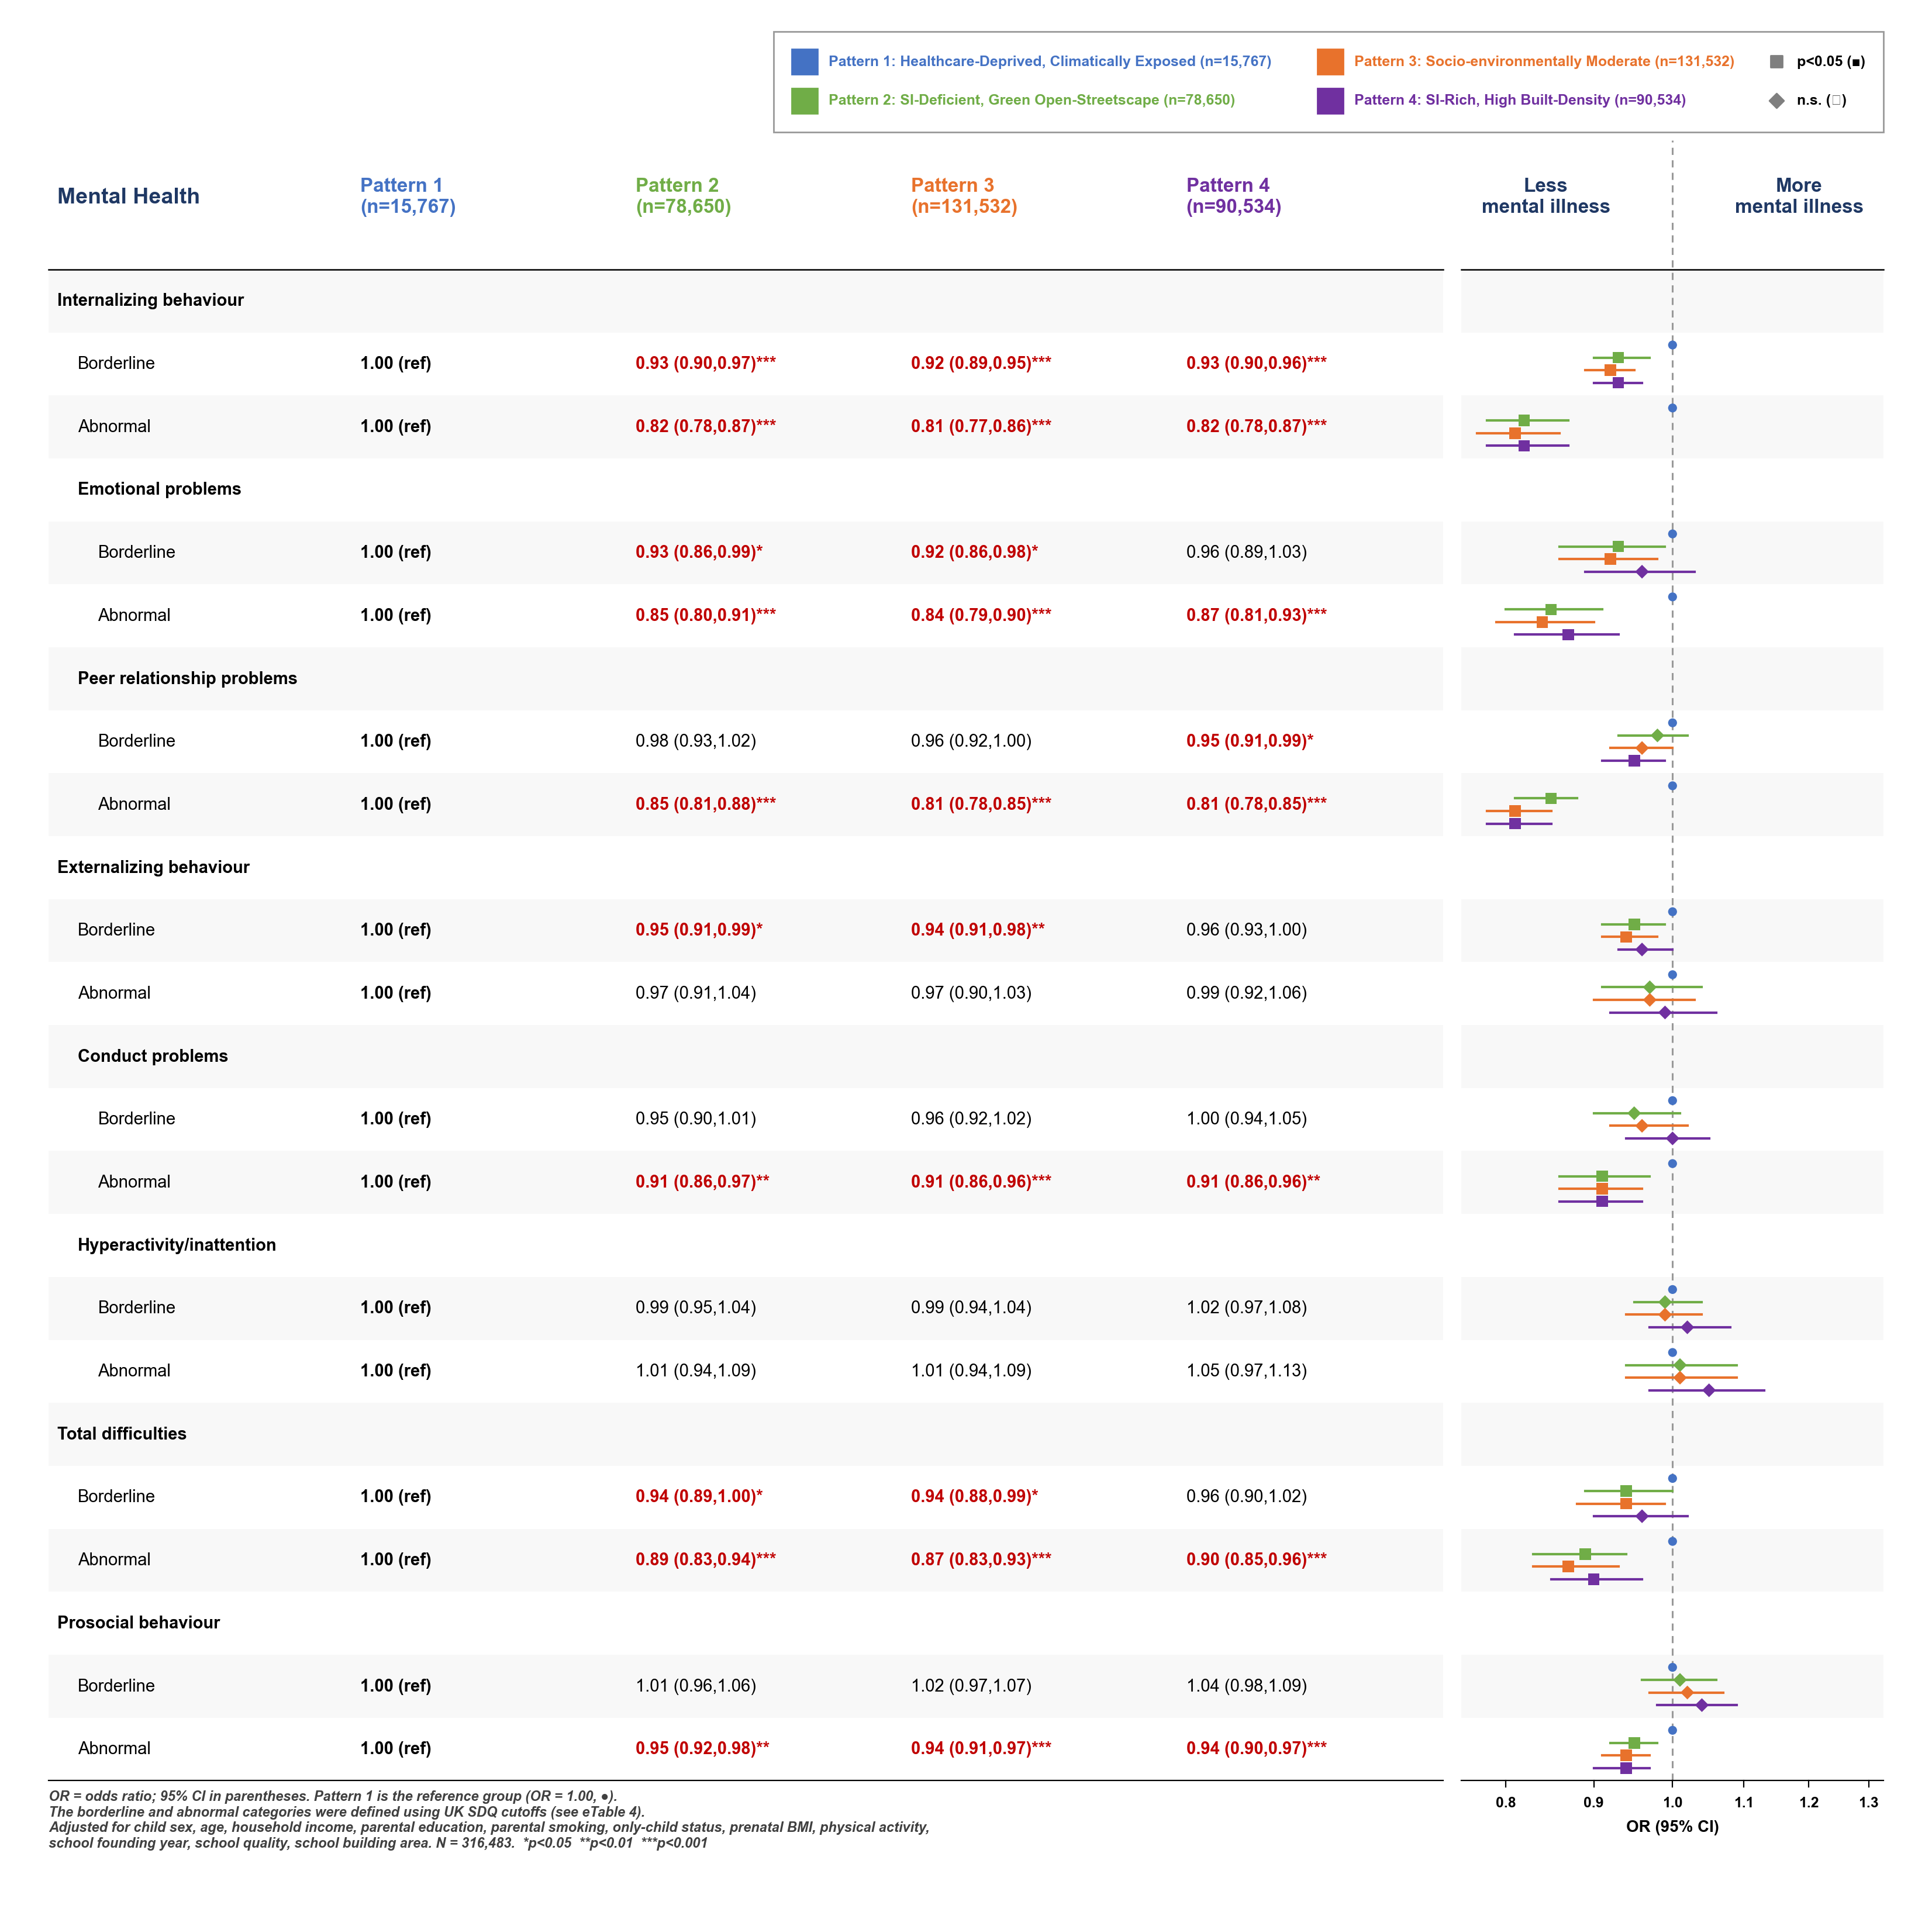

Saved: efig8_or_uk_cutoffs.png


In [25]:
# Display order (label, header indent level) 
order_B = [("Internalizing behaviour", 0), ("Emotional problems", 1), ("Peer relationship problems", 1),
           ("Externalizing behaviour", 0), ("Conduct problems", 1), ("Hyperactivity/inattention", 1),
           ("Total difficulties", 0), ("Prosocial behaviour", 0)]

# Version B: UK cutoffs
rows_b = _run_or_table(_df_or, SDQ_CUTOFFS_UK, label='B_UK_cutoffs')
_pivot_table3(rows_b, SDQ_CUTOFFS_UK, 'uk_cutoffs')
plot_or_forest(rows_b, order_B, 'UK', 'efig8_or_uk_cutoffs.png', len(_df_or), legend_dy=3.3, legend_right_align=True)

In [26]:
# ════════════════════════════════════════════════════════════════
# 22. Supplementary Table 6: Prevalence (%) of SDQ difficulties (borderline or abnormal) by pattern
# ════════════════════════════════════════════════════════════════
print("\nGenerating prevalence tables by cutoff...")

_df_prev = df_lmm_sch.copy()          # full sample with 'cluster' (1-4)
_pat_n   = {k: int((_df_prev['cluster'] == k).sum()) for k in [1, 2, 3, 4]}

# Row order as in eTable 6
_ORDER_CN = ['emo_score', 'peer_score', 'cond_score', 'hyp_score', 'pros_score', 'total_score']
_ORDER_UK = ['emo_score', 'peer_score', 'int_score', 'cond_score', 'hyp_score',
             'ext_score', 'pros_score', 'total_score']

def _prevalence_rows(df_in, cutoff_list, order, cutoff_name):
    """% in borderline-or-abnormal range per pattern.
    Normal SDQ scales: score >= borderline cut-off.
    Prosocial (reverse-scored, rev=True): score <= borderline cut-off.
    Denominator = patients in that pattern with a non-missing score."""
    cl = {c[0]: c for c in cutoff_list}
    rows = []
    for out in order:
        if out not in cl or out not in df_in.columns:
            continue
        _, lbl, bl, abn, rev = cl[out]
        row = {'Cutoff': cutoff_name, 'SDQ Dimension': lbl,
               'Borderline cut-off': bl, 'Abnormal cut-off': abn}
        for k in [1, 2, 3, 4]:
            s    = df_in.loc[df_in['cluster'] == k, out].dropna()
            flag = (s <= bl) if rev else (s >= bl)
            row[f'Pattern {k} n']     = int(len(s))
            row[f'Pattern {k} cases'] = int(flag.sum())
            row[f'Pattern {k} %']     = round(100 * flag.mean(), 1) if len(s) else np.nan
        rows.append(row)
    return rows

_prev_rows = (_prevalence_rows(_df_prev, SDQ_CUTOFFS_CN, _ORDER_CN, 'China cut-offs') +
              _prevalence_rows(_df_prev, SDQ_CUTOFFS_UK, _ORDER_UK, 'UK cut-offs'))
_df_prev_long = pd.DataFrame(_prev_rows)
_df_prev_long.to_csv('eTable6_Sdq_prevalence_by_pattern_long.csv', index=False)

print("  Saved: eTable6_Sdq_prevalence_by_pattern.csv ")
_df_prev_long


Generating prevalence tables by cutoff...
  Saved: eTable6_Sdq_prevalence_by_pattern.csv 


,Cutoff,SDQ Dimension,Borderline cut-off,Abnormal cut-off,Pattern 1 n,Pattern 1 cases,Pattern 1 %,Pattern 2 n,Pattern 2 cases,Pattern 2 %,Pattern 3 n,Pattern 3 cases,Pattern 3 %,Pattern 4 n,Pattern 4 cases,Pattern 4 %
0,China cut-offs,Emotional problems,4,5,15767,2334,14.8,78650,9784,12.4,131532,16196,12.3,90534,11276,12.5
1,China cut-offs,Peer relationship problems,5,6,15767,1298,8.2,78650,4982,6.3,131532,7929,6.0,90534,5034,5.6
2,China cut-offs,Conduct problems,3,4,15767,3435,21.8,78650,15667,19.9,131532,26606,20.2,90534,18739,20.7
3,China cut-offs,Hyperactivity/inattention,7,8,15767,1841,11.7,78650,8912,11.3,131532,14866,11.3,90534,10384,11.5
4,China cut-offs,Prosocial behaviour,5,4,15767,5254,33.3,78650,23639,30.1,131532,38913,29.6,90534,25615,28.3
5,China cut-offs,Total difficulties,15,17,15767,2446,15.5,78650,10197,13.0,131532,16691,12.7,90534,11440,12.6
6,UK cut-offs,Emotional problems,4,5,15767,2334,14.8,78650,9784,12.4,131532,16196,12.3,90534,11276,12.5
7,UK cut-offs,Peer relationship problems,3,4,15767,6761,42.9,78650,28615,36.4,131532,46011,35.0,90534,29487,32.6
8,UK cut-offs,Internalizing behaviour,4,8,15767,7859,49.8,78650,34301,43.6,131532,56060,42.6,90534,37565,41.5
9,UK cut-offs,Conduct problems,3,4,15767,3435,21.8,78650,15667,19.9,131532,26606,20.2,90534,18739,20.7
